# Fast-SAM-3D-Body -- evaluation on REHAB24-6
the training-free acceleration version of SAM 3D Body.

This notebook reimplements that one function against
`SAM3DBodyEstimator.process_one_image()` and **keeps the same function name**,
so the batch loop, the resumable full-dataset run, all analysis tables and all
figure cells are inherited without edits.

## What exactly is evaluated

**Fast-SAM-3D-Body with the configuration recorded in the export manifest** —
the upstream acceleration settings prune intermediate
predictions and disable MHR correctives, among others, so this is
similar to an unmodified SAM 3D Body teacher run. The procedure choices are
recorded and measured rather than assumed (Cell 12b): per-video vs per-frame
camera intrinsics (the intrinsics condition the network, so they can change 3D
pose, not just 2D), and full vs body-only inference.

## Scope caveat on the speedup claim

One of its three levers is
parallelising **multi-person crops within a frame**. REHAB24-6 is
single-person, so that lever contributes ~nothing here. The levers that do
apply are architecture pruning, the feedforward mesh-to-SMPL mapping, and
TensorRT. **Expect a materially smaller speedup and report it as the
single-person subset of their gains, not as a failed replication.**


In [ ]:
import warnings
import logging

# Suppress the specific 'half' deprecation warning
warnings.filterwarnings('ignore', message=".*'half' is deprecated.*")

# Suppress potential Ultralytics YOLO warnings that might bypass standard warnings
logging.getLogger('ultralytics').setLevel(logging.ERROR)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# Cell 1 - Dependencies
# ============================================================
# Package list from facebookresearch/sam-3d-body INSTALL.md, which
# Fast-SAM-3D-Body's setup_env.sh reproduces before adding its extras.
#
#
# CRITICAL  = imported at module scope by sam_3d_body; the notebook cannot run
#             without them, so a failure here stops the cell.
# OPTIONAL  = training/logging/eval-tooling extras and known-fragile legacy
#             builds. Best-effort: a failure is reported and ignored.
import subprocess, sys, importlib

CRITICAL = [
    "hydra-core", "pyrootutils", "roma", "pytorch-lightning", "yacs", "dill",
    "loguru", "optree", "fvcore", "timm", "einops", "rich", "huggingface_hub",
    "scikit-image", "webdataset", "opencv-python", "omegaconf",
    "ultralytics", "smplx", "scipy", "tqdm", "trimesh", "pandas",
]

# Each of these is either (a) not on the inference path, or (b) a legacy
# setup.py build that breaks against modern numpy. `chump` and `xtcocotools`
# are the usual culprits for the egg_info failure; neither is needed to run
# keypoint inference. chumpy is numpy<2 and is only used for SMPL .pkl loading
# (the mhr2smpl path), which this keypoint-based evaluation never calls.
OPTIONAL = [
    "pyrender", "hydra-submitit-launcher", "hydra-colorlog", "joblib",
    "seaborn", "wandb", "appdirs", "cython", "jsonlines", "pycocotools",
    "xtcocotools", "tensorboard", "chump", "pyzmq",
]

def _install(pkgs, extra=()):
    failed = []
    for p in pkgs:
        r = subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *extra, p],
            capture_output=True, text=True)
        if r.returncode != 0:
            failed.append(p)
            tail = (r.stderr or r.stdout).strip().splitlines()
            print(f"  [fail] {p}: {tail[-1][:110] if tail else 'unknown error'}")
        else:
            print(f"  [ok]   {p}")
    return failed

print("=== CRITICAL ===")
crit_failed = _install(CRITICAL)
print("\n=== OPTIONAL (failures are tolerated) ===")
opt_failed = _install(OPTIONAL)

print("\n=== MoGe (FOV estimator) ===")
mo = _install(["git+https://github.com/microsoft/MoGe.git"])

print("\n=== chumpy (SMPL .pkl only; not used by this notebook) ===")
chumpy_failed = _install(["chumpy"], extra=("--no-build-isolation",))

# NOT installed, deliberately:
#   detectron2   -- NOT needed, but the reason is subtler than "we use yolo".
#                   tools/build_detector.py does import it lazily, BUT
#                   sam_3d_body/visualization/utils.py imports
#                   `detectron2.config.LazyConfig` at MODULE scope, and
#                   notebook/utils.py pulls that in. Cell 3 therefore does NOT
#                   import notebook.utils: it builds the estimator directly from
#                   build_models + build_detector + build_fov_estimator, all of
#                   which are detectron2-free at module scope. That also avoids
#                   pyrender/EGL, which headless Colab cannot satisfy.
#   torch pin    -- setup_env.sh pins torch==2.5.1+cu124; Colab's own build is
#                   left alone. See the version warning printed below.
#   networkx==3.2.1 -- upstream pins this, but forcing a DOWNGRADE on a modern
#                   Colab risks breaking torch's own dependency. Not pinned
#                   here. If you hit a networkx-related error inside
#                   sam_3d_body, install the pin manually and restart.
#   tensorrt-*, pyrealsense2, decord, psutil, appnope -- off the default path.

# ---- verify what actually matters: the imports, not pip's exit codes ----
print("\n=== import check ===")
missing = []
for m in ["pytorch_lightning", "hydra", "omegaconf", "pyrootutils", "roma",
          "timm", "einops", "yacs", "skimage", "ultralytics", "smplx",
          "trimesh", "huggingface_hub", "cv2", "numpy", "scipy", "pandas",
          "dill", "loguru", "fvcore", "webdataset"]:
    try:
        importlib.import_module(m)
    except Exception as e:
        missing.append(f"{m} ({type(e).__name__})")

import numpy, torch
print(f"\ntorch {torch.__version__} | numpy {numpy.__version__}")
if torch.__version__ < "2.5":
    print("[warn] torch is older than the 2.5.1 setup_env.sh pins.")
print("[note] setup_env.sh pins torch==2.5.1+cu124. You are on a different build;")
print("       torch.compile behaviour and kernel selection vary between releases,")
print("       so record this version with any runtime number you report.")

if missing:
    print("\n[ERROR] still missing after install: " + ", ".join(missing))
    print("These are imported at module scope by sam_3d_body -- Cell 3 WILL fail.")
    print("Install them individually and re-run this cell.")
    raise SystemExit("critical dependencies missing")
print("\nimport check: ALL OK")

if opt_failed or chumpy_failed:
    print(f"\n[info] optional packages that failed (safe to ignore): "
          f"{', '.join(opt_failed + chumpy_failed)}")
    print("       None of these are on the keypoint-inference path. chumpy in")
    print("       particular is numpy<2 and is only needed for SMPL .pkl loading.")
if crit_failed:
    print(f"\n[warn] pip reported failures for critical packages "
          f"{', '.join(crit_failed)} but they import fine -- already satisfied.")


=== CRITICAL ===
  [ok]   hydra-core
  [ok]   pyrootutils
  [ok]   roma
  [ok]   pytorch-lightning
  [ok]   yacs
  [ok]   dill
  [ok]   loguru
  [ok]   optree
  [ok]   fvcore
  [ok]   timm
  [ok]   einops
  [ok]   rich
  [ok]   huggingface_hub
  [ok]   scikit-image
  [ok]   webdataset
  [ok]   opencv-python
  [ok]   omegaconf
  [ok]   ultralytics
  [ok]   smplx
  [ok]   scipy
  [ok]   tqdm
  [ok]   trimesh
  [ok]   pandas

=== OPTIONAL (failures are tolerated) ===
  [ok]   pyrender
  [ok]   hydra-submitit-launcher
  [ok]   hydra-colorlog
  [ok]   joblib
  [ok]   seaborn
  [ok]   wandb
  [ok]   appdirs
  [ok]   cython
  [ok]   jsonlines
  [ok]   pycocotools
  [fail] xtcocotools: hint: See above for details.
  [ok]   tensorboard
  [ok]   chump
  [ok]   pyzmq

=== MoGe (FOV estimator) ===
  [ok]   git+https://github.com/microsoft/MoGe.git

=== chumpy (SMPL .pkl only; not used by this notebook) ===
  [ok]   chumpy

=== import check ===

torch 2.11.0+cu128 | numpy 2.1.3
[note] setup_env.sh 

## Get the Fast-SAM-3D-Body code + weights, then mount REHAB24-6 from Drive

Layout this notebook expects:

```
/content/
  fast_sam_3d_body/                    # <- git clone, Cell 2a
    sam_3d_body/ notebook/ tools/ checkpoints/
  drive/MyDrive/REHAB/                 # <- unchanged from the InstantHMR notebook
    videos/Ex1/PM_109-Camera17-30fps.mp4
    2d_joints/Ex1/PM_109-c17-30fps.npy
    3d_joints/Ex1/PM_109-30fps.npy
    Segmentation.csv
```

The dataset folder is **identical** to the one the InstantHMR notebook used --
if it is already in your Drive, there is nothing to re-upload.

### Model weights are GATED

`facebook/sam-3d-body-dinov3` requires **approved access**. Open the model
page on HuggingFace, request access, and wait for approval — being logged in is
not sufficient while the request is still pending. Upstream notes access is
refused in comprehensively sanctioned jurisdictions.

Cell 2d handles the login itself. The cleanest way to give it a token on Colab
is **Secrets** (key icon in the left sidebar → add `HF_TOKEN`, enable *Notebook
access*): it survives restarts and keeps the token out of the notebook and its
output. Otherwise the cell falls back to a cached login, then to an interactive
prompt.

Cell 2d downloads into `checkpoints/sam-3d-body-dinov3/` (`model.ckpt`,
`model_config.yaml`, `assets/mhr_model.pt`) and Cell 3 loads from there. YOLO
detector weights (`yolo11n.pt`) are fetched automatically by ultralytics.

**Dependency note:** Cell 1 installs packages one at a time on purpose. A
single `pip install` of the whole list fails all-or-nothing, because pip
resolves every package's metadata before installing any of them -- so one
legacy `setup.py` aborts the batch and silently leaves module-scope imports
like `hydra-core` missing. Optional packages are allowed to fail; critical
ones stop the cell.


In [ ]:
# ============================================================
# Cell 2a - Clone Fast-SAM-3D-Body
# ============================================================
import os, sys

REPO_DIR = "/content/fast_sam_3d_body"
if not os.path.isdir(REPO_DIR):
    !git clone -q https://github.com/yangtiming/Fast-SAM-3D-Body {REPO_DIR}

# `notebook.utils` and `tools.*` are imported as TOP-LEVEL packages by the repo,
# so the repo root must be on sys.path AND be the cwd, or its relative
# ./checkpoints and ./data paths will not resolve.
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
os.chdir(REPO_DIR)
print("cwd:", os.getcwd())


cwd: /content/fast_sam_3d_body


In [ ]:
# ============================================================
# Cell 2b - Acceleration configuration (MUST run BEFORE importing sam_3d_body)
# ============================================================
# The repo configures its fast path through ENVIRONMENT VARIABLES read at
# import / estimator-construction time. This cell reads them DIRECTLY from the
# cloned run_demo.sh -- the authors' own launch script -- rather than from a
# hand-copied list.
#
# Why parse instead of transcribe: an earlier version of this cell hand-copied
# 7 variables from a summarised read of run_demo.sh, which actually exports 22.
# The 15 it missed included USE_COMPILE_BACKBONE, DECODER_COMPILE,
# COMPILE_MODE=reduce-overhead and SKIP_KEYPOINT_PROMPT -- i.e. most of the
# acceleration. That run measured ~378 ms/frame on an A100 while being labelled
# Fast-SAM-3D-Body. Parsing the script makes that class of error impossible and
# keeps this notebook in sync if the repo changes its defaults.
import os, re, sys, json, hashlib

# ---- guard: env vars set AFTER import are silently ignored ----------------
if "sam_3d_body" in sys.modules:
    raise SystemExit(
        "sam_3d_body is ALREADY imported in this session, so the settings below "
        "would NOT take effect and you would silently benchmark the old config.\n"
        "Runtime > Restart session, then run again starting from Cell 2a.")

RUN_DEMO = "/content/fast_sam_3d_body/run_demo.sh"

# Never import these from a shell script -- they are machine/session specific.
_NEVER_APPLY = {"PATH", "LD_LIBRARY_PATH", "PYTHONPATH", "CUDA_HOME",
                "CUDA_VISIBLE_DEVICES", "HF_TOKEN", "HF_HOME"}

# Shell semantics: an UNQUOTED value ends at the first whitespace, and `#`
# after whitespace starts a comment. run_demo.sh relies on that -- almost every
# line is `export USE_COMPILE=1                # Enable torch.compile`. A naive
# `=(.*)$` capture would store "1                # Enable torch.compile", and
# since the repo gates on `os.environ.get('USE_COMPILE','0') != '1'`, that
# would silently DISABLE compilation. So capture a quoted string or a single
# whitespace-free token, nothing more. Lines starting with `#` (commented-out
# exports) never match because of the leading `^\s*export`.
_EXPORT_RE = re.compile(
    r"""^\s*export\s+([A-Za-z_][A-Za-z0-9_]*)=("[^"]*"|'[^']*'|[^\s#]*)""")

def _read_exports(path):
    cfg, skipped = {}, []
    for line in open(path, encoding="utf-8"):
        m = _EXPORT_RE.match(line)
        if not m:
            continue
        k, v = m.group(1), m.group(2)
        if len(v) >= 2 and v[0] == v[-1] and v[0] in "\"'":
            v = v[1:-1]
        if k in _NEVER_APPLY or "$" in v:        # skip shell expansions too
            skipped.append(k)
            continue
        cfg[k] = v
    return cfg, skipped

ACCEL_CONFIG, _skipped = _read_exports(RUN_DEMO)
assert len(ACCEL_CONFIG) >= 15, (
    f"only parsed {len(ACCEL_CONFIG)} exports from {RUN_DEMO} -- expected ~22. "
    f"Inspect the file before trusting any runtime number.")
# Guard against the comment-capture bug ever coming back: every value in this
# script is a flag, a number, a size letter, a layer list or a compile mode.
_bad = {k: v for k, v in ACCEL_CONFIG.items() if not re.fullmatch(r"[\w.,/:-]*", v)}
assert not _bad, f"unparsed junk in values (comment captured?): {_bad}"
# The gating flags the repo compares against the literal string "1":
for _k in ("USE_COMPILE", "USE_COMPILE_BACKBONE", "DECODER_COMPILE"):
    assert ACCEL_CONFIG.get(_k) == "1", f"{_k} = {ACCEL_CONFIG.get(_k)!r}, expected '1'"

# ---- runtime arm ----------------------------------------------------------
# USE_TRT=False: torch.compile path (default; no engine build needed).
# USE_TRT=True : TensorRT fp16 path -- requires build_tensorrt.sh to have been
#                run ON THIS SAME GPU (engines are architecture-specific).
USE_TRT = False

TRT_ENGINES = [
    "/content/fast_sam_3d_body/checkpoints/yolo/yolo11m-pose.engine",
    "/content/fast_sam_3d_body/checkpoints/moge_trt/moge_dinov2_encoder_fp16.engine",
    "/content/fast_sam_3d_body/checkpoints/sam-3d-body-dinov3/backbone_trt/backbone_dinov3_fp16.engine",
]
OVERRIDES = {}
if USE_TRT:
    _missing = [p for p in TRT_ENGINES if not os.path.exists(p)]
    if _missing:
        raise SystemExit("USE_TRT=True but engines are missing -- run build_tensorrt.sh "
                         "on this GPU first:\n  " + "\n  ".join(_missing))
    # run_demo.sh leaves backbone TRT COMMENTED OUT (`# export USE_TRT_BACKBONE=1`),
    # so the TensorRT arm has to switch it on explicitly -- otherwise "TensorRT"
    # would only cover the FOV encoder while the backbone stayed in PyTorch.
    OVERRIDES["USE_TRT_BACKBONE"] = "1"
    OVERRIDES["TRT_BACKBONE_PATH"] = TRT_ENGINES[2]
    RUNTIME_ARM_LABEL = "TensorRT fp16"
    print("[note] The paper's TRT path ALSO swaps the detector to yolo11m-pose.engine")
    print("       with hand_box_source='yolo_pose'. That changes detection (and so")
    print("       accuracy), not just speed -- set DETECTOR_NAME/DETECTOR_MODEL/")
    print("       HAND_BOX_SOURCE in Cell 3 deliberately if you want that config.")
else:
    # run_demo.sh sets FOV_TRT=1, which needs the MoGe TRT engine. Without it
    # the FOV estimator must run in PyTorch.
    OVERRIDES["FOV_TRT"] = "0"
    RUNTIME_ARM_LABEL = "torch.compile (no TensorRT)"

ACCEL_CONFIG.update(OVERRIDES)
for k, v in ACCEL_CONFIG.items():
    os.environ[k] = v

# Fingerprint of the exact config -- written into every result row and checked
# before the resumable loop appends to an existing checkpoint (Cell 15c), so
# rows from different configurations can never be silently mixed.
ACCEL_HASH = hashlib.sha1(
    json.dumps({"cfg": ACCEL_CONFIG, "arm": RUNTIME_ARM_LABEL}, sort_keys=True).encode()
).hexdigest()[:10]
MODEL_TAG = "fast-sam-3d-body"

print(f"Parsed {len(ACCEL_CONFIG)} settings from {os.path.basename(RUN_DEMO)}"
      + (f" (skipped: {', '.join(_skipped)})" if _skipped else ""))
for k in sorted(ACCEL_CONFIG):
    flag = "   <- override" if k in OVERRIDES else ""
    print(f"  {k:34s}= {ACCEL_CONFIG[k]}{flag}")
print(f"\nMODEL_TAG         : {MODEL_TAG}")
print(f"RUNTIME_ARM_LABEL : {RUNTIME_ARM_LABEL}")
print(f"ACCEL_HASH        : {ACCEL_HASH}")


Parsed 22 settings from run_demo.sh
  BODY_INTERM_PRED_LAYERS           = 0,1,2
  COMPILE_MODE                      = reduce-overhead
  COMPILE_WARMUP_BATCH_SIZES        = 1
  DEBUG_BACKBONE_INPUT              = 0
  DEBUG_HAND_PREP                   = 0
  DEBUG_NAN                         = 0
  DECODER_COMPILE                   = 1
  FOV_FAST                          = 1
  FOV_LEVEL                         = 0
  FOV_MODEL                         = s
  FOV_TRT                           = 0   <- override
  GPU_HAND_PREP                     = 1
  HAND_INTERM_PRED_LAYERS           = 0,1
  IMG_SIZE                          = 512
  INTERM_TIMING                     = 0
  KEYPOINT_PROMPT_INTERM_INTERVAL   = 999
  LAYER_DTYPE                       = fp32
  MHR_NO_CORRECTIVES                = 1
  MHR_USE_CUDA_GRAPH                = 0
  SKIP_KEYPOINT_PROMPT              = 1
  USE_COMPILE                       = 1
  USE_COMPILE_BACKBONE              = 1

MODEL_TAG         : fast-sam-3d-body
RUNTI

In [ ]:
# ============================================================
# Cell 2c - Mount Google Drive (REHAB24-6 dataset persists across sessions)
# ============================================================
from google.colab import drive

drive.mount("/content/drive")

import os
REHAB_ROOT = "/content/drive/MyDrive/REHAB"
if not os.path.isdir(REHAB_ROOT):
    print(f"[error] {REHAB_ROOT} not found -- upload the rehab/ folder to "
          f"MyDrive/REHAB/ in your Google Drive before continuing (see Cell 2 markdown above).")
else:
    print(f"Found {REHAB_ROOT}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found /content/drive/MyDrive/REHAB


In [ ]:
# ============================================================
# Cell 2 - Verify the expected files are present
# ============================================================
import os

REQUIRED = [
    "/content/fast_sam_3d_body/sam_3d_body/__init__.py",
    "/content/fast_sam_3d_body/sam_3d_body/sam_3d_body_estimator.py",
    "/content/fast_sam_3d_body/sam_3d_body/build_models.py",
    "/content/drive/MyDrive/REHAB/videos/Ex1/PM_109-Camera17-30fps.mp4",
    "/content/drive/MyDrive/REHAB/videos/Ex1/PM_109-Camera18-30fps-transposed.mp4",
    "/content/drive/MyDrive/REHAB/2d_joints/Ex1/PM_109-c17-30fps.npy",
    "/content/drive/MyDrive/REHAB/2d_joints/Ex1/PM_109-c18-30fps.npy",
    "/content/drive/MyDrive/REHAB/3d_joints/Ex1/PM_109-30fps.npy",
    "/content/drive/MyDrive/REHAB/Segmentation.csv",
]
missing = [p for p in REQUIRED if not os.path.exists(p)]
if missing:
    print("MISSING - fix these before continuing:")
    for p in missing:
        print(" ", p)
else:
    print("All required files present.")

import torch
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (CPU only)"
print("\nGPU:", GPU_NAME)
print("[note] Record this GPU alongside any runtime number. The paper's ~65 ms/frame")
print("       is an RTX 5090; a Colab T4/L4/A100 figure is not comparable to it,")
print("       nor to InstantHMR numbers measured on a different card.")


All required files present.

GPU: NVIDIA A100-SXM4-40GB
[note] Record this GPU alongside any runtime number. The paper's ~65 ms/frame
       is an RTX 5090; a Colab T4/L4/A100 figure is not comparable to it,
       nor to InstantHMR numbers measured on a different card.


In [ ]:
# ============================================================
# Cell 2d - Authenticate with HuggingFace + download the GATED checkpoint
# ============================================================
# facebook/sam-3d-body-dinov3 is GATED: you must request access on the model
# page and be APPROVED before any token will work. Upstream notes access is
# refused in comprehensively sanctioned jurisdictions.
#
# Token resolution, in order (first hit wins):
#   1. HF_TOKEN environment variable
#   2. Colab Secrets  (key icon in the left sidebar -> add HF_TOKEN, enable
#      "Notebook access") -- the preferred route: it survives restarts and
#      never puts the token in the notebook or its output
#   3. an existing cached login from a previous session
#   4. interactive login() prompt
#
# Downloading EXPLICITLY, rather than letting setup_sam_3d_body() resolve by
# repo id, so the weights land on disk where they can be inspected and reused,
# and so an auth failure surfaces HERE with an actionable message instead of
# inside model construction. This is also the path demo_human.py takes
# (--local_checkpoint).
import os
from huggingface_hub import snapshot_download, login, whoami

REPO_ID  = "facebook/sam-3d-body-dinov3"
CKPT_DIR = "/content/fast_sam_3d_body/checkpoints/sam-3d-body-dinov3"

# ---- 1/2: find a token without prompting -------------------------------
HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
        if HF_TOKEN:
            print("Token source: Colab Secrets")
    except Exception:
        pass            # not on Colab, or the secret is absent / not enabled
else:
    print("Token source: HF_TOKEN environment variable")

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)

# ---- 3/4: fall back to a cached login, then to an interactive prompt ----
try:
    _user = whoami()
    print(f"Authenticated as: {_user.get('name', '<unknown>')}")
except Exception:
    print("Not authenticated yet -- opening the interactive login prompt.")
    print("Paste a token from https://huggingface.co/settings/tokens (read scope).")
    login()                                   # interactive widget
    _user = whoami()                          # raises if it still did not work
    print(f"Authenticated as: {_user.get('name', '<unknown>')}")

# ---- download ----------------------------------------------------------
print(f"\nDownloading {REPO_ID} -> {CKPT_DIR}")
try:
    snapshot_download(repo_id=REPO_ID, local_dir=CKPT_DIR, token=HF_TOKEN or True)
except Exception as e:
    msg = f"{type(e).__name__}: {e}"
    print(f"\n[ERROR] download failed -- {msg[:400]}")
    if any(s in msg for s in ("401", "403", "Gated", "gated", "awaiting", "Access")):
        print("\nThis is an ACCESS problem, not a code problem. Check, in order:")
        print(f"  1. Open https://huggingface.co/{REPO_ID} and request access.")
        print("  2. Wait for the request to be APPROVED -- being logged in is not")
        print("     enough while the request is still pending.")
        print("  3. Make sure the token above belongs to the SAME account that was")
        print("     granted access, and has at least 'read' scope.")
    raise

# ---- verify the layout setup_sam_3d_body() expects ---------------------
#   checkpoints/sam-3d-body-dinov3/model.ckpt
#                                 /model_config.yaml
#                                 /assets/mhr_model.pt
print(f"\n{CKPT_DIR}")
_all_ok = True
for _f in ("model.ckpt", "model_config.yaml", os.path.join("assets", "mhr_model.pt")):
    _p = os.path.join(CKPT_DIR, _f)
    _ok = os.path.exists(_p)
    _all_ok &= _ok
    _sz = f"{os.path.getsize(_p)/1e6:.0f} MB" if _ok else "-"
    print(f"  {'OK     ' if _ok else 'MISSING'}  {_f:34s} {_sz}")

if not _all_ok:
    print("\n[ERROR] that layout is what setup_sam_3d_body() expects. The repo may")
    print("  publish these under different names -- inspect what actually arrived:")
    for _root, _dirs, _files in os.walk(CKPT_DIR):
        for _f in _files:
            _rel = os.path.relpath(os.path.join(_root, _f), CKPT_DIR)
            print(f"    {_rel}")
    raise SystemExit("checkpoint layout does not match what Cell 3 will load")
print("\nCheckpoint ready.")


Authenticated as: LudaML



Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]


/content/fast_sam_3d_body/checkpoints/sam-3d-body-dinov3
  OK       model.ckpt                         2109 MB
  OK       model_config.yaml                  0 MB
  OK       assets/mhr_model.pt                696 MB

Checkpoint ready.


In [ ]:
%%writefile /content/fastsam_infer.py
# Cell 2e - Shared inference module (notebook + parallel workers)
"""Shared Fast-SAM-3D-Body inference for the REHAB24-6 evaluation notebook.

Used two ways:
  * imported by the notebook (Cell 3 / Cell 6) for live inference, and
  * run as a script by the parallel-worker launcher (Cell 15w), one process
    per shard, each writing raw per-segment predictions to a prediction cache.

Keeping ONE implementation for both is the point: the cached predictions every
metric is computed from are produced by exactly the code the notebook's
walkthrough (Cell 7 overlays, Cell 3b probe) validated.

This file is written by a %%writefile cell in the notebook -- edit it THERE.
"""
from __future__ import annotations

import argparse
import contextlib
import hashlib
import io
import json
import os
import sys
import time
import traceback
from collections import deque

import cv2
import numpy as np
import torch

N_KP = 70
SCHEMA_VERSION = 2     # v2: per-frame `processed` + `track_iou`, IoU person tracking
MAX_CONSEC_FAIL = 50   # a broken CUDA context fails every frame -- stop, don't spin
PERSON_SELECT = "iou-track-v1"
TRACK_IOU_MIN = 0.1    # below this the tracked person is considered lost -> re-initialise


class WorkerAbort(RuntimeError):
    """Unrecoverable in this process (e.g. CUDA context lost). Re-run resumes."""


# ------------------------------------------------------------------- keys ----
def make_cache_key(accel_hash, fov_mode, n_calib, use_mask, hand_box_source,
                   detector_name, detector_model, hf_repo_id, fov_available,
                   inference_type="full", person_select=PERSON_SELECT):
    """Fingerprint of everything that changes the PREDICTIONS. Used as the cache
    directory name, so predictions from different configurations can never be
    mixed -- changing any of these starts a fresh cache."""
    spec = {
        "schema": SCHEMA_VERSION, "accel_hash": accel_hash, "fov_mode": fov_mode,
        "n_calib": int(n_calib), "use_mask": bool(use_mask),
        "hand_box_source": hand_box_source, "detector_name": detector_name,
        "detector_model": detector_model, "hf_repo_id": hf_repo_id,
        "fov_available": bool(fov_available), "inference_type": inference_type,
        "person_select": person_select,
    }
    return hashlib.sha1(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:10]


def video_key(video_path):
    """'<root>/Ex1/PM_109-Camera17-30fps.mp4' -> ('Ex1', 'PM_109', 'c17').
    Root-independent, so Drive and local copies map to the same cache entry."""
    exercise = os.path.basename(os.path.dirname(video_path))
    fname = os.path.basename(video_path)
    if "-Camera17" in fname:
        cam = "c17"
    elif "-Camera18" in fname:
        cam = "c18"
    else:
        raise ValueError(f"cannot tell camera from file name {fname!r}")
    return exercise, fname.split("-Camera")[0], cam


def cache_file(cache_dir, exercise, subject, cam, start, end):
    return os.path.join(cache_dir, exercise,
                        f"{subject}_{cam}_{int(start):06d}-{int(end):06d}.npz")


def calib_file(cache_dir, exercise, subject, cam):
    return os.path.join(cache_dir, "_calib", f"{exercise}_{subject}_{cam}.npy")


# ------------------------------------------------------------- video I/O ----
def open_capture_at(video_path, start_frame):
    """Returns a cv2.VideoCapture positioned so the next .read() yields frame
    `start_frame`. cv2's CAP_PROP_POS_FRAMES seek is not reliable on every
    video/codec with OpenCV's FFmpeg backend -- it can silently land on a frame
    that fails to decode. This verifies the seek actually works (on a disposable
    test capture) before trusting it, and falls back to a full sequential
    scan-and-discard from frame 0 when it doesn't (slower, but always correct)."""
    if start_frame == 0:
        return cv2.VideoCapture(video_path)

    test_cap = cv2.VideoCapture(video_path)
    test_cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    seek_ok, _ = test_cap.read()
    test_cap.release()

    cap = cv2.VideoCapture(video_path)
    if seek_ok:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
        return cap

    print(f"  [warn] fast seek to frame {start_frame} failed to decode in "
          f"{video_path} -- falling back to sequential scan from frame 0 "
          f"(slower but correct)")
    for _ in range(start_frame):
        ok, _ = cap.read()
        if not ok:
            raise RuntimeError(
                f"video ended before reaching frame {start_frame} in {video_path}")
    return cap


# --------------------------------------------------------- output parsing ----
def _as_kp_array(a, ncol):
    """Coerce a keypoint array to (K, ncol), taking the FIRST ncol columns.

    Deliberately does NOT use reshape(-1, ncol). Pose models commonly return
    2D keypoints as (K, 3) = (x, y, confidence). Reshaping a (70, 3) array to
    (-1, 2) silently yields 105 rows of interleaved garbage whose first 70
    entries still look like plausible pixel coordinates. Slicing columns is the
    only safe reading. Returns None if the array cannot be interpreted."""
    a = np.squeeze(np.asarray(a, dtype=np.float32))   # drop a leading batch dim of 1
    if a.ndim != 2 or a.shape[1] < ncol:
        return None
    return a[:, :ncol]


def _project_kp(kp3d_local, cam_t, focal, cx, cy):
    """Perspective-project body-centred joints using the model's own camera
    translation and focal length."""
    X = np.asarray(kp3d_local, dtype=np.float64) + np.asarray(cam_t, dtype=np.float64)[None, :]
    z = np.clip(X[:, 2], 1e-6, None)
    return np.stack([focal * X[:, 0] / z + cx, focal * X[:, 1] / z + cy], axis=-1)


def _bbox_iou(a, b):
    """IoU of two xyxy boxes (prepare_batch stores batch["bbox"] as xyxy)."""
    a = np.asarray(a, dtype=float).ravel()[:4]
    b = np.asarray(b, dtype=float).ravel()[:4]
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        return 0.0
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    union = (max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
             + max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1]) - inter)
    return inter / union if union > 0 else 0.0


def _pick_person(outs, prev_bbox=None):
    """Choose the participant in a frame. Returns (person_dict, track_iou).

    Picking the largest box independently in every frame has no notion of
    identity: when a second person (REHAB24 flags one in cam17 on ~36% of
    repetitions) is momentarily larger, the skeleton jumps to them and back --
    a velocity spike that inflates MPJVE. So this TRACKS: once a person is
    chosen, each next frame takes the detection overlapping the previous choice
    most (IoU). Only when nothing overlaps enough (< TRACK_IOU_MIN: the person
    was lost) does it re-initialise to the largest box. `track_iou` is NaN on
    (re-)initialisation, so re-init events stay visible per frame."""
    if not outs:
        return None, float("nan")
    if prev_bbox is not None:
        ious = [_bbox_iou(d["bbox"], prev_bbox) for d in outs]
        k = int(np.argmax(ious))
        if ious[k] >= TRACK_IOU_MIN:
            return outs[k], float(ious[k])

    def _area(d):
        b = np.asarray(d["bbox"], dtype=float).ravel()
        return float((b[2] - b[0]) * (b[3] - b[1]))
    return max(outs, key=_area), float("nan")


def extract_person(outs, prev_bbox=None):
    """-> dict(kp3d, kp2d, cam_t, focal, bbox, track_iou) for the tracked person,
    or None. `prev_bbox` is the previous choice in the SAME segment.
    A frame counts as detected when its 3D keypoints are usable; an unusable 2D
    array is stored as NaN (the notebook drops that frame for 2D metrics only
    when it actually uses the native 2D keypoints)."""
    p, track_iou = _pick_person(outs, prev_bbox)
    if p is None:
        return None
    k3 = _as_kp_array(p["pred_keypoints_3d"], 3)
    if k3 is None or k3.shape[0] < N_KP:
        return None
    k2 = _as_kp_array(p.get("pred_keypoints_2d", np.empty((0, 2))), 2)
    k2 = k2[:N_KP] if (k2 is not None and k2.shape[0] >= N_KP) else np.full((N_KP, 2), np.nan, np.float32)
    cam_t = np.ravel(p["pred_cam_t"])[:3] if "pred_cam_t" in p else np.full(3, np.nan)
    focal = float(np.ravel(p["focal_length"])[0]) if "focal_length" in p else np.nan
    bbox = np.ravel(p["bbox"])[:4] if "bbox" in p else np.full(4, np.nan)
    return {"kp3d": k3[:N_KP], "kp2d": k2, "cam_t": cam_t, "focal": focal, "bbox": bbox,
            "track_iou": track_iou}


# ------------------------------------------------------ FOV freezing -------
class FOVCache:
    """Wraps the estimator's FOV estimator so intrinsics can be FROZEN per video.

    process_one_image() calls `self.fov_estimator.get_cam_intrinsics(img)` --
    MoGe on the full frame -- for EVERY frame. The REHAB cameras are static, so
    that is repeated work, and it lets the intrinsics jitter frame to frame.

    This CHANGES THE PROCEDURE; it is not a pure speed-up. Calibration samples
    frames from across the whole video -- including frames after the one being
    processed -- before any inference, i.e. it is an offline step, and runtime
    measured with it is "after offline calibration". The intrinsics also feed
    the network's camera-ray conditioning (sam3d_body `ray_cond_emb`), so frozen
    vs per-frame intrinsics can change the predicted articulation itself, not
    just the 2D projection. The notebook's A/B cell measures that difference.
    States:
      passthrough (default) -- identical to the wrapped estimator
      collecting            -- passthrough, but records each estimate
      frozen                -- returns one fixed intrinsics tensor, no MoGe call
    """
    _is_fov_cache = True

    def __init__(self, inner):
        self.inner = inner
        self.frozen = None
        self.collecting = False
        self.collected = []

    def get_cam_intrinsics(self, *args, **kwargs):
        if self.frozen is not None:
            return self.frozen.clone()
        k = self.inner.get_cam_intrinsics(*args, **kwargs)
        if self.collecting:
            self.collected.append(k.detach().clone())
        return k

    def __getattr__(self, name):          # delegate everything else to MoGe
        if name == "inner":
            raise AttributeError(name)
        return getattr(self.inner, name)


def install_fov_cache(estimator):
    fov = getattr(estimator, "fov_estimator", None)
    if fov is None:
        return None
    if getattr(fov, "_is_fov_cache", False):   # re-wrap after a module reload
        fov = fov.inner
    estimator.fov_estimator = FOVCache(fov)
    return estimator.fov_estimator


def _fov_cache(estimator):
    fov = getattr(estimator, "fov_estimator", None)
    return fov if getattr(fov, "_is_fov_cache", False) else None


_CALIB_MEM = {}


def _calibrate(estimator, fovc, video_path, cfg, log):
    """Median of the FOV estimates over `n_calib` frames spread across the whole
    video. Any frame of a static camera is a valid sample, so a seek that lands
    on the wrong frame is harmless here."""
    fovc.frozen = None
    fovc.collecting, fovc.collected = True, []
    try:
        cap = cv2.VideoCapture(video_path)
        n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
        cap.release()
        k = int(cfg["n_calib"])

        def _sample(bgr):
            try:
                infer_frame(estimator, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB),
                            cfg["use_mask"], cfg["hand_box_source"], quiet=True,
                            inference_type=cfg.get("inference_type", "full"))
            except Exception as e:                      # one bad frame is fine
                log(f"  [calib] frame skipped: {type(e).__name__}: {e}")

        if n_total > 0:
            for idx in (np.linspace(0.05, 0.95, k) * (n_total - 1)).astype(int):
                cap = cv2.VideoCapture(video_path)
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
                ok, bgr = cap.read()
                cap.release()
                if ok:
                    _sample(bgr)
        if not fovc.collected:                           # seeks failed: first k frames
            cap = cv2.VideoCapture(video_path)
            for _ in range(k):
                ok, bgr = cap.read()
                if not ok:
                    break
                _sample(bgr)
            cap.release()
        if not fovc.collected:
            # process_one_image returns BEFORE the FOV step when nobody is
            # detected, so a video with no detectable person yields nothing.
            raise RuntimeError(f"FOV calibration collected no estimates for {video_path}")
        med = torch.stack([c.float() for c in fovc.collected], 0).median(dim=0).values
        return med.detach().cpu().numpy()
    finally:
        fovc.collecting, fovc.collected = False, []


def ensure_calibration(estimator, video_path, cfg, log=print):
    """Freeze the intrinsics for THIS video (fov_mode='per-video'). Loads a saved
    calibration if one exists, so the notebook and every worker use the SAME
    intrinsics for a given video. Returns the intrinsics array, or None when
    running per-frame / without an FOV estimator."""
    fovc = _fov_cache(estimator)
    if fovc is None:
        return None
    if cfg["fov_mode"] != "per-video":
        fovc.frozen = None                  # per-frame: plain passthrough
        return None
    ex, subj, cam = video_key(video_path)
    path = calib_file(cfg["cache_dir"], ex, subj, cam)
    if path in _CALIB_MEM:
        arr = _CALIB_MEM[path]
    elif os.path.exists(path):
        arr = np.load(path)
    else:
        arr = _calibrate(estimator, fovc, video_path, cfg, log)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        tmp = f"{path}.tmp{os.getpid()}.npy"
        np.save(tmp, arr)
        os.replace(tmp, path)
        try:
            log(f"  [calib] {ex}/{subj}/{cam}: fx={float(np.asarray(arr).reshape(-1, 3, 3)[0][0, 0]):.1f}px "
                f"(median of {int(cfg['n_calib'])} frames)")
        except Exception:
            pass
    _CALIB_MEM[path] = arr
    fovc.frozen = torch.from_numpy(np.asarray(arr)).float()
    return arr


# ------------------------------------------------------------ inference ----
def infer_frame(estimator, frame_rgb, use_mask, hand_box_source, quiet=True,
                inference_type="full"):
    """One process_one_image() call. `quiet` swallows its ~11 per-frame prints.
    The timer spans the WHOLE call: human detection, the estimator's internal
    preprocessing (crop, colour conversion, batching), FOV (unless frozen),
    inference and output unpacking. It excludes only video decode and the
    caller's own work."""
    ctx = contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext()
    t0 = time.perf_counter()
    with ctx:
        outs = estimator.process_one_image(
            frame_rgb, use_mask=use_mask, hand_box_source=hand_box_source,
            inference_type=inference_type)
    return outs, (time.perf_counter() - t0) * 1000.0


def _new_raw(n):
    return {
        "kp3d": np.full((n, N_KP, 3), np.nan, np.float32),
        "kp2d": np.full((n, N_KP, 2), np.nan, np.float32),
        "cam_t": np.full((n, 3), np.nan, np.float32),
        "focal": np.full(n, np.nan, np.float32),
        "bbox": np.full((n, 4), np.nan, np.float32),
        "n_persons": np.zeros(n, np.int16),
        "detected": np.zeros(n, bool),
        "hmr_ms": np.zeros(n, np.float32),
        # frames actually decoded and run through the model. A segment the video
        # ends inside keeps NaN padding for the rest; `processed` is what tells
        # the two apart (padding is not a detection failure).
        "processed": np.zeros(n, bool),
        "track_iou": np.full(n, np.nan, np.float32),
    }


def _fill(raw, t, person, n_persons, ms):
    """Record one DECODED frame (called for every decoded frame, detected or not)."""
    raw["processed"][t] = True
    raw["hmr_ms"][t] = ms
    raw["n_persons"][t] = n_persons
    if person is None:
        return
    raw["track_iou"][t] = person["track_iou"]
    raw["kp3d"][t] = person["kp3d"]
    raw["kp2d"][t] = person["kp2d"]
    raw["cam_t"][t] = person["cam_t"]
    raw["focal"][t] = person["focal"]
    raw["bbox"][t] = person["bbox"]
    raw["detected"][t] = True


def _finish_raw(raw, start, end, w, h, estimator, cfg, timing_source, eof_at):
    fovc = _fov_cache(estimator)
    cam_int = np.full((3, 3), np.nan, np.float32)
    if fovc is not None and fovc.frozen is not None:
        f = fovc.frozen.detach().cpu().numpy()
        if f.size >= 9:
            cam_int = f.reshape(-1, 3, 3)[0].astype(np.float32)
    raw["cam_int"] = cam_int
    raw["meta"] = {
        "schema": SCHEMA_VERSION, "cache_key": cfg["cache_key"],
        "timing_source": timing_source, "start": int(start), "end": int(end),
        "frame_w": int(w) if w else None, "frame_h": int(h) if h else None,
        "eof_at": None if eof_at is None else int(eof_at),
        "fov_mode": cfg["fov_mode"], "inference_type": cfg.get("inference_type", "full"),
        "person_select": PERSON_SELECT, "n_processed": int(raw["processed"].sum()),
        "created": time.time(), "pid": os.getpid(),
    }
    return raw


def save_raw(path, raw):
    """Atomic: write a temp file, then rename. A crash never leaves a half-file
    that a later run would mistake for a finished segment."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    arrays = {k: v for k, v in raw.items() if isinstance(v, np.ndarray)}
    arrays["meta"] = np.array(json.dumps(raw["meta"]))
    tmp = f"{path}.tmp{os.getpid()}"
    with open(tmp, "wb") as f:
        np.savez(f, **arrays)
    os.replace(tmp, path)


def load_raw(path, expect_cache_key):
    with np.load(path, allow_pickle=False) as z:
        meta = json.loads(str(z["meta"]))
        raw = {k: z[k] for k in z.files if k != "meta"}
    if meta.get("cache_key") != expect_cache_key or meta.get("schema") != SCHEMA_VERSION:
        raise ValueError(f"{path}: cache_key/schema {meta.get('cache_key')}/{meta.get('schema')} "
                         f"does not match expected {expect_cache_key}/{SCHEMA_VERSION}")
    raw["meta"] = meta
    raw["timing_source"] = meta.get("timing_source", "worker")
    return raw


def run_segment_live(estimator, video_path, start, end, cfg, progress_every=100):
    """Notebook path: one segment, in this process. Same per-frame logic as the
    workers; returns the same raw dict the cache stores."""
    ensure_calibration(estimator, video_path, cfg)
    cap = open_capture_at(video_path, start)
    n = end - start + 1
    raw = _new_raw(n)
    w = h = None
    eof_at = None
    prev_bbox = None               # identity tracking restarts at each segment
    for t in range(n):
        ok, bgr = cap.read()
        if not ok:
            eof_at = t
            print(f"  [warn] video ended early at local frame {t}/{n} (abs frame {start + t})")
            break
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        h, w = rgb.shape[:2]
        t0 = time.perf_counter()
        try:
            outs, ms = infer_frame(estimator, rgb, cfg["use_mask"], cfg["hand_box_source"],
                                   cfg.get("quiet", True), cfg.get("inference_type", "full"))
            person, n_persons = extract_person(outs, prev_bbox), len(outs)
            if person is not None:
                prev_bbox = person["bbox"]
        except Exception as e:
            print(f"  [warn] inference failed on local frame {t}: {type(e).__name__}: {e} "
                  f"-- frame left undetected")
            person, n_persons, ms = None, 0, (time.perf_counter() - t0) * 1000.0
        _fill(raw, t, person, n_persons, ms)
        if progress_every and t % progress_every == 0:
            print(f"  local frame {t}/{n}  (abs frame {start + t})")
    cap.release()
    return _finish_raw(raw, start, end, w, h, estimator, cfg, "live", eof_at)


# ---------------------------------------------------------------- worker ----
class Status:
    """Progress file the launcher's monitor reads. Written atomically."""

    def __init__(self, path, shard_id, videos_total, segs_total, frames_total):
        self.path, self.shard_id = path, shard_id
        self.videos_total, self.segs_total, self.frames_total = videos_total, segs_total, frames_total
        self.videos_done = self.segs_done = self.frames_done = 0
        self.errors = self.consec_fail = 0
        self.phase, self.current = "starting", ""
        self._hist = deque(maxlen=120)
        self._last = 0.0

    def update(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)
        self.write()

    def maybe_write(self, every=10.0):
        if time.time() - self._last >= every:
            self.write()

    def write(self):
        now = time.time()
        self._last = now
        self._hist.append((now, self.frames_done))
        (t0, f0), (t1, f1) = self._hist[0], self._hist[-1]
        fps = (f1 - f0) / (t1 - t0) if t1 > t0 else 0.0
        d = {k: getattr(self, k) for k in (
            "shard_id", "phase", "current", "videos_done", "videos_total",
            "segs_done", "segs_total", "frames_done", "frames_total", "errors")}
        d.update(fps_recent=fps, updated=now, pid=os.getpid())
        tmp = f"{self.path}.tmp"
        with open(tmp, "w") as f:
            json.dump(d, f)
        os.replace(tmp, self.path)


def _pending_segments(video, cfg):
    return sorted(tuple(int(x) for x in s) for s in video["segments"]
                  if not os.path.exists(cache_file(cfg["cache_dir"], video["exercise"],
                                                   video["subject"], video["cam"], s[0], s[1])))


def _union_len(segs):
    covered, total = -1, 0
    for s, e in sorted(segs):
        lo = max(s, covered + 1)
        if e >= lo:
            total += e - lo + 1
            covered = e
    return total


def run_video_segments(estimator, video, cfg, status, log):
    """Worker path: ONE sequential pass over a video, covering all of its pending
    segments. Frames outside every segment are skipped with grab() (no seek per
    segment), each frame is inferred once even if segments overlap, and each
    segment is saved the moment its last frame is done -- so an interruption
    loses at most the segments in flight."""
    ex, subj, cam = video["exercise"], video["subject"], video["cam"]
    pending = _pending_segments(video, cfg)
    if not pending:
        return
    status.update(phase="calibrating", current=f"{ex}/{subj}/{cam}")
    ensure_calibration(estimator, video["video_path"], cfg, log)
    status.update(phase="running")

    first, last = min(s for s, _ in pending), max(e for _, e in pending)
    bufs = {seg: _new_raw(seg[1] - seg[0] + 1) for seg in pending}
    # per-SEGMENT identity tracking, started fresh at each segment's first frame
    # exactly as run_segment_live does -- so cached and live results agree
    track = {seg: None for seg in pending}
    open_segs = list(pending)
    cap = open_capture_at(video["video_path"], first)
    w = h = None
    fidx = first
    while fidx <= last and open_segs:
        active = [seg for seg in open_segs if seg[0] <= fidx <= seg[1]]
        if active:
            ok, bgr = cap.read()
            if not ok:
                break
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            h, w = rgb.shape[:2]
            t0 = time.perf_counter()
            try:
                outs, ms = infer_frame(estimator, rgb, cfg["use_mask"], cfg["hand_box_source"],
                                       True, cfg.get("inference_type", "full"))
                status.consec_fail = 0
            except Exception as e:
                outs, ms = [], (time.perf_counter() - t0) * 1000.0
                status.errors += 1
                status.consec_fail += 1
                log(f"  [warn] {ex}/{subj}/{cam} frame {fidx}: {type(e).__name__}: {e}")
                if status.consec_fail >= MAX_CONSEC_FAIL:
                    raise WorkerAbort(f"{MAX_CONSEC_FAIL} consecutive inference failures "
                                      f"-- CUDA context is likely broken") from e
            for seg in active:
                person = extract_person(outs, track[seg]) if outs else None
                if person is not None:
                    track[seg] = person["bbox"]
                _fill(bufs[seg], fidx - seg[0], person, len(outs), ms)
            status.frames_done += 1
        elif not cap.grab():
            break
        for seg in [seg for seg in open_segs if seg[1] == fidx]:
            save_raw(cache_file(cfg["cache_dir"], ex, subj, cam, *seg),
                     _finish_raw(bufs.pop(seg), seg[0], seg[1], w, h, estimator, cfg, "worker", None))
            open_segs.remove(seg)
            status.segs_done += 1
        fidx += 1
        status.maybe_write()
    cap.release()
    for seg in open_segs:          # the video ended before these segments did
        got = max(0, fidx - seg[0])
        log(f"  [warn] {ex}/{subj}/{cam} {seg}: video ended at frame {fidx}; "
            f"saved with {min(got, seg[1] - seg[0] + 1)} of {seg[1] - seg[0] + 1} frames")
        save_raw(cache_file(cfg["cache_dir"], ex, subj, cam, *seg),
                 _finish_raw(bufs.pop(seg), seg[0], seg[1], w, h, estimator, cfg, "worker", got))
        status.segs_done += 1
    status.write()


def build_estimator(ckpt_dir, detector_name, detector_model, device="cuda", log=print):
    """Build the estimator from its parts, WITHOUT notebook.utils.

    notebook/utils.py imports sam_3d_body.visualization at module scope, and
    sam_3d_body/visualization/utils.py imports detectron2 at module scope --
    a slow, fragile source build that exists only for mesh RENDERING, which this
    evaluation never does. build_models / build_detector / build_fov_estimator
    are detectron2-free at module scope (detectron2 and MoGe are imported lazily
    inside loaders we never call). Returns (estimator, fov_available)."""
    from sam_3d_body import load_sam_3d_body, SAM3DBodyEstimator
    from tools.build_detector import HumanDetector
    from tools.build_fov_estimator import FOVEstimator

    checkpoint_path = os.path.join(ckpt_dir, "model.ckpt")
    mhr_path = os.path.join(ckpt_dir, "assets", "mhr_model.pt")
    for p in (checkpoint_path, mhr_path):
        if not os.path.exists(p):
            raise FileNotFoundError(f"missing {p} -- run the checkpoint download cell (2d)")

    log("Loading model...")
    model, model_cfg = load_sam_3d_body(checkpoint_path, device=device, mhr_path=mhr_path)

    log("Building detector...")
    try:
        human_detector = HumanDetector(name=detector_name, device=device, path=detector_model)
    except TypeError as e:
        import inspect
        log(f"[warn] HumanDetector(path=...) rejected: {e}")
        log(f"       signature: {inspect.signature(HumanDetector.__init__)}")
        raise

    # MoGe2 supplies the camera intrinsics. If it is unavailable, continue with
    # the model's default intrinsics -- but those feed the network's camera-ray
    # conditioning, so the predictions THEMSELVES (2D and 3D) differ from a run
    # with MoGe, not only the 2D projection. FOV availability is part of
    # CACHE_KEY and the manifest for that reason.
    log("Building FOV estimator...")
    try:
        fov_estimator = FOVEstimator(name="moge2", device=device)
        fov_ok = True
    except Exception as e:
        fov_estimator, fov_ok = None, False
        log(f"[warn] FOV estimator unavailable ({type(e).__name__}: {e}); using the "
            f"model's default intrinsics. They condition the network, so 2D AND 3D "
            f"predictions differ from a run with MoGe (recorded in CACHE_KEY).")

    estimator = SAM3DBodyEstimator(
        sam_3d_body_model=model, model_cfg=model_cfg,
        human_detector=human_detector, human_segmentor=None,   # USE_MASK is False
        fov_estimator=fov_estimator,
    )
    install_fov_cache(estimator)
    return estimator, fov_ok


def main():
    ap = argparse.ArgumentParser(description="Fast-SAM-3D-Body prediction-cache worker")
    ap.add_argument("--config", required=True)
    ap.add_argument("--shard", required=True)
    ap.add_argument("--status", required=True)
    a = ap.parse_args()
    cfg = json.load(open(a.config))
    shard = json.load(open(a.shard))

    def log(msg):
        print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

    # Acceleration env vars MUST be in place before sam_3d_body is imported
    # (build_estimator imports it). The launcher also passes them via the env.
    for k, v in cfg["accel_config"].items():
        os.environ[k] = str(v)
    n_threads = int(cfg.get("threads", 2))
    torch.set_num_threads(n_threads)      # N workers x all cores = thrashing
    cv2.setNumThreads(n_threads)
    os.chdir(cfg["repo_dir"])             # the repo uses relative ./checkpoints paths
    if cfg["repo_dir"] not in sys.path:
        sys.path.insert(0, cfg["repo_dir"])
    if cfg.get("skip_empty_cache", True):
        # process_one_image() calls torch.cuda.empty_cache() on EVERY frame, which
        # hands cached blocks back to the driver only to re-allocate them next
        # frame. Output-neutral to skip in a dedicated worker process.
        torch.cuda.empty_cache = lambda: None

    pend = [(v, _pending_segments(v, cfg)) for v in shard]
    pend = [(v, p) for v, p in pend if p]
    status = Status(a.status, cfg["shard_id"], len(pend),
                    sum(len(p) for _, p in pend), sum(_union_len(p) for _, p in pend))
    status.update(phase="loading model + compiling (first frames are slow)")
    log(f"shard {cfg['shard_id']}: {status.videos_total} videos, {status.segs_total} segments, "
        f"{status.frames_total} frames")

    estimator, fov_ok = build_estimator(cfg["ckpt_dir"], cfg["detector_name"],
                                        cfg["detector_model"], "cuda", log)
    if bool(fov_ok) != bool(cfg["fov_available"]):
        # The cache key assumes the notebook's FOV availability. A mismatch would
        # file predictions made under different intrinsics under the same key.
        log(f"[FATAL] FOV estimator available={fov_ok} here but {cfg['fov_available']} "
            f"in the notebook -- refusing to write mismatched predictions.")
        status.update(phase="aborted: FOV availability mismatch")
        sys.exit(3)

    for video, _ in pend:
        try:
            run_video_segments(estimator, video, cfg, status, log)
        except WorkerAbort as e:
            log(f"[FATAL] {e}")
            status.update(phase=f"aborted: {e}")
            sys.exit(2)
        except Exception as e:
            status.errors += 1
            log(f"[error] {video['exercise']}/{video['subject']}/{video['cam']}: "
                f"{type(e).__name__}: {e}\n{traceback.format_exc()}")
        status.videos_done += 1
        status.write()
    status.update(phase="done", current="")
    log("done")


if __name__ == "__main__":
    main()


Overwriting /content/fastsam_infer.py


In [ ]:
# ============================================================
# Cell 3 - Build the Fast-SAM-3D-Body estimator
# ============================================================
import os, sys, importlib
import torch
import contextlib
import io
import logging
import warnings

if "/content" not in sys.path:
    sys.path.insert(0, "/content")
import fastsam_infer as fi
importlib.reload(fi)        # pick up edits to Cell 2e without a restart

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

HF_REPO_ID      = "facebook/sam-3d-body-dinov3"   # recorded in the manifest
DETECTOR_NAME   = "yolo"                          # vitdet would need detectron2
DETECTOR_MODEL  = "./checkpoints/yolo/yolo11n.pt" # ultralytics auto-downloads
HAND_BOX_SOURCE = "body_decoder"
USE_MASK = False    # keep False: the SAM2 segmentor changes BOTH accuracy and
                    # cost, and the InstantHMR run had no segmentation stage at
                    # all -- enabling it would confound the comparison.

# Suppress verbose initialization logs
try:
    from loguru import logger
    logger.remove()
except ImportError:
    pass

print("Building estimator (logs suppressed)...")
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    logging.getLogger().setLevel(logging.ERROR)
    estimator, FOV_AVAILABLE = fi.build_estimator(CKPT_DIR, DETECTOR_NAME, DETECTOR_MODEL, device)

print(f"\nEstimator ready (FOV estimator: {'yes' if FOV_AVAILABLE else 'NO -- default focal'}).")


Device: cuda
Building estimator (logs suppressed)...

Estimator ready (FOV estimator: yes).


In [ ]:
# ============================================================
# Cell 3b - PROBE: settle the open questions before trusting any metric
# ============================================================
# Runs the model on ONE real frame and inspects the raw output rather than
# assuming an output contract. Answers:
#   (a) how many keypoints, and is it MHR-70?
#   (b) is pred_keypoints_2d already in ORIGINAL-frame pixels?
#   (c) does pred_keypoints_3d exclude pred_cam_t (i.e. is it body-centred)?
import cv2, numpy as np

# The probe must see the model's DEFAULT per-frame FOV behaviour, not
# intrinsics frozen for some other video by an earlier live run.
if getattr(estimator.fov_estimator, "_is_fov_cache", False):
    estimator.fov_estimator.frozen = None

_probe_video = "/content/drive/MyDrive/REHAB/videos/Ex1/PM_109-Camera17-30fps.mp4"
_cap = cv2.VideoCapture(_probe_video)
_cap.set(cv2.CAP_PROP_POS_FRAMES, 200)
_ok, _bgr = _cap.read()
_cap.release()
assert _ok, "probe frame could not be decoded"
_rgb = cv2.cvtColor(_bgr, cv2.COLOR_BGR2RGB)
H, W = _rgb.shape[:2]
print(f"frame: {W}x{H} (w x h)")

_out = estimator.process_one_image(_rgb, use_mask=USE_MASK, hand_box_source=HAND_BOX_SOURCE)
print(f"\n{len(_out)} person(s) detected")
assert len(_out) > 0, "no detection on the probe frame -- fix this before proceeding"
_p = _out[0]
print("\noutput keys:", sorted(_p.keys()))

for _k in ("pred_keypoints_3d", "pred_keypoints_2d", "pred_cam_t", "bbox", "focal_length"):
    if _k in _p:
        _v = np.asarray(_p[_k])
        print(f"  {_k:20s} shape={_v.shape} dtype={_v.dtype}")

_k3 = np.squeeze(np.asarray(_p["pred_keypoints_3d"]))[:, :3]   # columns, not reshape
print(f"\n(a) n_keypoints = {_k3.shape[0]}  -> MHR-70 expected; "
      f"{'OK' if _k3.shape[0] >= 70 else 'MISMATCH - the joint mapping is INVALID'}")

assert "pred_keypoints_2d" in _p, (
    "no pred_keypoints_2d in the output -- set KP2D_SOURCE='project' in Cell 6")
_k2 = np.squeeze(np.asarray(_p["pred_keypoints_2d"]))[:70, :2]   # columns, not reshape
_in_frame = ((_k2[:, 0] > -W) & (_k2[:, 0] < 2 * W) &
             (_k2[:, 1] > -H) & (_k2[:, 1] < 2 * H)).mean()
print(f"(b) pred_keypoints_2d range: x[{_k2[:,0].min():.1f},{_k2[:,0].max():.1f}] "
      f"y[{_k2[:,1].min():.1f},{_k2[:,1].max():.1f}]")
print(f"    {_in_frame*100:.0f}% of joints fall within the image extent")
print("    -> looks like " + ("ORIGINAL-FRAME PIXELS (set KP2D_SOURCE='native')"
                              if _in_frame > 0.9 else
                              "NOT pixel coords (set KP2D_SOURCE='project')"))

_root = (_k3[9] + _k3[10]) / 2.0   # MHR-70: 9 left_hip, 10 right_hip
print(f"(c) hip-midpoint of pred_keypoints_3d = {np.round(_root, 4)}  "
      f"(|.|={np.linalg.norm(_root):.4f} m)")
print("    -> " + ("body-centred, cam_t correctly EXCLUDED"
                   if np.linalg.norm(_root) < 0.5 else
                   "NOT body-centred -- inspect before using root-relative metrics"))
print("\nSet KP2D_SOURCE in Cell 6 from (b), then run Cell 7 -- the OVERLAY is the")
print("real acceptance test, not these heuristics.")


frame: 1920x1080 (w x h)
      [process_one_image] Starting...
####### Please make sure the input image is in RGB format
        [process_one_image] load_image: 0.0001s
Running object detector...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
          [DEBUG] YOLO11 detected 2 person(s)
Found boxes: [[     711.75      302.81      1004.2       982.5]
 [       1740         516        1920        1071]]
        [process_one_image] human_detection: 2.2230s
        [process_one_image] mask_processing: 0.0000s
        [process_one_image] prepare_batch: 0.0099s
        [process_one_image] initialize_batch: 0.0025s
Running FOV estimator ...
  [FOV_FAST] Patched MoGe2 (skipping normal_head only)
        [process_one_image] fov_estimation: 0.1307s
        [run_inference] Starting...
          [forward_pose_branch] data_preprocess: 0.0004s
          [forward_pose_branch] ray_condition: 0.0039s
          [DEBUG] FOV input image size: 512x512 (H x W)
   

In [ ]:
# ============================================================
# Cell 4 - Ground-truth joint mapping: rehab 26-joint rig -> MHR-70
# ============================================================
# UNCHANGED from the InstantHMR notebook, and that is the point: InstantHMR was
# distilled FROM SAM 3D Body, and its skeleton.py documents its 70 keypoints as
# "matching the SAM3D teacher output (pred_keypoints_3d)". Both models emit the
# same MHR-70 ordering, so this mapping is reused verbatim. Cell 3b asserts the
# keypoint count; Cell 7's overlay is the visual confirmation.
# NOTE: this maps MHR-70 <-> the REHAB24-style Mixamo-26 rig used in
# KIMORE/rehab/ -- NOT Kinect-25 (real KIMORE's skeleton). There is no
# Kinect-25 ground truth anywhere in this evaluation, because real KIMORE
# has no RGB video (see the notebook intro). All 17 correspondences below
# are direct anatomical matches, with ONE documented exception: rehab
# LeftToeBase/RightToeBase are toe-BASE joints (ball of the foot) while
# MHR left/right_big_toe_tip are toe-TIP landmarks. They are the closest
# available correspondence but are NOT the same anatomical point, and an
# offset of roughly toe length is expected there by construction. Treat
# the two toe rows in any per-joint table as approximate, and exclude them
# from headline per-joint accuracy claims unless the rig definitions are
# checked directly.
# rehab/joints_names.txt indices (Mixamo-style mocap rig):
#   0 Hips, 1 Spine, 2 Spine1, 3 Neck, 4 Head, 5 Head_end,
#   6 LeftShoulder, 7 LeftArm, 8 LeftForeArm, 9 LeftHand, 10 LeftHand_end,
#   11 RightShoulder, 12 RightArm, 13 RightForeArm, 14 RightHand, 15 RightHand_end,
#   16 LeftUpLeg, 17 LeftLeg, 18 LeftFoot, 19 LeftToeBase, 20 LeftToeBase_end,
#   21 RightUpLeg, 22 RightLeg, 23 RightFoot, 24 RightToeBase, 25 RightToeBase_end
#
# In this bone-naming convention, the joint bears the PROXIMAL bone's name
# (e.g. "LeftArm" = shoulder joint, "LeftForeArm" = elbow, "LeftHand" = wrist).
# Hips/Spine/Spine1/Head/*_end joints have no clean one-to-one MHR-70 landmark
# and are excluded from position-error metrics.
#
# instanthmr/skeleton.py MHR-70 indices used below:
#   5 left_shoulder, 6 right_shoulder, 7 left_elbow, 8 right_elbow,
#   9 left_hip, 10 right_hip, 11 left_knee, 12 right_knee,
#   13 left_ankle, 14 right_ankle, 15 left_big_toe_tip, 18 right_big_toe_tip,
#   41 right_wrist, 62 left_wrist, 67 left_acromion, 68 right_acromion, 69 neck

REHAB_JOINT_NAMES = [
    "Hips", "Spine", "Spine1", "Neck", "Head", "Head_end",
    "LeftShoulder", "LeftArm", "LeftForeArm", "LeftHand", "LeftHand_end",
    "RightShoulder", "RightArm", "RightForeArm", "RightHand", "RightHand_end",
    "LeftUpLeg", "LeftLeg", "LeftFoot", "LeftToeBase", "LeftToeBase_end",
    "RightUpLeg", "RightLeg", "RightFoot", "RightToeBase", "RightToeBase_end",
]

# (rehab_index, mhr70_index, label) - anatomical correspondences only.
JOINT_CORRESPONDENCES = [
    (3,  69, "neck"),
    (6,  67, "left_acromion"),
    (7,   5, "left_shoulder"),
    (8,   7, "left_elbow"),
    (9,  62, "left_wrist"),
    (11, 68, "right_acromion"),
    (12,  6, "right_shoulder"),
    (13,  8, "right_elbow"),
    (14, 41, "right_wrist"),
    (16,  9, "left_hip"),
    (17, 11, "left_knee"),
    (18, 13, "left_ankle"),
    (19, 15, "left_big_toe_tip"),
    (21, 10, "right_hip"),
    (22, 12, "right_knee"),
    (23, 14, "right_ankle"),
    (24, 18, "right_big_toe_tip"),
]
rehab_ids = [c[0] for c in JOINT_CORRESPONDENCES]
mhr_ids = [c[1] for c in JOINT_CORRESPONDENCES]
labels = [c[2] for c in JOINT_CORRESPONDENCES]
print(f"{len(JOINT_CORRESPONDENCES)} mapped landmarks:", labels)


17 mapped landmarks: ['neck', 'left_acromion', 'left_shoulder', 'left_elbow', 'left_wrist', 'right_acromion', 'right_shoulder', 'right_elbow', 'right_wrist', 'left_hip', 'left_knee', 'left_ankle', 'left_big_toe_tip', 'right_hip', 'right_knee', 'right_ankle', 'right_big_toe_tip']


In [ ]:
# ============================================================
# Cell 5 - Load ground truth for PM_109 / Ex1, and pick ONE random segment
# ============================================================
# Scope: rather than running Fast-SAM-3D-Body over the entire multi-thousand-frame
# video, only ONE randomly selected repetition (per Segmentation.csv) is
# evaluated per subject/exercise. Segmentation.csv defines repetitions by
# absolute frame range shared across both camera views (Camera17/18 film the
# same session), so the single selected [first_frame, last_frame] window is
# used for both cameras.
import numpy as np
import pandas as pd

SUBJECT = "PM_109"
EXERCISE = "Ex1"
SEED = 42          # change this (or re-run) to sample a different segment
N_SEGMENTS = 1      # how many random repetitions to evaluate per video; 1 = single segment

gt_2d_c17 = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{EXERCISE}/{SUBJECT}-c17-30fps.npy")   # (T, 26, 2) px
gt_2d_c18 = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{EXERCISE}/{SUBJECT}-c18-30fps.npy")   # (T, 26, 2) px
gt_3d     = np.load(f"/content/drive/MyDrive/REHAB/3d_joints/{EXERCISE}/{SUBJECT}-30fps.npy")       # (T, 26, 4) m (world)

seg = pd.read_csv("/content/drive/MyDrive/REHAB/Segmentation.csv", sep=";")
seg_subj = seg[(seg["video_id"] == SUBJECT) & (seg["exercise_id"] == int(EXERCISE[2:]))].reset_index(drop=True)

print("gt_2d_c17:", gt_2d_c17.shape, " gt_2d_c18:", gt_2d_c18.shape, " gt_3d:", gt_3d.shape)
print(f"{len(seg_subj)} repetitions available; selecting {N_SEGMENTS} at random (seed={SEED})")

rng = np.random.default_rng(SEED)
selected_idx = rng.choice(len(seg_subj), size=N_SEGMENTS, replace=False)
selected_reps = seg_subj.iloc[selected_idx].reset_index(drop=True)
selected_rep = selected_reps.iloc[0]   # N_SEGMENTS == 1 by default; extend the pipeline below to loop if > 1

SEG_START = int(selected_rep["first_frame"])
SEG_END = int(selected_rep["last_frame"])
print(f"Selected repetition {int(selected_rep['repetition_number'])}: "
      f"frames [{SEG_START}, {SEG_END}] ({SEG_END - SEG_START + 1} frames, "
      f"correctness={int(selected_rep['correctness'])}, subtype={selected_rep['exercise_subtype']})")
selected_reps


gt_2d_c17: (5227, 26, 2)  gt_2d_c18: (5227, 26, 2)  gt_3d: (5227, 26, 4)
20 repetitions available; selecting 1 at random (seed=42)
Selected repetition 2: frames [501, 770] (270 frames, correctness=1, subtype=right arm)


,video_id,repetition_number,exercise_id,person_id,first_frame,last_frame,cam17_orientation,mocap_erroneous,exercise_subtype,lights_on,extra_person_in_cam17,extra_person_in_cam18,correctness
0,PM_109,2,1,8,501,770,front,0,right arm,1,0,0,1


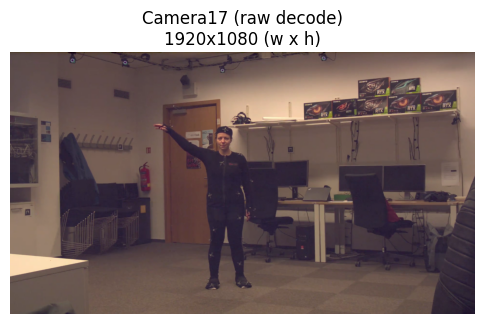

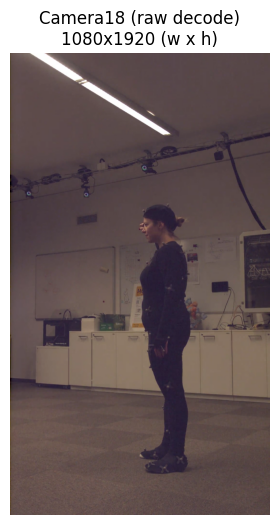

Compare the two frames above:
  - Is the person in Camera18 sideways/rotated relative to Camera17?
  - Do the reported (w x h) dimensions look swapped between the two (e.g.
    Camera17 landscape like 1920x1080 vs Camera18 portrait like 1080x1920)?
If yes to either, a rotation would be needed -- BUT rotating the frames
alone would invalidate every pixel-space comparison in this notebook.
The GT 2D joints in rehab/2d_joints/ are stored in the ORIGINAL frame's
pixel coordinates, and predicted joints_2d would come back in ROTATED-frame
coordinates. Rotating the image without transforming both coordinate sets
consistently (or mapping predictions back to the original frame before
comparison) would make 2D MPJPE meaningless while still producing
plausible-looking numbers.

For THIS dataset the hypothesis was tested and REJECTED: Camera18 is
genuinely a portrait-mounted camera, not a mis-rotated decode, so no
rotation is applied anywhere in this notebook.


In [ ]:
# ============================================================
# Cell 5b - Diagnose Camera18 frame orientation ("transposed" in filename)
# ============================================================
# Camera18's evaluation result (2D MPJPE ~3x higher than Camera17, and
# predicted ROM ~13 deg vs a GT of ~105 deg) is consistent with the raw
# decoded frames being sideways: cv2.VideoCapture often does NOT respect a
# video's rotation metadata, so a file that plays upright in a media player
# (via a rotation tag) can still decode as raw, un-rotated pixels through
# OpenCV. The "-transposed" in the filename is the tell.
#
# This just LOOKS at one raw frame from each camera, side by side, with no
# pose overlay -- if Camera18's person appears rotated relative to Camera17,
# that confirms the hypothesis and the fix is a compensating cv2.rotate()
# before every Camera18 frame is handed to pipeline.predict(). If both look
# upright and comparably framed, orientation isn't the issue and the next
# suspect is camera angle / self-occlusion / detector bbox quality instead.

import matplotlib.pyplot as plt
import cv2

def show_raw_frame(video_path, frame_idx, title):
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ok, frame_bgr = cap.read()
    cap.release()
    if not ok:
        print(f"[warn] could not read frame {frame_idx} from {video_path} for this quick check")
        return
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    h, w = frame_rgb.shape[:2]
    plt.figure(figsize=(6, 6))
    plt.imshow(frame_rgb)
    plt.title(f"{title}\n{w}x{h} (w x h)")
    plt.axis("off")
    plt.show()

mid_frame = SEG_START + (SEG_END - SEG_START) // 2
show_raw_frame(f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4", mid_frame, "Camera17 (raw decode)")
show_raw_frame(f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera18-30fps-transposed.mp4", mid_frame, "Camera18 (raw decode)")

print("Compare the two frames above:")
print("  - Is the person in Camera18 sideways/rotated relative to Camera17?")
print("  - Do the reported (w x h) dimensions look swapped between the two (e.g.")
print("    Camera17 landscape like 1920x1080 vs Camera18 portrait like 1080x1920)?")
print("If yes to either, a rotation would be needed -- BUT rotating the frames")
print("alone would invalidate every pixel-space comparison in this notebook.")
print("The GT 2D joints in rehab/2d_joints/ are stored in the ORIGINAL frame's")
print("pixel coordinates, and predicted joints_2d would come back in ROTATED-frame")
print("coordinates. Rotating the image without transforming both coordinate sets")
print("consistently (or mapping predictions back to the original frame before")
print("comparison) would make 2D MPJPE meaningless while still producing")
print("plausible-looking numbers.")
print()
print("For THIS dataset the hypothesis was tested and REJECTED: Camera18 is")
print("genuinely a portrait-mounted camera, not a mis-rotated decode, so no")
print("rotation is applied anywhere in this notebook.")


In [ ]:
# ============================================================
# Cell 6 - Run Fast-SAM-3D-Body over ONLY the selected segment
# ============================================================
# `run_pipeline_on_video` keeps the name and return contract of the InstantHMR
# notebook, so every downstream cell inherits it unchanged:
#   joints_2d   (n,70,2) float32, ORIGINAL-frame pixels, NaN where undetected
#   joints_3d   (n,70,3) float32, metres, body-centred (translation DISCARDED)
#   detector_ms (n,), hmr_ms (n,), detected (n,) bool, start_frame, end_frame
#   + timing_source ("live" | "worker"), n_persons (n,), bbox (n,4)
#
# WHERE PREDICTIONS COME FROM -- the `source` argument:
#   "live"  : run the model now, in this process
#   "cache" : load what the parallel workers (Cell 15w) saved; error if missing
#   "auto"  : cache if present, else live
# The default is PRED_SOURCE_DEFAULT: "auto" here. Cell 15w switches it to
# "cache" once the workers finish, so a missing segment surfaces as an error
# row instead of silently falling back to hours of single-process inference.
# Timing cells always pass source="live": worker timings are measured under
# GPU contention and are NOT per-frame latency.
# Live and cached predictions come from the SAME code (fastsam_infer, Cell 2e);
# Cell 15w verifies the cache reproduces this cell's live result.
#
# TRANSLATION IS DISCARDED ON PURPOSE. The InstantHMR run stored
# joints_3d_local and dropped cam_trans, and every 3D metric downstream is
# root-relative because of it. Adding pred_cam_t would make this model's numbers
# incomparable to those, and would let the GT's whole-body motion leak into MPJVE.
#
# TIMING SCOPE: detection is fused inside process_one_image(), and the claimed
# acceleration is a whole-pipeline effect, so detector_ms = 0 and hmr_ms is the
# FULL per-frame model cost. Total per-frame cost and wall-clock FPS stay
# directly comparable with the InstantHMR notebook.
#
# CAMERA INTRINSICS (FOV_MODE):
#   "per-video" : MoGe runs on N_CALIB_FRAMES frames spread across the video; the
#                 median is saved to <cache>/_calib/ and frozen for every frame
#                 of that video -- here AND in every worker. The REHAB cameras
#                 are static, so per-frame FOV is repeated work that also makes
#                 the focal length jitter between frames.
#                 This CHANGES THE PROCEDURE: calibration samples frames from
#                 the whole video (including frames after the one being
#                 processed) before inference -- an OFFLINE step, so runtime is
#                 "after offline calibration". And the intrinsics feed the
#                 network's camera-ray conditioning, so this can change the
#                 predicted articulation, not just the 2D projection. Procrustes
#                 alignment does not remove that. Cell 12b MEASURES the effect.
#   "per-frame" : the repo's default (MoGe on every frame).
#
# INFERENCE_TYPE:
#   "full" : body decoder, then the backbone AGAIN on both hand crops + hand
#            decoder, fused into the wrist rotations (repo default).
#   "body" : body decoder only. Cell 12b measures what that changes.
#
# PERSON SELECTION: IoU tracking within each segment (fastsam_infer
# `_pick_person`), initialised to the largest box -- not the largest box
# independently per frame, which lets a second person hijack single frames.
import os
import numpy as np

# --- Suppress warnings and Ultralytics YOLO logging ---
import warnings
import logging
warnings.filterwarnings("ignore")
logging.getLogger("ultralytics").setLevel(logging.ERROR)
try:
    from ultralytics.utils import LOGGER
    LOGGER.setLevel("ERROR")
except Exception:
    pass

KP2D_SOURCE = "native"     # "native": pred_keypoints_2d as-is; "project": from
                           # pred_keypoints_3d + pred_cam_t. Set from Cell 3b (b),
                           # then CONFIRM with Cell 7's overlay.
QUIET_INFERENCE = True     # swallow process_one_image's ~11 prints per frame
FOV_MODE = "per-video"
N_CALIB_FRAMES = 5
INFERENCE_TYPE = "full"    # decide with Cell 12b; changing it changes CACHE_KEY

# Everything that changes the PREDICTIONS goes into CACHE_KEY, which names the
# cache directory -- a different configuration can never read or extend another
# configuration's cache.
CACHE_KEY = fi.make_cache_key(ACCEL_HASH, FOV_MODE, N_CALIB_FRAMES, USE_MASK,
                              HAND_BOX_SOURCE, DETECTOR_NAME, DETECTOR_MODEL,
                              HF_REPO_ID, FOV_AVAILABLE,
                              inference_type=INFERENCE_TYPE,
                              person_select=fi.PERSON_SELECT)
PRED_CACHE_ROOT = "/content/drive/MyDrive/REHAB/results/fastsam_pred_cache"
PRED_CACHE_DIR = os.path.join(PRED_CACHE_ROOT, CACHE_KEY)
PRED_SOURCE_DEFAULT = globals().get("PRED_SOURCE_DEFAULT", "auto")   # don't undo 15w
INFER_CFG = {"use_mask": USE_MASK, "hand_box_source": HAND_BOX_SOURCE,
             "quiet": QUIET_INFERENCE, "fov_mode": FOV_MODE, "n_calib": N_CALIB_FRAMES,
             "inference_type": INFERENCE_TYPE,
             "cache_dir": PRED_CACHE_DIR, "cache_key": CACHE_KEY}
print(f"CACHE_KEY {CACHE_KEY}  ->  {PRED_CACHE_DIR}")

open_capture_at = fi.open_capture_at      # used by the overlay / figure cells

def assert_no_workers_running():
    """Timing cells call this: a latency measured while workers share the GPU
    measures contention, not the model."""
    alive = [p for p in globals().get("WORKER_PROCS", []) if p.poll() is None]
    if alive:
        raise RuntimeError(
            f"{len(alive)} inference worker(s) still running on this GPU -- a timing "
            f"taken now would measure contention. Wait for monitor_workers() to "
            f"finish, or call stop_workers().")

def _raw_to_pred(raw, start_frame, end_frame):
    """Cache/live raw dict -> the notebook's `pred` contract.

    Validity is kept SEPARATE. (An earlier version gated `detected` on ALL 70
    2D landmarks being finite: one NaN in an UNMAPPED landmark dropped the
    frame -- and a segment of such frames became `zero_detections` even though
    every mapped 2D and 3D joint was valid.)
      detected  : a person was selected AND all 17 MAPPED 3D joints are finite.
                  Gates 3D metrics and the zero_detections status.
      joints_2d : a non-finite MAPPED 2D joint only drops that frame from the 2D
                  metric (mpjpe_2d returns NaN for it); it never touches 3D.
      processed : frame was actually decoded + inferred. False = padding past
                  the end of the video, which is NOT a detection failure."""
    n = end_frame - start_frame + 1
    if raw["kp3d"].shape[0] != n:
        raise ValueError(f"segment has {raw['kp3d'].shape[0]} frames, expected {n}")
    meta = raw["meta"]
    kp3d = raw["kp3d"].astype(np.float32)
    detected = raw["detected"].astype(bool) & np.isfinite(kp3d[:, mhr_ids]).all(axis=(1, 2))
    if KP2D_SOURCE == "native":
        joints_2d = raw["kp2d"].astype(np.float32).copy()
    else:
        joints_2d = np.full((n, 70, 2), np.nan, np.float32)
        ci = raw["cam_int"]
        for t in np.where(detected)[0]:
            cx = float(ci[0, 2]) if np.isfinite(ci[0, 2]) else meta["frame_w"] / 2.0
            cy = float(ci[1, 2]) if np.isfinite(ci[1, 2]) else meta["frame_h"] / 2.0
            joints_2d[t] = fi._project_kp(raw["kp3d"][t], raw["cam_t"][t],
                                          float(raw["focal"][t]), cx, cy)
    return {
        "joints_2d": joints_2d, "joints_3d": kp3d,
        # 0 by design: detection is INSIDE hmr_ms (process_one_image), not free
        "detector_ms": np.zeros(n, np.float32), "hmr_ms": raw["hmr_ms"].astype(np.float32),
        "detected": detected, "start_frame": start_frame, "end_frame": end_frame,
        "processed": raw["processed"].astype(bool),
        "timing_source": meta["timing_source"],
        "n_persons": raw["n_persons"], "bbox": raw["bbox"], "track_iou": raw["track_iou"],
    }

def run_pipeline_on_video(video_path, start_frame, end_frame, hmr_batch_size=1, source=None):
    """Fast-SAM-3D-Body predictions for frames [start_frame, end_frame] (inclusive),
    LOCAL to the segment (index 0 == start_frame). See the header for `source`.

    `hmr_batch_size` is accepted for signature compatibility with the InstantHMR
    notebook but not honoured: process_one_image() consumes one frame at a time,
    so every frame is timed on its own (streaming-representative by construction).
    """
    source = source or PRED_SOURCE_DEFAULT
    if source not in ("live", "cache", "auto"):
        raise ValueError(f"source must be live/cache/auto, got {source!r}")
    if hmr_batch_size not in (1, None):
        print(f"  [note] hmr_batch_size={hmr_batch_size} ignored -- running unbatched.")
    ex, subj, cam = fi.video_key(video_path)
    path = fi.cache_file(PRED_CACHE_DIR, ex, subj, cam, start_frame, end_frame)
    if source != "live" and os.path.exists(path):
        raw = fi.load_raw(path, CACHE_KEY)
    elif source == "cache":
        raise FileNotFoundError(f"segment not in the prediction cache: {path} -- "
                                f"re-run Cell 15w to fill it")
    else:
        if any(p.poll() is None for p in globals().get("WORKER_PROCS", [])):
            print("  [note] workers are running -- this live call competes with them "
                  "for the GPU (its timings are contended).")
        raw = fi.run_segment_live(estimator, video_path, start_frame, end_frame, INFER_CFG)
    return _raw_to_pred(raw, start_frame, end_frame)

# --- Warm-up: torch.compile pays a large one-off compilation cost on the first
# --- call. It must never land inside a measured segment. (This also runs the
# --- one-off FOV calibration for this video.)
print("Warming up (torch.compile first-call compilation)...")
_ = run_pipeline_on_video(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4",
    SEG_START, min(SEG_START + 5, SEG_END), source="live")
print("Warm-up done.\n")

print(f"Evaluating repetition {int(selected_rep['repetition_number'])} only: "
      f"{SEG_END - SEG_START + 1} frames (out of {gt_2d_c17.shape[0]} total in the video)")

print("Running Fast-SAM-3D-Body on Camera17 (segment only)...")
pred_c17 = run_pipeline_on_video(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4",
    SEG_START, SEG_END, source="live")
print("Running Fast-SAM-3D-Body on Camera18 (segment only)...")
pred_c18 = run_pipeline_on_video(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera18-30fps-transposed.mp4",
    SEG_START, SEG_END, source="live")

for name, pred in [("c17", pred_c17), ("c18", pred_c18)]:
    n_detected = int(pred["detected"].sum())
    n_total = len(pred["detected"])
    print(f"{name}: {n_detected}/{n_total} frames with a detection")
    if n_detected == 0:
        print(f"  [error] {name}: ZERO detections in this segment -- all metrics below "
              f"will be NaN/meaningless. Likely a seeking or detector problem, not a "
              f"model accuracy issue. Re-run this cell; if it persists, inspect a frame "
              f"from the segment directly.")

CACHE_KEY 3d52279213  ->  /content/drive/MyDrive/REHAB/results/fastsam_pred_cache/3d52279213
Warming up (torch.compile first-call compilation)...
  local frame 0/6  (abs frame 501)
Warm-up done.

Evaluating repetition 2 only: 270 frames (out of 5227 total in the video)
Running Fast-SAM-3D-Body on Camera17 (segment only)...
  local frame 0/270  (abs frame 501)
  local frame 100/270  (abs frame 601)
  local frame 200/270  (abs frame 701)
Running Fast-SAM-3D-Body on Camera18 (segment only)...
  local frame 0/270  (abs frame 501)
  local frame 100/270  (abs frame 601)
  local frame 200/270  (abs frame 701)
c17: 270/270 frames with a detection
c18: 270/270 frames with a detection


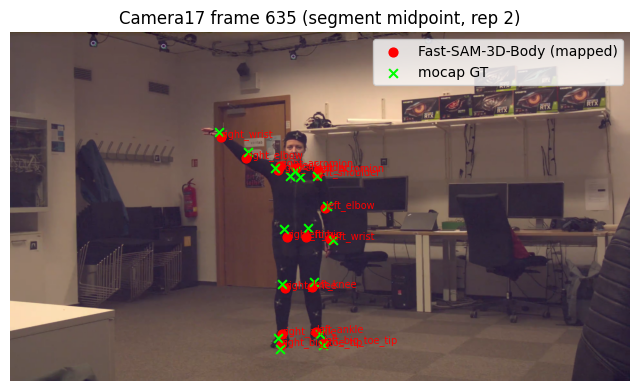

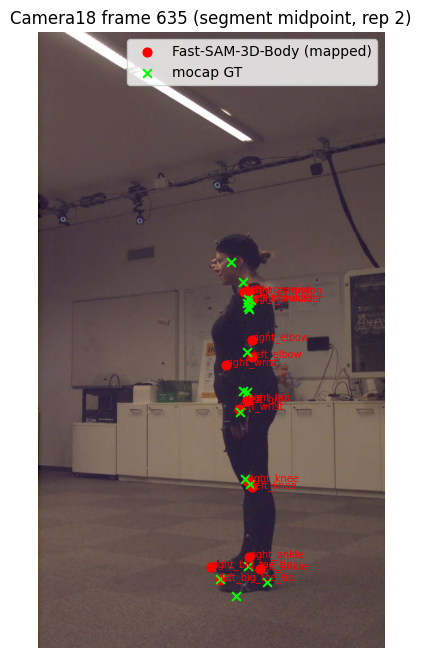

If the red (predicted) and green (GT) points don't visually align on the same
landmarks, the joint mapping in Cell 4 needs correction before trusting the
metrics below.


In [ ]:
# ============================================================
# Cell 7 - Sanity check: overlay predicted (mapped) vs GT 2D joints
# ============================================================
import matplotlib.pyplot as plt

def overlay_frame(video_path, abs_frame_idx, pred, gt_2d, title):
    """pred is a run_pipeline_on_video() result dict -- its arrays are LOCAL
    to [pred['start_frame'], pred['end_frame']], while gt_2d is indexed by
    absolute frame number, so we convert abs_frame_idx -> local index only
    for the predicted array. Uses open_capture_at() (defined in Cell 6) for
    a verified seek instead of a raw cap.set(), since that can silently fail
    to decode on some videos."""
    local_idx = abs_frame_idx - pred["start_frame"]
    cap = open_capture_at(video_path, abs_frame_idx)
    ok, frame_bgr = cap.read()
    cap.release()
    assert ok, f"could not read frame {abs_frame_idx} even after the sequential-scan fallback"
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(frame_rgb)
    pred_pts = pred["joints_2d"][local_idx, mhr_ids]
    gt_pts = gt_2d[abs_frame_idx, rehab_ids]
    plt.scatter(pred_pts[:, 0], pred_pts[:, 1], c="red", s=40, label="Fast-SAM-3D-Body (mapped)")
    plt.scatter(gt_pts[:, 0], gt_pts[:, 1], c="lime", s=40, marker="x", label="mocap GT")
    for i, lbl in enumerate(labels):
        plt.annotate(lbl, pred_pts[i], color="red", fontsize=7)
    plt.legend()
    plt.title(title)
    plt.axis("off")
    plt.show()

mid_frame = SEG_START + (SEG_END - SEG_START) // 2
overlay_frame(f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4", mid_frame,
              pred_c17, gt_2d_c17,
              f"Camera17 frame {mid_frame} (segment midpoint, rep {int(selected_rep['repetition_number'])})")
overlay_frame(f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera18-30fps-transposed.mp4", mid_frame,
              pred_c18, gt_2d_c18,
              f"Camera18 frame {mid_frame} (segment midpoint, rep {int(selected_rep['repetition_number'])})")

print("If the red (predicted) and green (GT) points don't visually align on the same")
print("landmarks, the joint mapping in Cell 4 needs correction before trusting the")
print("metrics below.")


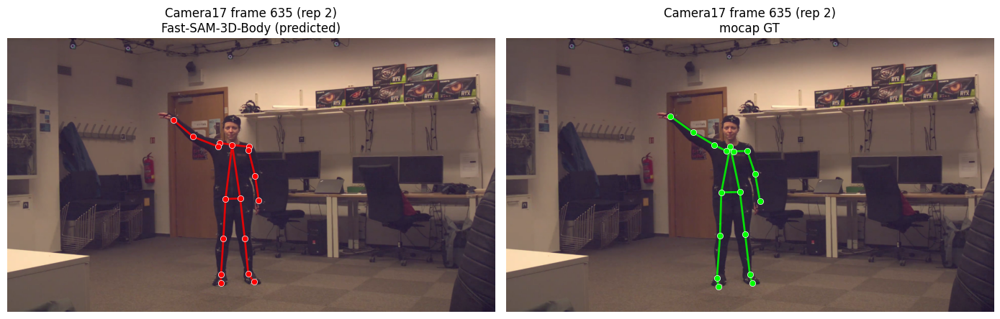

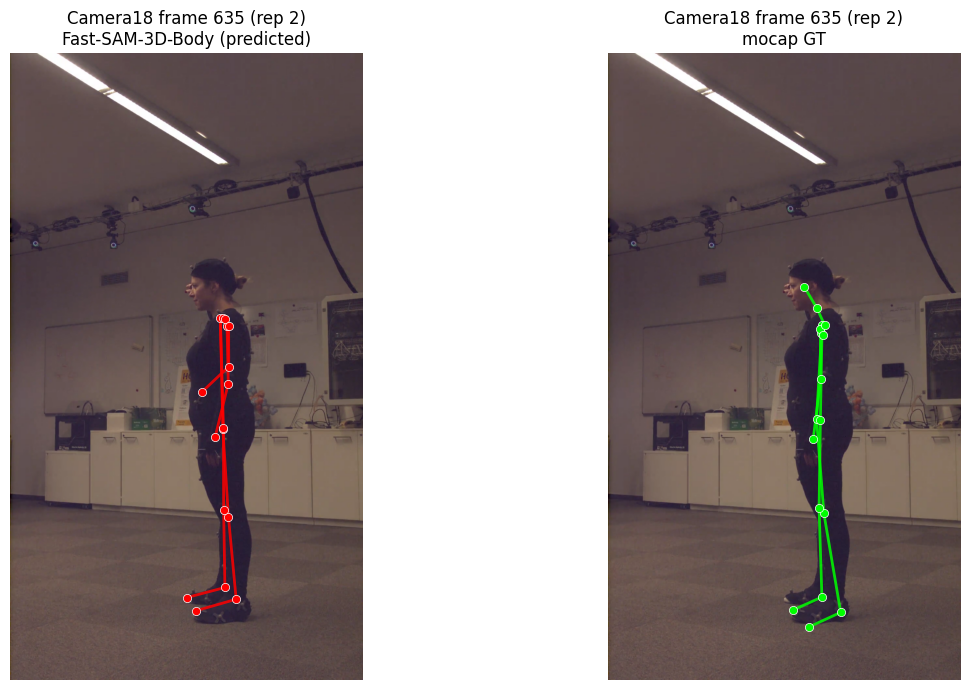

In [ ]:
# ============================================================
# Cell 7c - Side-by-side skeleton comparison (connected joints, predicted vs GT)
# ============================================================
# Cell 7's overlay puts both skeletons on ONE image (good for checking
# alignment/mapping correctness). This instead draws each skeleton with its
# bone connections on its OWN panel, side by side -- easier to see each
# skeleton's actual shape/pose independently without the two clouds of
# points visually overlapping and cluttering each other.

SKELETON_BONES = [
    ("neck", "left_acromion"), ("neck", "right_acromion"),
    ("left_acromion", "left_shoulder"), ("left_shoulder", "left_elbow"), ("left_elbow", "left_wrist"),
    ("right_acromion", "right_shoulder"), ("right_shoulder", "right_elbow"), ("right_elbow", "right_wrist"),
    ("neck", "left_hip"), ("neck", "right_hip"), ("left_hip", "right_hip"),
    ("left_hip", "left_knee"), ("left_knee", "left_ankle"), ("left_ankle", "left_big_toe_tip"),
    ("right_hip", "right_knee"), ("right_knee", "right_ankle"), ("right_ankle", "right_big_toe_tip"),
]
# Bone list is over the 17 mapped joint LABELS (Cell 4), converted to indices
# within that same 17-element ordering -- not MHR-70 or rehab-26 raw indices.
SKELETON_BONE_IDX = [(labels.index(a), labels.index(b)) for a, b in SKELETON_BONES]

def draw_skeleton_2d(ax, points_17, color):
    """points_17: (17, 2) pixel coords, ordered per `labels` (same order as
    mhr_ids/rehab_ids elsewhere in the notebook)."""
    for a, b in SKELETON_BONE_IDX:
        ax.plot([points_17[a, 0], points_17[b, 0]], [points_17[a, 1], points_17[b, 1]],
                color=color, linewidth=2, alpha=0.85, solid_capstyle="round")
    ax.scatter(points_17[:, 0], points_17[:, 1], color=color, s=35, zorder=3, edgecolors="white", linewidths=0.5)

def compare_skeletons_side_by_side(video_path, abs_frame_idx, pred, gt_2d, title_prefix):
    local_idx = abs_frame_idx - pred["start_frame"]
    cap = open_capture_at(video_path, abs_frame_idx)
    ok, frame_bgr = cap.read()
    cap.release()
    assert ok, f"could not read frame {abs_frame_idx} even after the sequential-scan fallback"
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    pred_pts = pred["joints_2d"][local_idx, mhr_ids]
    gt_pts = gt_2d[abs_frame_idx, rehab_ids]

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, pts, color, name in [
        (axes[0], pred_pts, "red", "Fast-SAM-3D-Body (predicted)"),
        (axes[1], gt_pts, "lime", "mocap GT"),
    ]:
        ax.imshow(frame_rgb)
        draw_skeleton_2d(ax, pts, color)
        ax.set_title(f"{title_prefix}\n{name}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

mid_frame = SEG_START + (SEG_END - SEG_START) // 2
compare_skeletons_side_by_side(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4", mid_frame,
    pred_c17, gt_2d_c17,
    f"Camera17 frame {mid_frame} (rep {int(selected_rep['repetition_number'])})",
)
compare_skeletons_side_by_side(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera18-30fps-transposed.mp4", mid_frame,
    pred_c18, gt_2d_c18,
    f"Camera18 frame {mid_frame} (rep {int(selected_rep['repetition_number'])})",
)


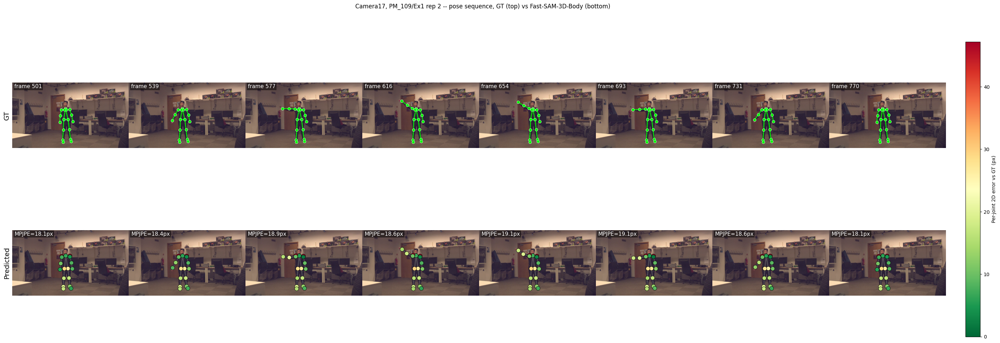

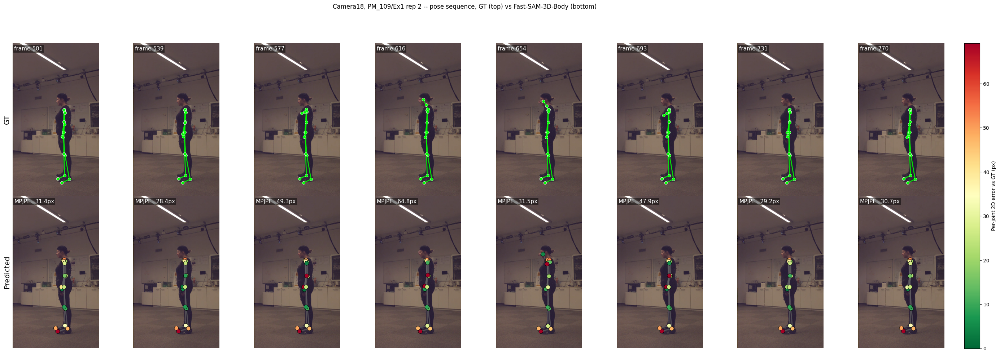

In [ ]:
# ============================================================
# Cell 7d - Pose SEQUENCE comparison: GT (top row) vs predicted (bottom row),
#           differences highlighted by per-joint error color
# ============================================================
# Samples n_poses frames evenly across the segment and lays them out as two
# rows sharing the same time axis (column i in both rows = the same frame) --
# GT skeleton on top, predicted skeleton on bottom. The predicted row's
# joints are colored by their per-joint 2D pixel error against GT (a shared
# color scale across all sampled frames, computed from the actual errors
# rather than a hardcoded guess, so the same color always means the same
# error magnitude across the whole sequence) -- this is the "highlight the
# differences" mechanism: a joint/frame that stands out in red is where the
# model disagrees with mocap the most, at a glance, across the whole rep.

def draw_skeleton_2d_colored(ax, points, joint_errors, vmax, bone_color="dimgray"):
    """Same bone layout as draw_skeleton_2d (Cell 7c), but joints are colored
    by `joint_errors` (17,) on a shared 0..vmax scale instead of one flat
    color. Returns the scatter artist (for a shared colorbar)."""
    for a, b in SKELETON_BONE_IDX:
        ax.plot([points[a, 0], points[b, 0]], [points[a, 1], points[b, 1]],
                color=bone_color, linewidth=2.2, alpha=0.6, zorder=2)
    sc = ax.scatter(points[:, 0], points[:, 1], c=joint_errors, cmap="RdYlGn_r",
                     vmin=0, vmax=vmax, s=70, zorder=3, edgecolors="black", linewidths=0.6)
    return sc

def visualize_pose_sequence(video_path, pred, gt_2d, seg_start, seg_end, title_prefix, n_poses=8):
    frame_indices = np.linspace(seg_start, seg_end, n_poses, dtype=int)

    pred_pts_list, gt_pts_list, err_list, frames_rgb = [], [], [], []
    for abs_idx in frame_indices:
        local_idx = int(abs_idx) - pred["start_frame"]
        pred_pts = pred["joints_2d"][local_idx, mhr_ids]
        gt_pts = gt_2d[int(abs_idx), rehab_ids]
        pred_pts_list.append(pred_pts)
        gt_pts_list.append(gt_pts)
        err_list.append(np.linalg.norm(pred_pts - gt_pts, axis=-1))

        cap = open_capture_at(video_path, int(abs_idx))
        ok, frame_bgr = cap.read()
        cap.release()
        frames_rgb.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB) if ok else None)

    # Shared color scale across the whole sequence: 90th percentile of the
    # observed errors, not a hardcoded guess, so it adapts to this segment's
    # actual error range instead of clipping everything to one flat color.
    vmax_shared = max(float(np.percentile(np.concatenate(err_list), 90)), 1.0)

    fig, axes = plt.subplots(2, n_poses, figsize=(4.5 * n_poses, 11))
    for i, abs_idx in enumerate(frame_indices):
        ax_top, ax_bot = axes[0, i], axes[1, i]
        if frames_rgb[i] is not None:
            ax_top.imshow(frames_rgb[i])
            ax_bot.imshow(frames_rgb[i])

        draw_skeleton_2d(ax_top, gt_pts_list[i], "lime")
        # Titles are drawn AS IN-IMAGE TEXT (not ax.set_title()) so they cost
        # no subplot layout space -- set_title() reserves a strip above the
        # axes, which would force a gap between rows even with hspace=0.
        ax_top.text(0.02, 0.98, f"frame {abs_idx}", transform=ax_top.transAxes,
                    fontsize=11, color="white", va="top", ha="left",
                    bbox=dict(facecolor="black", alpha=0.5, pad=2, linewidth=0))
        # NOT ax_top.axis("off") -- that hides axis LABELS too (matplotlib
        # docs: "off: Turn off axis lines and labels"), which would silently
        # blank out the row labels set below. Hide ticks/spines manually
        # instead so set_ylabel still renders.
        ax_top.set_xticks([])
        ax_top.set_yticks([])
        for spine in ax_top.spines.values():
            spine.set_visible(False)

        sc = draw_skeleton_2d_colored(ax_bot, pred_pts_list[i], err_list[i], vmax_shared)
        ax_bot.text(0.02, 0.98, f"MPJPE={err_list[i].mean():.1f}px", transform=ax_bot.transAxes,
                    fontsize=11, color="white", va="top", ha="left",
                    bbox=dict(facecolor="black", alpha=0.5, pad=2, linewidth=0))
        ax_bot.set_xticks([])
        ax_bot.set_yticks([])
        for spine in ax_bot.spines.values():
            spine.set_visible(False)

    axes[0, 0].set_ylabel("GT", fontsize=14)
    axes[1, 0].set_ylabel("Predicted", fontsize=14)
    fig.suptitle(f"{title_prefix} -- pose sequence, GT (top) vs Fast-SAM-3D-Body (bottom)")
    fig.subplots_adjust(wspace=0, hspace=0)
    cbar = fig.colorbar(sc, ax=axes, orientation="vertical", fraction=0.02, pad=0.02)
    cbar.set_label("Per-joint 2D error vs GT (px)")
    plt.show()

visualize_pose_sequence(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4",
    pred_c17, gt_2d_c17, SEG_START, SEG_END,
    f"Camera17, {SUBJECT}/{EXERCISE} rep {int(selected_rep['repetition_number'])}",
)
visualize_pose_sequence(
    f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera18-30fps-transposed.mp4",
    pred_c18, gt_2d_c18, SEG_START, SEG_END,
    f"Camera18, {SUBJECT}/{EXERCISE} rep {int(selected_rep['repetition_number'])}",
)


In [ ]:
# ============================================================
# Cell 8 - Position agreement: 2D MPJPE (px) and PA-MPJPE 3D (Procrustes)
# ============================================================
def mpjpe_2d(pred, gt_2d):
    """Per-DETECTED-frame mean pixel error over the 17 mapped landmarks.

    Returns one value per detected frame, in the order of
    np.where(pred["detected"]) -- Cell 12's plot relies on that alignment. A
    detected frame whose MAPPED predicted or GT 2D joints are not all finite
    (or that lies beyond the end of the GT array) gets NaN for THAT frame only;
    aggregate with np.nanmean. Unmapped landmarks are irrelevant here. gt_2d is
    sliced to the same window as pred (index 0 == start_frame)."""
    n = len(pred["detected"])
    gt_window = gt_2d[pred["start_frame"]: pred["start_frame"] + n]
    idx = np.where(pred["detected"])[0]
    out = np.full(len(idx), np.nan)
    in_gt = idx < len(gt_window)
    if in_gt.any():
        p = pred["joints_2d"][idx[in_gt]][:, mhr_ids, :2]      # (T', K, 2)
        g = gt_window[idx[in_gt]][:, rehab_ids, :2]            # (T', K, 2)
        out[in_gt] = np.linalg.norm(p - g, axis=-1).mean(axis=1)   # NaN if any joint NaN
    return out

def procrustes_align(pred, gt):
    """Rigid+scale align pred (K,3) onto gt (K,3); returns aligned pred.

    FIXED (was buggy): the reflection-correction branch flipped R's last row
    but kept the scale formula's S.sum() uncorrected. Per Umeyama (1991) eq.
    43, the SAME sign correction (D, with D[-1] = sign(det(R_uncorrected)))
    must apply to both R and the scale numerator -- using the raw S.sum()
    whenever reflection-correction triggers gives a mathematically
    suboptimal (higher-residual) fit. Verified locally: the corrected
    formula strictly reduces alignment residual vs the old one whenever
    det(R_uncorrected) < 0."""
    mu_p, mu_g = pred.mean(0), gt.mean(0)
    p0, g0 = pred - mu_p, gt - mu_g
    U, S, Vt = np.linalg.svd(p0.T @ g0)
    det_sign = 1.0 if np.linalg.det(Vt.T @ U.T) >= 0 else -1.0
    R = Vt.T @ U.T
    if det_sign < 0:
        Vt = Vt.copy()
        Vt[-1] *= -1
        R = Vt.T @ U.T
    D = np.ones(S.shape[0]); D[-1] = det_sign
    scale = (S * D).sum() / ((p0 ** 2).sum() + 1e-12)
    return (scale * (p0 @ R.T)) + mu_g

def pa_mpjpe_3d(pred, gt_3d_world):
    """Procrustes-aligned per-frame mean error (metres) over mapped landmarks."""
    valid = pred["detected"]
    n = len(valid)
    gt_window = gt_3d_world[pred["start_frame"]: pred["start_frame"] + n]
    errs = []
    for t in np.where(valid)[0]:
        p = pred["joints_3d"][t, mhr_ids]        # (K, 3) camera/body-centred
        g = gt_window[t, rehab_ids, :3]           # (K, 3) world mocap
        if np.isnan(p).any() or np.isnan(g).any():
            continue
        p_aligned = procrustes_align(p, g)
        errs.append(np.linalg.norm(p_aligned - g, axis=-1).mean())
    return np.array(errs)

results_summary = {}
for name, pred, gt2d in [("c17", pred_c17, gt_2d_c17), ("c18", pred_c18, gt_2d_c18)]:
    e2d = mpjpe_2d(pred, gt2d)
    e3d = pa_mpjpe_3d(pred, gt_3d)
    results_summary[name] = {"mpjpe_2d_px": e2d, "pa_mpjpe_3d_m": e3d}
    print(f"[{name}] 2D MPJPE: {np.nanmean(e2d):.1f} +/- {np.nanstd(e2d):.1f} px "
          f"(n={int(np.isfinite(e2d).sum())} frames with valid mapped 2D, segment only)")
    print(f"[{name}] PA-MPJPE 3D: {e3d.mean()*1000:.1f} +/- {e3d.std()*1000:.1f} mm "
          f"(n={len(e3d)} frames, segment only)")


[c17] 2D MPJPE: 18.8 +/- 0.3 px (n=270 frames with valid mapped 2D, segment only)
[c17] PA-MPJPE 3D: 51.6 +/- 1.4 mm (n=270 frames, segment only)
[c18] 2D MPJPE: 37.1 +/- 9.0 px (n=270 frames with valid mapped 2D, segment only)
[c18] PA-MPJPE 3D: 79.5 +/- 22.9 mm (n=270 frames, segment only)


In [ ]:
# ============================================================
# Cell 9 - Kinematic features on the selected segment (paper Eqs. 14-16 / Table I)
# ============================================================
# Only the one randomly selected repetition is evaluated per camera (per the
# segment-selection in Cell 5), so this reduces to a single row per camera
# rather than a loop over every repetition in Segmentation.csv.
#
# Ex1 subtype is "right arm" (unilateral shoulder-flexion style exercise).
# Primary trajectory: right shoulder-flexion angle (hip-shoulder-elbow).
# Constraint trajectory: right elbow angle (shoulder-elbow-wrist).
# Both are also computed on the left side for a symmetry check, even though
# this specific exercise variant is unilateral.

def joint_angle(A, B, C, eps=1e-8):
    """Eq. 14: angle at B formed by rays B->A and B->C, per frame. A,B,C: (T,3)."""
    v1 = A - B
    v2 = C - B
    num = (v1 * v2).sum(axis=-1)
    den = np.linalg.norm(v1, axis=-1) * np.linalg.norm(v2, axis=-1) + eps
    return np.arccos(np.clip(num / den, -1.0, 1.0))

mhr_name_to_id = {lbl: idx for (_, idx, lbl) in JOINT_CORRESPONDENCES}
rehab_name_to_id = {lbl: idx for (idx, _, lbl) in JOINT_CORRESPONDENCES}

def compute_angles(joints_3d, id_map):
    """Joint angles from the mapped landmarks.

    NAMING (corrected): the hip-shoulder-elbow angle is an UNSIGNED
    upper-arm-to-trunk elevation angle -- it is NOT isolated shoulder
    flexion. Forward elevation (flexion) and lateral elevation (abduction)
    produce the SAME value, because an unsigned 3-point angle carries no
    plane information. Calling it "shoulder flexion" would overstate what is
    measured; decomposing into anatomical planes would require a trunk
    reference frame, which is not built here.
    """
    r_hip, r_sh, r_el, r_wr = (joints_3d[:, id_map[n]] for n in
                                 ["right_hip", "right_shoulder", "right_elbow", "right_wrist"])
    l_hip, l_sh, l_el, l_wr = (joints_3d[:, id_map[n]] for n in
                                 ["left_hip", "left_shoulder", "left_elbow", "left_wrist"])
    return {
        "right_upperarm_trunk": joint_angle(r_hip, r_sh, r_el),
        "right_elbow":          joint_angle(r_sh, r_el, r_wr),
        "left_upperarm_trunk":  joint_angle(l_hip, l_sh, l_el),
        "left_elbow":           joint_angle(l_sh, l_el, l_wr),
    }

def dimensionless_jerk(x, fs, max_gap_policy="nan"):
    """Log dimensionless jerk.

    DIRECTION (corrected): this returns a NEGATIVE log, so HIGHER values mean
    SMOOTHER movement. (An earlier docstring said "lower = smoother", which is
    backwards: more jerk -> larger integral -> larger log -> more negative
    return value.)

    GAP POLICY: np.gradient propagates NaN into neighbouring samples, so a
    single missing frame contaminates a widening window across three
    successive derivatives. Rather than silently returning a NaN-poisoned or
    spuriously-smooth number, this refuses to score a trajectory containing
    non-finite samples and returns NaN, which downstream agreement statistics
    already drop. Segments needing a smoothness score must therefore be
    gap-free; `mpjve_n_pairs` vs `n_valid_frames` in the batch CSV shows which
    segments had gaps at all.
    """
    x = np.asarray(x, dtype=float)
    if len(x) < 5:
        return np.nan
    if not np.isfinite(x).all():
        return np.nan
    v = np.gradient(x) * fs
    a = np.gradient(v) * fs
    j = np.gradient(a) * fs
    duration = len(x) / fs
    amp = np.ptp(v) + 1e-8
    dl = -np.log(np.trapezoid(j ** 2, dx=1.0 / fs) * (duration ** 3) / (amp ** 2) + 1e-8)
    return dl

FPS = 30.0
rows = []
for name, pred in [("c17", pred_c17), ("c18", pred_c18)]:
    n = len(pred["joints_3d"])
    gt_3d_window = gt_3d[pred["start_frame"]: pred["start_frame"] + n, :, :3]

    pred_angles = compute_angles(pred["joints_3d"], mhr_name_to_id)
    gt_angles = compute_angles(gt_3d_window, rehab_name_to_id)

    row = {"camera": name, "rep": int(selected_rep["repetition_number"]),
           "correctness": int(selected_rep["correctness"])}
    for key in pred_angles:
        p_seg = pred_angles[key]
        g_seg = gt_angles[key]
        row[f"ROM_pred_{key}_deg"] = np.degrees(np.nanmax(p_seg) - np.nanmin(p_seg))
        row[f"ROM_gt_{key}_deg"]   = np.degrees(np.nanmax(g_seg) - np.nanmin(g_seg))
        if key == "right_upperarm_trunk":  # primary trajectory only, for smoothness
            row["smoothness_pred"] = dimensionless_jerk(p_seg, FPS)
            row["smoothness_gt"]   = dimensionless_jerk(g_seg, FPS)
    # Bilateral symmetry index (Eq. 16) on shoulder-flexion angle, this segment
    pL, pR = pred_angles["left_upperarm_trunk"], pred_angles["right_upperarm_trunk"]
    gL, gR = gt_angles["left_upperarm_trunk"], gt_angles["right_upperarm_trunk"]
    row["SI_pred"] = 1 - np.nansum(np.abs(pL - pR)) / (np.nansum(np.abs(pL) + np.abs(pR)) + 1e-8)
    row["SI_gt"]   = 1 - np.nansum(np.abs(gL - gR)) / (np.nansum(np.abs(gL) + np.abs(gR)) + 1e-8)
    row["duration_s"] = n / FPS
    rows.append(row)

feature_df = pd.DataFrame(rows)
feature_df


,camera,rep,correctness,ROM_pred_right_upperarm_trunk_deg,ROM_gt_right_upperarm_trunk_deg,smoothness_pred,smoothness_gt,ROM_pred_right_elbow_deg,ROM_gt_right_elbow_deg,ROM_pred_left_upperarm_trunk_deg,ROM_gt_left_upperarm_trunk_deg,ROM_pred_left_elbow_deg,ROM_gt_left_elbow_deg,SI_pred,SI_gt,duration_s
0,c17,2,1,97.693298,105.825646,-15.343420,-12.009845,8.329306,4.713975,2.066877,1.48825,7.971527,1.744113,0.491747,0.51751,9.0
1,c18,2,1,79.959244,105.825646,-17.003818,-12.009845,119.487762,4.713975,3.200944,1.48825,5.866449,1.744113,0.692697,0.51751,9.0


In [ ]:
# ============================================================
# Cell 10 - Feature agreement (RGB-predicted vs mocap ground truth)
# ============================================================
# NOTE: with N_SEGMENTS = 1, feature_df has exactly one row per camera --
# this is a single-repetition sanity check, not a statistically robust
# agreement estimate (Pearson r is undefined for n=1 and reported as NaN).
# Bump N_SEGMENTS in Cell 5 (and extend Cells 6/9 to loop over
# `selected_reps`) to get a proper per-subject distribution.
from scipy.stats import pearsonr

for cam in ["c17", "c18"]:
    sub = feature_df[feature_df["camera"] == cam]
    print(f"--- {cam} ({len(sub)} segment(s) evaluated) ---")
    for key in ["right_upperarm_trunk", "right_elbow", "left_upperarm_trunk", "left_elbow"]:
        p = sub[f"ROM_pred_{key}_deg"]
        g = sub[f"ROM_gt_{key}_deg"]
        mae = np.abs(p - g).mean()
        r, _ = pearsonr(p, g) if len(p) > 2 else (np.nan, None)
        print(f"  ROM[{key}]: MAE={mae:.1f} deg, Pearson r={r:.2f}")
    mae_smooth = np.abs(sub["smoothness_pred"] - sub["smoothness_gt"]).mean()
    mae_si = np.abs(sub["SI_pred"] - sub["SI_gt"]).mean()
    print(f"  Smoothness (primary traj): MAE={mae_smooth:.3f}")
    print(f"  Symmetry index: MAE={mae_si:.3f}")
    print()


--- c17 (1 segment(s) evaluated) ---
  ROM[right_upperarm_trunk]: MAE=8.1 deg, Pearson r=nan
  ROM[right_elbow]: MAE=3.6 deg, Pearson r=nan
  ROM[left_upperarm_trunk]: MAE=0.6 deg, Pearson r=nan
  ROM[left_elbow]: MAE=6.2 deg, Pearson r=nan
  Smoothness (primary traj): MAE=3.334
  Symmetry index: MAE=0.026

--- c18 (1 segment(s) evaluated) ---
  ROM[right_upperarm_trunk]: MAE=25.9 deg, Pearson r=nan
  ROM[right_elbow]: MAE=114.8 deg, Pearson r=nan
  ROM[left_upperarm_trunk]: MAE=1.7 deg, Pearson r=nan
  ROM[left_elbow]: MAE=4.1 deg, Pearson r=nan
  Smoothness (primary traj): MAE=4.994
  Symmetry index: MAE=0.175



In [ ]:
# ============================================================
# Cell 11 - Runtime / latency (matches the paper's real-time claims)
# ============================================================
# No detector/HMR split for this model -- detection is fused into
# process_one_image(), so Cell 6 records detector_ms = 0 and the whole per-frame
# cost lands in hmr_ms. Printing a "detector: 0.00 ms" column would just be
# noise. This is a component timer: it excludes video decode and therefore is
# NOT achievable FPS -- Cell 21b's wall_clock_fps is.
for name, pred in [("c17", pred_c17), ("c18", pred_c18)]:
    total = pred["detector_ms"] + pred["hmr_ms"]
    print(f"[{name}] model: {total.mean():.2f} ms/frame  "
          f"({1000.0/total.mean():.1f} fps, component timer only -- see Cell 21b)")

# ---- projected cost of the batch runs, from THIS measurement --------------
# Median, not mean, so a stray recompile doesn't dominate. Component timer
# only (excludes decode), so treat these as a lower bound on wall time.
_ms = float(np.median(np.concatenate([
    p["hmr_ms"][p["detected"]] for p in (pred_c17, pred_c18)])))
_full = int((seg["last_frame"] - seg["first_frame"] + 1).sum()) * 2   # x2 cameras
print(f"\nmedian {_ms:.0f} ms/frame  [config {ACCEL_HASH}, {RUNTIME_ARM_LABEL}]")
print(f"  full dataset ({_full:,} frame-evals): ~{_full * _ms / 3.6e6:.1f} h "
      f"single-process (Cell 15w's parallel workers divide this)")
_ihmr = "/content/drive/MyDrive/REHAB/results/batch_eval_results.csv"
if os.path.exists(_ihmr):
    _s = pd.read_csv(_ihmr)
    _sf = int((_s["seg_end"] - _s["seg_start"] + 1).sum())
    print(f"  InstantHMR's sampled set ({_sf:,} frame-evals, needed for a PAIRED "
          f"comparison): ~{_sf * _ms / 3.6e6:.1f} h")


[c17] model: 464.03 ms/frame  (2.2 fps, component timer only -- see Cell 21b)
[c18] model: 218.59 ms/frame  (4.6 fps, component timer only -- see Cell 21b)

median 283 ms/frame  [config 7918dc67ee, torch.compile (no TensorRT)]
  full dataset (256,894 frame-evals): ~20.2 h single-process (Cell 15w's parallel workers divide this)
  InstantHMR's sampled set (32,284 frame-evals, needed for a PAIRED comparison): ~2.5 h


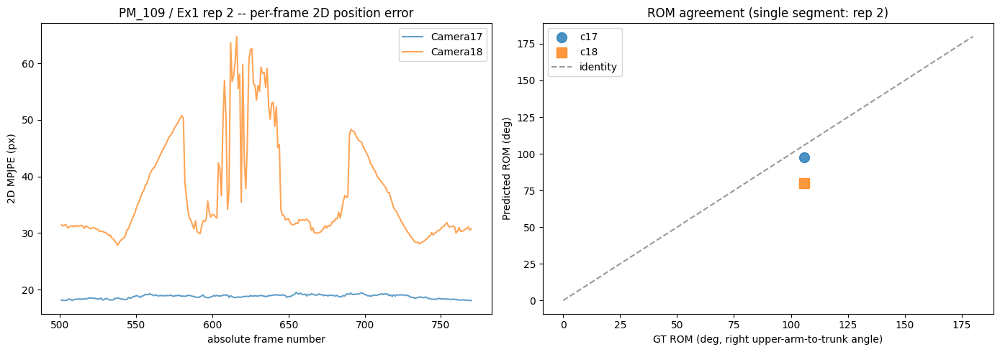

In [ ]:
# ============================================================
# Cell 12 - Plots: error over the segment + ROM agreement scatter
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# FIXED: mpjpe_2d() returns one value per DETECTED frame, so its array is
# compacted wherever a detection was missed. Adding a bare arange() to
# start_frame therefore mislabelled every point after the first gap, silently
# shifting the curve left. Use the actual valid frame indices instead.
frames_c17 = pred_c17["start_frame"] + np.where(pred_c17["detected"])[0]
frames_c18 = pred_c18["start_frame"] + np.where(pred_c18["detected"])[0]
axes[0].plot(frames_c17, results_summary["c17"]["mpjpe_2d_px"], label="Camera17", alpha=0.7)
axes[0].plot(frames_c18, results_summary["c18"]["mpjpe_2d_px"], label="Camera18", alpha=0.7)
axes[0].set_xlabel("absolute frame number")
axes[0].set_ylabel("2D MPJPE (px)")
axes[0].set_title(f"{SUBJECT} / {EXERCISE} rep {int(selected_rep['repetition_number'])} "
                   f"-- per-frame 2D position error")
axes[0].legend()

for cam, marker in [("c17", "o"), ("c18", "s")]:
    sub = feature_df[feature_df["camera"] == cam]
    axes[1].scatter(sub["ROM_gt_right_upperarm_trunk_deg"], sub["ROM_pred_right_upperarm_trunk_deg"],
                     marker=marker, s=100, label=cam, alpha=0.8)
lims = [0, 180]
axes[1].plot(lims, lims, "k--", alpha=0.4, label="identity")
axes[1].set_xlabel("GT ROM (deg, right upper-arm-to-trunk angle)")
axes[1].set_ylabel("Predicted ROM (deg)")
axes[1].set_title(f"ROM agreement (single segment: rep {int(selected_rep['repetition_number'])})")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# Cell 12b - Configuration A/B: camera intrinsics and hand decoder, MEASURED
# ============================================================
# Two choices change what the model PREDICTS, so they are measured here on
# real segments instead of asserted:
#   * FOV_MODE "per-video" vs the repo's "per-frame". The intrinsics feed the
#     network's camera-ray conditioning (sam3d_body `ray_cond_emb`), so freezing
#     them can change predicted articulation -- which Procrustes alignment does
#     NOT remove -- not only the 2D projection.
#   * INFERENCE_TYPE "body" vs "full". "full" runs the ViT backbone a SECOND time
#     on both hand crops and fuses the hand result into the wrist rotations
#     (sam3d_body.run_inference, Steps 2-3). With SKIP_KEYPOINT_PROMPT=1 the
#     hand result is NOT fed back as a prompt to re-estimate the body, so joint
#     POSITIONS should barely move -- but both wrists are evaluated joints and
#     drive the elbow angle, so "barely" has to be a number.
#
# Arms (single process, live; workers must be stopped):
#   REF  full + per-frame   (the repo's default behaviour)
#   A    full + per-video   (per-video intrinsics)
#   B    body + per-video   (per-video intrinsics, no hand pass)
# Per arm, vs REF: root-centred 3D difference over the 17 mapped joints
# (median / p95 / max mm), the two wrists separately, elbow-ROM difference
# (deg), 2D difference (px), detection agreement -- and median ms/frame.
#
# Then set FOV_MODE / INFERENCE_TYPE in Cell 6, re-run from Cell 6 (CACHE_KEY
# changes, so a fresh cache), and launch Cell 15w.
assert_no_workers_running()

AB_N_SEGMENTS = 4
AB_SEED = 7
AB_ARMS = [("REF full/per-frame", "full", "per-frame"),
           ("A   full/per-video", "full", "per-video"),
           ("B   body/per-video", "body", "per-video")]

# one repetition from each of AB_N_SEGMENTS different exercises, alternating cameras
_rng = np.random.default_rng(AB_SEED)
_exs = sorted(seg["exercise_id"].unique())
_pick = _rng.choice(len(_exs), size=min(AB_N_SEGMENTS, len(_exs)), replace=False)
ab_segments = []
for j, ei in enumerate(_pick):
    _rows = seg[seg["exercise_id"] == _exs[ei]].reset_index(drop=True)
    _r = _rows.iloc[int(_rng.integers(len(_rows)))]
    _cam = "c17" if j % 2 == 0 else "c18"
    _ex = f"Ex{int(_r['exercise_id'])}"
    _vp = (f"/content/drive/MyDrive/REHAB/videos/{_ex}/{_r['video_id']}-Camera17-30fps.mp4"
           if _cam == "c17" else
           f"/content/drive/MyDrive/REHAB/videos/{_ex}/{_r['video_id']}-Camera18-30fps-transposed.mp4")
    ab_segments.append((_vp, int(_r["first_frame"]), int(_r["last_frame"]),
                        f"{_ex}/{_r['video_id']}/{_cam}/rep{int(_r['repetition_number'])}"))
print("A/B segments:", [s[3] for s in ab_segments])

def _ab_run(vp, s, e, itype, fmode):
    cfg = dict(INFER_CFG, inference_type=itype, fov_mode=fmode, quiet=True)
    return _raw_to_pred(fi.run_segment_live(estimator, vp, s, e, cfg, progress_every=0), s, e)

def _root_centre(j3):
    return j3 - ((j3[:, 9] + j3[:, 10]) / 2.0)[:, None, :]     # MHR-70: 9/10 = hips

def _ab_rom(angles):      # local: Cell 14's _rom_deg is defined later in the notebook
    a = np.asarray(angles, dtype=float)
    a = a[np.isfinite(a)]
    return float(np.degrees(a.max() - a.min())) if a.size else float("nan")

_wrists = [labels.index("left_wrist"), labels.index("right_wrist")]
ab_preds = {}
for name, itype, fmode in AB_ARMS:
    # warm-up: compile this path + (per-video) calibrate, all OUTSIDE the timings
    for vp, s, e, _ in ab_segments:
        _ab_run(vp, s, min(s + 3, e), itype, fmode)
    ab_preds[name] = [_ab_run(vp, s, e, itype, fmode) for vp, s, e, _ in ab_segments]
    print(f"  done: {name}")

ref_name = AB_ARMS[0][0]
ab_rows = []
for name, itype, fmode in AB_ARMS:
    ms = np.concatenate([p["hmr_ms"][p["processed"]] for p in ab_preds[name]])
    d3, dw, d2, rom_d, agree = [], [], [], [], []
    for pr, pa in zip(ab_preds[ref_name], ab_preds[name]):
        both = pr["detected"] & pa["detected"]
        agree.append(float((pr["detected"] == pa["detected"]).mean()))
        if not both.any():
            continue
        diff = np.linalg.norm(_root_centre(pa["joints_3d"][both])[:, mhr_ids]
                              - _root_centre(pr["joints_3d"][both])[:, mhr_ids], axis=-1) * 1000.0
        d3.append(diff.ravel())
        dw.append(diff[:, _wrists].ravel())
        d2.append(np.linalg.norm(pa["joints_2d"][both][:, mhr_ids]
                                 - pr["joints_2d"][both][:, mhr_ids], axis=-1).ravel())
        ang_r = compute_angles(pr["joints_3d"], mhr_name_to_id)
        ang_a = compute_angles(pa["joints_3d"], mhr_name_to_id)
        for k in ("right_elbow", "left_elbow"):
            rom_d.append(abs(_ab_rom(ang_a[k]) - _ab_rom(ang_r[k])))
    cat = lambda xs: np.concatenate(xs) if xs else np.array([np.nan])
    d3, dw, d2 = cat(d3), cat(dw), cat(d2)
    ab_rows.append({
        "arm": name, "inference_type": itype, "fov_mode": fmode,
        "median_ms": float(np.median(ms)), "detect_agree_vs_ref": float(np.mean(agree)),
        "d3_median_mm": float(np.nanmedian(d3)), "d3_p95_mm": float(np.nanpercentile(d3, 95)),
        "d3_max_mm": float(np.nanmax(d3)), "wrist_p95_mm": float(np.nanpercentile(dw, 95)),
        "wrist_max_mm": float(np.nanmax(dw)),
        "elbow_ROM_absdiff_max_deg": float(np.nanmax(rom_d)) if rom_d else float("nan"),
        "d2_p95_px": float(np.nanpercentile(d2, 95)),
    })
ab_table = pd.DataFrame(ab_rows)
ab_table["speedup_vs_ref"] = ab_table.loc[0, "median_ms"] / ab_table["median_ms"]
print("\nDifferences are vs REF (full + per-frame), root-centred, BEFORE any alignment.")
print("REF vs itself is 0 by construction; rerunning REF would show GPU nondeterminism.")
print("A decision rule you can state in the paper, e.g.: adopt an arm only if its")
print("wrist_p95_mm and elbow ROM difference are small relative to the error being")
print("measured (Cell 16 PA-MPJPE is typically tens of mm).")
ab_table


A/B segments: ['Ex3/PM_030/c17/rep1', 'Ex4/PM_005/c18/rep12', 'Ex6/PM_029/c17/rep10', 'Ex5/PM_037/c18/rep9']
  done: REF full/per-frame
  done: A   full/per-video
  done: B   body/per-video

Differences are vs REF (full + per-frame), root-centred, BEFORE any alignment.
REF vs itself is 0 by construction; rerunning REF would show GPU nondeterminism.
A decision rule you can state in the paper, e.g.: adopt an arm only if its
wrist_p95_mm and elbow ROM difference are small relative to the error being
measured (Cell 16 PA-MPJPE is typically tens of mm).


,arm,inference_type,fov_mode,median_ms,detect_agree_vs_ref,d3_median_mm,d3_p95_mm,d3_max_mm,wrist_p95_mm,wrist_max_mm,elbow_ROM_absdiff_max_deg,d2_p95_px,speedup_vs_ref
0,REF full/per-frame,full,per-frame,245.957596,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
1,A full/per-video,full,per-video,214.604477,1.0,0.663517,3.359367,13.738872,2.310902,4.534691,0.096114,0.489104,1.146097
2,B body/per-video,body,per-video,92.826660,1.0,0.678075,3.359419,13.738667,2.310779,4.534748,0.144342,0.503854,2.649644


# Part 2: Batch evaluation across multiple subjects, segments, and exercises

Revised to align with what the underlying dataset (REHAB24-style, in
`KIMORE/rehab/`) actually supports: dual synchronized RGB views, mocap
ground truth, repetition boundaries, and a binary correctness label per
repetition -- but **no physician/clinical score and no patient-subgroup
labels**. So this section reports spatial accuracy, temporal accuracy,
kinematic-feature agreement, correctness-information preservation,
cross-view robustness, and runtime -- and does **not** claim physician-score
correlation or pathology-subgroup analysis, which this data cannot support.

**Requires Cells 1-9 above to have been run at least once** (reuses
`pipeline`, `JOINT_CORRESPONDENCES`/`mhr_ids`/`rehab_ids`/`labels`,
`mhr_name_to_id`/`rehab_name_to_id`, and `open_capture_at`/
`run_pipeline_on_video`/`compute_angles`/`joint_angle`/`dimensionless_jerk`
from the single-subject walkthrough -- none of that logic is duplicated
here).


In [ ]:
# ============================================================
# Cell 13 - Discover available subjects/exercises and set batch parameters
# ============================================================
import glob
import os

def list_available_subjects(exercise):
    pattern = f"/content/drive/MyDrive/REHAB/videos/{exercise}/*-Camera17-30fps.mp4"
    files = sorted(glob.glob(pattern))
    return [os.path.basename(f).split("-Camera17")[0] for f in files]

def list_available_exercises():
    exdirs = sorted(glob.glob("/content/drive/MyDrive/REHAB/videos/Ex*"))
    return [os.path.basename(d) for d in exdirs]

BATCH_SEED = 123
N_SEGMENTS_PER_SUBJECT = 2   # random repetitions sampled per subject per exercise
MAX_SUBJECTS = None          # None = all available; set an int for a quick smoke test
BATCH_EXERCISES = list_available_exercises()   # e.g. ["Ex1", "Ex2", ...]; edit to restrict

subjects_by_exercise = {}
for ex in BATCH_EXERCISES:
    subs = list_available_subjects(ex)
    if MAX_SUBJECTS:
        subs = subs[:MAX_SUBJECTS]
    subjects_by_exercise[ex] = subs
    print(f"{ex}: {len(subs)} subjects -- {subs}")

total_planned = sum(len(s) for s in subjects_by_exercise.values()) * N_SEGMENTS_PER_SUBJECT * 2
print(f"\nPlanned: up to {total_planned} (exercise, subject, segment, camera) inference runs.")

# --- Subject-count caveat ---
# `subject` (e.g. "PM_109") is a RECORDING ID, not a verified unique
# participant. REHAB24-6 is documented as ~10 participants; there is no
# recording-ID -> participant mapping file in this dataset, and the same
# person very likely appears under the same ID across multiple exercises
# (expected -- that's not the concern) but recording IDs across the batch
# should NOT be read as "N independent people" for any statistical claim.
# No automated de-duplication is attempted here deliberately: without a
# ground-truth mapping, any heuristic grouping would risk looking "fixed"
# while actually just substituting one unverified assumption for another.
all_subject_ids = sorted({s for subs in subjects_by_exercise.values() for s in subs})
print(f"\n[CAVEAT] {len(all_subject_ids)} distinct recording IDs across this batch -- "
      f"do NOT read this as {len(all_subject_ids)} independent participants. "
      f"REHAB24-6 is documented as ~10 participants; recording-ID counts and "
      f"per-segment statistics below should not be treated as draws from "
      f"{len(all_subject_ids)} independent people.")


Ex1: 13 subjects -- ['PM_000', 'PM_001', 'PM_002', 'PM_012', 'PM_016', 'PM_023', 'PM_024', 'PM_032', 'PM_039', 'PM_101', 'PM_109', 'PM_114', 'PM_122']
Ex2: 12 subjects -- ['PM_003', 'PM_004', 'PM_013', 'PM_014', 'PM_025', 'PM_026', 'PM_033', 'PM_040', 'PM_102', 'PM_110', 'PM_115', 'PM_123']
Ex3: 10 subjects -- ['PM_010', 'PM_011', 'PM_030', 'PM_031', 'PM_044', 'PM_045', 'PM_107', 'PM_108', 'PM_119', 'PM_121']
Ex4: 12 subjects -- ['PM_005', 'PM_006', 'PM_018', 'PM_020', 'PM_027', 'PM_034', 'PM_035', 'PM_041', 'PM_103', 'PM_111', 'PM_116', 'PM_124']
Ex5: 9 subjects -- ['PM_021', 'PM_028', 'PM_037', 'PM_042', 'PM_104', 'PM_112', 'PM_117a', 'PM_117b', 'PM_125']
Ex6: 9 subjects -- ['PM_008', 'PM_022', 'PM_029', 'PM_038', 'PM_043', 'PM_105', 'PM_113', 'PM_118', 'PM_126']

Planned: up to 260 (exercise, subject, segment, camera) inference runs.

[CAVEAT] 65 distinct recording IDs across this batch -- do NOT read this as 65 independent participants. REHAB24-6 is documented as ~10 participants; 

In [ ]:
# ============================================================
# Cell 14 - Per-segment evaluation function (per-joint 3D errors, MPJVE,
#           and all identifiers needed for cross-view pairing + correctness
#           AUROC downstream)
# ============================================================
# METRIC DEFINITIONS (read before interpreting any number below)
#
#   root_mpjpe_mm -- TRANSLATION-ONLY aligned: pred and GT each re-expressed
#     relative to their own hip-midpoint, with NO rotation/scale correction.
#     *** NOT a tracking-accuracy number while the pred/GT coordinate frames
#     remain unreconciled. *** pred comes from Fast-SAM-3D-Body's
#     pred_keypoints_3d in the model's own MHR convention; REHAB24 mocap GT is
#     world-space Y-up; nothing here reconciles them -- so this metric may
#     contain an unknown fixed rotation on top of any real error. Note this is
#     NOT necessarily the same convention the InstantHMR ONNX export used (that
#     one negated Y and Z per tools/parquet_to_npz.py), so the sibling
#     notebook's finding does not transfer. A fitted rotation near 180 deg is
#     consistent with an axis-convention mismatch but does NOT by itself
#     establish which axes differ. Cell 16c runs the experiment that actually
#     settles it. Until then, prefer pa_mpjpe_mm for any claim.
#
#   pa_mpjpe_mm -- SEGMENT-LEVEL similarity-aligned, then ROOT-CENTRED:
#     ONE fixed rotation+scale+translation fit per segment (from the
#     segment's mean pose) applied to every frame, after which BOTH
#     trajectories are re-expressed relative to their own hip-midpoint per
#     frame. The root-centring matters: predictions carry no global
#     translation (cam_trans is discarded), so comparing against raw
#     world-space GT would charge the person's own within-segment movement
#     to the model. This is NOT the per-frame-refit PA-MPJPE
#     convention used in most pose benchmarks and is not directly comparable
#     to per-frame PA-MPJPE numbers reported elsewhere. A single fixed fit is
#     used deliberately: per-frame refitting would re-explain away real error
#     and would inject alignment jitter into any velocity computed afterwards.
#
#   mpjve_mms -- ROOT-RELATIVE velocity error (limb articulation), on the
#     segment-level similarity-aligned trajectory, using only truly
#     consecutive frame pairs.
#     *** Why root-relative is the ONLY MPJVE reported here: ***
#     run_pipeline_on_video (Cell 6) stores `joints_3d_local` and DISCARDS the
#     model's `cam_trans` output, so predicted joints are body-centred and
#     carry no global translation at all. A global-translation MPJVE would
#     therefore compare a translation-free prediction against a translating
#     ground truth -- it would score the GT's whole-body motion as model
#     error, not measure global tracking. (Verified: with perfect local
#     articulation and translating GT, a global variant reported ~3000 mm/s
#     while root-relative was ~0.) Reporting one would support a claim this
#     pipeline structurally cannot make, so it is not computed.

LOG_FULL_TRANSFORM = False  # opt-in: also log the full 3x3 R + 3-vec t per
                            # segment (9+3 extra float columns). Off by
                            # default to keep the main CSV lean.

def fit_procrustes(mean_pred, mean_gt):
    """Segment-level rigid+scale fit: mean_pred (K,3) -> mean_gt (K,3).

    Per Umeyama (1991) eq. 43 the reflection correction D (with
    D[-1] = sign(det(R_uncorrected))) must be applied to BOTH the rotation
    and the scale numerator. An earlier version applied it only to R and kept
    a raw S.sum() scale, which gives a suboptimal (higher-residual) fit
    whenever reflection correction triggers."""
    mu_p, mu_g = mean_pred.mean(0), mean_gt.mean(0)
    p0, g0 = mean_pred - mu_p, mean_gt - mu_g
    U, S, Vt = np.linalg.svd(p0.T @ g0)
    det_sign = 1.0 if np.linalg.det(Vt.T @ U.T) >= 0 else -1.0
    R = Vt.T @ U.T
    reflection_corrected = det_sign < 0
    if reflection_corrected:
        Vt = Vt.copy()
        Vt[-1] *= -1
        R = Vt.T @ U.T
    D = np.ones(S.shape[0]); D[-1] = det_sign
    scale = (S * D).sum() / ((p0 ** 2).sum() + 1e-12)
    t = mu_g - scale * (mu_p @ R.T)
    return R, scale, t, reflection_corrected

def apply_transform(points, R, scale, t):
    return scale * (points @ R.T) + t

def compute_3d_errors(pred_3d_full, gt_3d_full_window, fps):
    """pred_3d_full: (T, 70, 3) raw model output (body-centred, no cam_trans).
    gt_3d_full_window: (T, 26, 3) raw mocap (world-space), already sliced to
    the same [start_frame, end_frame] window.

    Returns (root_mpjpe_mm, pa_mpjpe_mm, mpjve_mms) as per-joint (17,) arrays,
    a transform_diag dict of segment-level scalars, and the validity mask.
    """
    n_common = min(pred_3d_full.shape[0], gt_3d_full_window.shape[0])
    nan17 = np.full(len(mhr_ids), np.nan)
    empty_diag = {
        "reflection_corrected": None, "rotation_angle_deg": float("nan"),
        "scale": float("nan"), "translation_mm": float("nan"),
        "mpjve_n_pairs": 0, "n_valid_frames": 0,
    }
    if n_common < 2:
        return nan17, nan17, nan17, empty_diag, np.zeros(max(n_common, 0), dtype=bool)

    # Length mismatch between pred and GT windows is possible (e.g. the video
    # ended early, or the GT array is shorter than the requested segment) --
    # truncate both to the overlap rather than letting a shape error surface
    # later as something harder to diagnose.
    pred_3d_full = pred_3d_full[:n_common]
    gt_3d_full_window = gt_3d_full_window[:n_common]

    # Validity requires FINITE values in BOTH mapped arrays. Checking only the
    # prediction (the earlier behaviour) let a single non-finite GT coordinate
    # reach np.linalg.svd and raise LinAlgError("SVD did not converge"),
    # killing the whole segment -- and, via Cell 15's outer try/except, the
    # sibling camera's already-computed row along with it.
    pred_ok = np.isfinite(pred_3d_full[:, mhr_ids, :]).all(axis=(1, 2))
    gt_ok = np.isfinite(gt_3d_full_window[:, rehab_ids, :]).all(axis=(1, 2))
    valid = pred_ok & gt_ok
    empty_diag["n_valid_frames"] = int(valid.sum())
    if valid.sum() < 2:
        return nan17, nan17, nan17, empty_diag, valid

    pred17 = pred_3d_full[valid][:, mhr_ids, :]          # (T', 17, 3) metres
    gt17 = gt_3d_full_window[valid][:, rehab_ids, :]     # (T', 17, 3) metres

    # --- translation-only aligned (root = hip midpoint) ---
    lh, rh = labels.index("left_hip"), labels.index("right_hip")
    root_pred = (pred17[:, lh] + pred17[:, rh]) / 2.0
    root_gt = (gt17[:, lh] + gt17[:, rh]) / 2.0
    pred17_rel = pred17 - root_pred[:, None, :]
    gt17_rel = gt17 - root_gt[:, None, :]
    root_mpjpe_mm = np.linalg.norm(pred17_rel - gt17_rel, axis=-1).mean(axis=0) * 1000.0

    # --- single segment-level similarity fit, applied to every frame ---
    R, scale, t, reflection_corrected = fit_procrustes(pred17.mean(axis=0), gt17.mean(axis=0))
    aligned_pred17 = apply_transform(pred17.reshape(-1, 3), R, scale, t).reshape(pred17.shape)

    # FIXED: root-centre BOTH trajectories per frame before comparing.
    # Previously this compared aligned_pred17 directly against raw gt17. The
    # prediction carries NO per-frame global translation (Cell 6 stores
    # joints_3d_local and discards cam_trans), while the GT translates as the
    # person actually moves within the repetition. The single fitted `t`
    # removes only the segment MEAN offset, so within-segment body drift
    # stayed in the error and was charged to the model. Measured on a
    # synthetic segment whose prediction is a PERFECT local-articulation
    # match: 10 cm of GT drift fabricated ~25 mm of error, 20 cm fabricated
    # ~50 mm. Rehab repetitions involve weight shifts of exactly that size,
    # so the old numbers were inflated by an unknown amount.
    #
    # The FIT itself needs no change: Procrustes centres both point sets
    # internally, and a per-frame translation shifts every joint of the mean
    # pose uniformly, so the centroid subtraction already removes it. Only
    # the COMPARISON was translation-sensitive.
    aligned_root = (aligned_pred17[:, lh] + aligned_pred17[:, rh]) / 2.0
    aligned_pred17_rel = aligned_pred17 - aligned_root[:, None, :]
    pa_mpjpe_mm = np.linalg.norm(aligned_pred17_rel - gt17_rel, axis=-1).mean(axis=0) * 1000.0

    transform_diag = {
        "reflection_corrected": bool(reflection_corrected),
        "rotation_angle_deg": float(np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1.0, 1.0)))),
        "scale": float(scale),
        "translation_mm": float(np.linalg.norm(t) * 1000.0),
        "n_valid_frames": int(valid.sum()),
    }
    if LOG_FULL_TRANSFORM:
        transform_diag["R_flat"] = R.flatten().tolist()
        transform_diag["t_vec"] = t.tolist()

    # --- MPJVE (root-relative; see the header note on why global is absent) ---
    # Only frame pairs that are TRULY consecutive in the original (pre-mask)
    # index are differenced. `valid`'s True positions are original local
    # indices, so a gap there means a real dt gap -- differencing across it
    # would silently treat e.g. frames 5 and 7 as dt=1/fps when it is 2/fps.
    valid_idx = np.where(valid)[0]
    consecutive = (np.diff(valid_idx) == 1)
    if consecutive.any():
        # aligned_pred17_rel / gt17_rel are the same root-centred trajectories
        # pa_mpjpe_mm is computed from, so the spatial and temporal metrics
        # now describe exactly the same quantity, one positional and one its
        # time derivative.
        vel_pred = np.diff(aligned_pred17_rel, axis=0) * fps
        vel_gt = np.diff(gt17_rel, axis=0) * fps
        mpjve_mms = np.linalg.norm(
            vel_pred[consecutive] - vel_gt[consecutive], axis=-1
        ).mean(axis=0) * 1000.0
        transform_diag["mpjve_n_pairs"] = int(consecutive.sum())
    else:
        mpjve_mms = nan17.copy()
        transform_diag["mpjve_n_pairs"] = 0

    return root_mpjpe_mm, pa_mpjpe_mm, mpjve_mms, transform_diag, valid

# ROM is computed with nanmax - nanmin over the frames each trajectory HAS. If
# predictions are missing near the peak of the movement, predicted and GT ROM
# describe different sets of frames. So: a repetition's ROM for a feature is
# used only when both trajectories are valid on >= ROM_MIN_COVERAGE of its
# frames (below that the primary ROM columns are NaN, and the agreement cells
# drop the row); the ungated value is kept as *_allframes, and a
# matched-support ROM (only frames where BOTH are valid) as *_matched.
ROM_MIN_COVERAGE = 0.90

def _rom_deg(angles):
    a = np.asarray(angles, dtype=float)
    a = a[np.isfinite(a)]
    return float(np.degrees(a.max() - a.min())) if a.size else float("nan")

def _symmetry_index(L, R):
    L, R = np.asarray(L, float), np.asarray(R, float)
    if L.size == 0:
        return float("nan")
    return float(1 - np.sum(np.abs(L - R)) / (np.sum(np.abs(L) + np.abs(R)) + 1e-8))

ANATOMICAL_REGION = {
    "neck": "trunk", "left_acromion": "trunk", "right_acromion": "trunk",
    "left_hip": "trunk", "right_hip": "trunk",
    "left_shoulder": "upper_limb", "left_elbow": "upper_limb", "left_wrist": "upper_limb",
    "right_shoulder": "upper_limb", "right_elbow": "upper_limb", "right_wrist": "upper_limb",
    "left_knee": "lower_limb", "left_ankle": "lower_limb", "left_big_toe_tip": "lower_limb",
    "right_knee": "lower_limb", "right_ankle": "lower_limb", "right_big_toe_tip": "lower_limb",
}
assert set(ANATOMICAL_REGION) == set(labels), "region map must cover exactly the 17 mapped joints"

def _evaluate_one_camera(subject, exercise, cam, video_path, seg_start, seg_end,
                          rep_number, correctness, gt_2d, gt_3d, fps):
    """Evaluate ONE camera view. Returns a single row dict. Raises nothing --
    callers get a row with an explanatory `status` instead, so one camera's
    failure can never discard the other camera's completed work."""
    row = {
        "model": MODEL_TAG, "accel_hash": ACCEL_HASH, "cache_key": CACHE_KEY,
        "subject": subject, "exercise": exercise, "camera": cam,
        "rep": rep_number, "correctness": correctness,
        "seg_start": seg_start, "seg_end": seg_end,
    }
    if not os.path.exists(video_path):
        row["status"] = "missing_video"
        return row

    pred = run_pipeline_on_video(video_path, seg_start, seg_end)
    row["timing_source"] = pred.get("timing_source", "live")
    n_detected = int(pred["detected"].sum())
    row["n_frames"] = len(pred["detected"])                      # requested
    processed = pred.get("processed", np.ones(len(pred["detected"]), bool))
    row["n_processed"] = int(processed.sum())                    # actually decoded
    row["segment_complete"] = bool(row["n_processed"] == row["n_frames"])
    row["n_detected"] = n_detected
    if "n_persons" in pred and row["n_processed"]:
        row["frac_multi_person"] = float((pred["n_persons"][processed] > 1).mean())
        selected = np.isfinite(pred["bbox"]).all(axis=1)
        # track_iou is NaN on the first selection and on every re-initialisation
        row["n_track_reinit"] = max(0, int(np.isnan(pred["track_iou"][selected]).sum()) - 1)
    row["detector_ms"] = pred["detector_ms"][pred["detected"]].tolist()
    row["hmr_ms"] = pred["hmr_ms"][pred["detected"]].tolist()

    if n_detected == 0:
        row["status"] = "zero_detections"
        return row

    e2d = mpjpe_2d(pred, gt_2d)
    row["n_valid_2d"] = int(np.isfinite(e2d).sum())
    row["mpjpe_2d_px_mean"] = float(np.nanmean(e2d)) if row["n_valid_2d"] else float("nan")

    n = len(pred["joints_3d"])
    gt_3d_window = gt_3d[pred["start_frame"]: pred["start_frame"] + n, :, :3]
    root_mpjpe, pa_mpjpe, mpjve, transform_diag, _ = compute_3d_errors(
        pred["joints_3d"], gt_3d_window, fps
    )
    if transform_diag["reflection_corrected"] is None:
        # Fewer than 2 frames valid in BOTH pred and GT -- every metric below
        # would be NaN and there is no transform to diagnose. Distinct from
        # "zero_detections": detections existed, but usable paired 3D data
        # did not (e.g. non-finite GT coordinates).
        row["status"] = "insufficient_valid_frames"
        row["n_valid_frames"] = transform_diag["n_valid_frames"]
        return row

    for j, lbl in enumerate(labels):
        row[f"root_mpjpe_mm__{lbl}"] = float(root_mpjpe[j])
        row[f"pa_mpjpe_mm__{lbl}"] = float(pa_mpjpe[j])
        row[f"mpjve_mms__{lbl}"] = float(mpjve[j])
    row["transform_reflection_corrected"] = transform_diag["reflection_corrected"]
    row["transform_rotation_angle_deg"] = transform_diag["rotation_angle_deg"]
    row["transform_scale"] = transform_diag["scale"]
    row["transform_translation_mm"] = transform_diag["translation_mm"]
    row["mpjve_n_pairs"] = transform_diag["mpjve_n_pairs"]
    row["n_valid_frames"] = transform_diag["n_valid_frames"]
    if LOG_FULL_TRANSFORM and "R_flat" in transform_diag:
        row["transform_R_flat"] = transform_diag["R_flat"]
        row["transform_t_vec"] = transform_diag["t_vec"]

    pred_angles = compute_angles(pred["joints_3d"], mhr_name_to_id)
    gt_angles = compute_angles(gt_3d_window, rehab_name_to_id)
    n_req = max(len(pred["joints_3d"]), 1)
    for key in pred_angles:
        p_seg, g_seg = np.asarray(pred_angles[key]), np.asarray(gt_angles[key])
        m = min(len(p_seg), len(g_seg))
        both = np.isfinite(p_seg[:m]) & np.isfinite(g_seg[:m])
        cov = float(both.sum() / n_req)             # vs REQUESTED frames: padding counts as missing
        rom_p, rom_g = _rom_deg(p_seg), _rom_deg(g_seg)
        row[f"ROM_cov_{key}"] = cov
        row[f"ROM_pred_{key}_deg_allframes"] = rom_p
        row[f"ROM_gt_{key}_deg_allframes"] = rom_g
        row[f"ROM_pred_{key}_deg_matched"] = _rom_deg(p_seg[:m][both])
        row[f"ROM_gt_{key}_deg_matched"] = _rom_deg(g_seg[:m][both])
        gate = cov >= ROM_MIN_COVERAGE
        row[f"ROM_pred_{key}_deg"] = rom_p if gate else float("nan")
        row[f"ROM_gt_{key}_deg"] = rom_g if gate else float("nan")
        if key == "right_upperarm_trunk":
            row["smoothness_pred"] = float(dimensionless_jerk(p_seg, fps))
            row["smoothness_gt"] = float(dimensionless_jerk(g_seg, fps))

    pL, pR = pred_angles["left_upperarm_trunk"], pred_angles["right_upperarm_trunk"]
    gL, gR = gt_angles["left_upperarm_trunk"], gt_angles["right_upperarm_trunk"]
    # SI_pred/SI_gt (kept for comparability with the InstantHMR notebook) sum
    # over DIFFERENT frames when predictions are missing -- the same support
    # problem as ROM. SI_*_matched use only frames where all four angles are valid.
    row["SI_pred"] = float(1 - np.nansum(np.abs(pL - pR)) / (np.nansum(np.abs(pL) + np.abs(pR)) + 1e-8))
    row["SI_gt"] = float(1 - np.nansum(np.abs(gL - gR)) / (np.nansum(np.abs(gL) + np.abs(gR)) + 1e-8))
    m = min(len(pL), len(gL))
    si_both = (np.isfinite(pL[:m]) & np.isfinite(pR[:m]) & np.isfinite(gL[:m]) & np.isfinite(gR[:m]))
    row["SI_cov"] = float(si_both.sum() / n_req)
    row["SI_pred_matched"] = _symmetry_index(pL[:m][si_both], pR[:m][si_both])
    row["SI_gt_matched"] = _symmetry_index(gL[:m][si_both], gR[:m][si_both])
    row["status"] = "ok"
    return row

def evaluate_segment(subject, exercise, seg_start, seg_end, rep_number, correctness,
                      gt_2d_c17, gt_2d_c18, gt_3d, cameras=("c17", "c18")):
    """Evaluate both camera views of one repetition.

    Each camera is wrapped in its own try/except so a failure in one view
    yields a status='error' row for THAT view only. Previously a single
    exception propagated out of this function, so Cell 15's outer handler
    discarded the sibling camera's already-computed row too -- silently
    dropping successful work and leaving the results unable to account for
    every attempted evaluation."""
    import traceback as _tb
    rows = []
    video_paths = {
        "c17": f"/content/drive/MyDrive/REHAB/videos/{exercise}/{subject}-Camera17-30fps.mp4",
        "c18": f"/content/drive/MyDrive/REHAB/videos/{exercise}/{subject}-Camera18-30fps-transposed.mp4",
    }
    gt2d_by_cam = {"c17": gt_2d_c17, "c18": gt_2d_c18}
    fps = 30.0

    for cam in cameras:                  # Cell 15c passes only the cameras still pending
        video_path = video_paths[cam]
        try:
            rows.append(_evaluate_one_camera(
                subject, exercise, cam, video_path, seg_start, seg_end,
                rep_number, correctness, gt2d_by_cam[cam], gt_3d, fps,
            ))
        except Exception as e:
            print(f"    [error] {subject}/{exercise}/{cam} rep {rep_number}: {e}")
            _tb.print_exc()
            rows.append({
                "model": MODEL_TAG, "accel_hash": ACCEL_HASH, "cache_key": CACHE_KEY,
                "subject": subject, "exercise": exercise, "camera": cam,
                "rep": rep_number, "correctness": correctness,
                "seg_start": seg_start, "seg_end": seg_end,
                "status": "error", "error_message": f"{type(e).__name__}: {e}",
            })
    return rows


In [ ]:
# ============================================================
# Cell 15 - Batch loop: every exercise x subject x N_SEGMENTS_PER_SUBJECT
# ============================================================
import traceback

batch_rows = []
rng_batch = np.random.default_rng(BATCH_SEED)

for ex in BATCH_EXERCISES:
    subs = subjects_by_exercise[ex]
    for si, subject in enumerate(subs):
        print(f"\n=== {ex} [{si + 1}/{len(subs)}] {subject} ===")
        try:
            gt2d17_s = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{ex}/{subject}-c17-30fps.npy")
            gt2d18_s = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{ex}/{subject}-c18-30fps.npy")
            gt3d_s = np.load(f"/content/drive/MyDrive/REHAB/3d_joints/{ex}/{subject}-30fps.npy")

            seg_s = seg[(seg["video_id"] == subject) &
                        (seg["exercise_id"] == int(ex[2:]))].reset_index(drop=True)
            if len(seg_s) == 0:
                print(f"  [skip] no Segmentation.csv rows for {subject}/{ex}")
                continue

            k = min(N_SEGMENTS_PER_SUBJECT, len(seg_s))
            picks = rng_batch.choice(len(seg_s), size=k, replace=False)

            for idx in picks:
                rep = seg_s.iloc[int(idx)]
                s0, s1 = int(rep["first_frame"]), int(rep["last_frame"])
                print(f"  rep {int(rep['repetition_number'])}: frames [{s0}, {s1}] ({s1 - s0 + 1} frames)")
                rows = evaluate_segment(
                    subject, ex, s0, s1,
                    int(rep["repetition_number"]), int(rep["correctness"]),
                    gt2d17_s, gt2d18_s, gt3d_s,
                )
                for r in rows:
                    print(f"    {r['camera']}: {r.get('status')}"
                          + (f" (root MPJPE mean={np.mean([r[k] for k in r if k.startswith('root_mpjpe_mm__')]):.1f}mm)"
                             if r.get("status") == "ok" else ""))
                batch_rows.extend(rows)
        except Exception as e:
            print(f"  [error] {subject}/{ex}: {e}")
            traceback.print_exc()
            continue

batch_df = pd.DataFrame(batch_rows)
print()
print(f"Collected {len(batch_df)} (exercise, subject, segment, camera) rows.")

# Save to both /content (fast, ephemeral) and Drive (persists across sessions --
# consistent with the dataset itself now being Drive-mounted, so results survive
# a runtime disconnect the same way the source data does).
batch_df.to_csv("/content/fastsam_batch_eval_results.csv", index=False)
import os as _os
_os.makedirs("/content/drive/MyDrive/REHAB/results", exist_ok=True)
batch_df.to_csv("/content/drive/MyDrive/REHAB/results/fastsam_batch_eval_results.csv", index=False)
print("Saved to /content/fastsam_batch_eval_results.csv and "
      "/content/drive/MyDrive/REHAB/results/fastsam_batch_eval_results.csv")

ok_df = batch_df[batch_df["status"] == "ok"].copy()
print(f"{len(ok_df)}/{len(batch_df)} rows have status == 'ok'. Status breakdown:")
print(batch_df["status"].value_counts())

# --- Transform diagnostics summary (resolves "root-relative MPJPE not yet
# interpretable as accuracy" -- this is the concrete evidence for/against an
# unreconciled pred/GT coordinate-frame mismatch dominating that metric) ---
if len(ok_df) > 0:
    refl_frac = ok_df["transform_reflection_corrected"].mean()
    angles = ok_df["transform_rotation_angle_deg"].dropna()
    print()
    print(f"Transform diagnostics across {len(ok_df)} 'ok' segments:")
    print(f"  reflection-correction triggered in {refl_frac * 100:.1f}% of segments")
    if len(angles) > 0:
        print(f"  fitted rotation angle: mean={angles.mean():.1f} deg, "
              f"min={angles.min():.1f} deg, max={angles.max():.1f} deg")
        print(f"  (per tools/parquet_to_npz.py, pred is Y-down and REHAB24 mocap GT is "
              f"Y-up -- if this consistently reads ~180 deg, that confirms an unreconciled "
              f"axis-convention mismatch is dominating root_mpjpe_mm, not model error)")
    n_gap = (ok_df["n_detected"] - 1 - ok_df["mpjve_n_pairs"]).clip(lower=0)
    if n_gap.sum() > 0:
        print(f"  MPJVE: {int(n_gap.sum())} frame-pairs excluded across all segments due to "
              f"non-consecutive (gapped) detections")
    else:
        print(f"  MPJVE: no gapped frame-pairs excluded (consistent with the observed "
              f"~99.97% per-frame detection rate)")



=== Ex1 [1/13] PM_000 ===
  rep 1: frames [180, 377] (198 frames)
  [calib] Ex1/PM_000/c17: fx=1698.7px (median of 5 frames)
  local frame 0/198  (abs frame 180)
  local frame 100/198  (abs frame 280)
  [calib] Ex1/PM_000/c18: fx=2033.9px (median of 5 frames)
  local frame 0/198  (abs frame 180)
  local frame 100/198  (abs frame 280)
    c17: ok (root MPJPE mean=1002.2mm)
    c18: ok (root MPJPE mean=1067.3mm)
  rep 4: frames [866, 1085] (220 frames)
  local frame 0/220  (abs frame 866)
  local frame 100/220  (abs frame 966)
  local frame 200/220  (abs frame 1066)
  local frame 0/220  (abs frame 866)
  local frame 100/220  (abs frame 966)
  local frame 200/220  (abs frame 1066)
    c17: ok (root MPJPE mean=1018.6mm)
    c18: ok (root MPJPE mean=1076.4mm)

=== Ex1 [2/13] PM_001 ===
  rep 10: frames [2747, 2961] (215 frames)
  [calib] Ex1/PM_001/c17: fx=1663.2px (median of 5 frames)
  local frame 0/215  (abs frame 2747)
  local frame 100/215  (abs frame 2847)
  local frame 200/215  (abs

## Part 2b: FULL-dataset evaluation — parallel workers + prediction cache

Inference and metrics are split into two stages.

**1. Cell 15w — inference, in parallel.** `N_WORKERS` processes share the GPU.
Each runs the *same* code as this notebook (`fastsam_infer.py`, Cell 2e) at
batch size 1, over whole videos, and writes each segment's raw predictions to a
cache on Drive (`fastsam_pred_cache/<CACHE_KEY>/`). One file per
(segment, camera), written atomically — a disconnect loses only the segments in
flight, and re-running Cell 15w resumes.

*Why workers and not batching:* at batch size 1, `process_one_image` leaves the
GPU idle much of the time (≈6 `cuda.synchronize()` calls per frame, CPU-side
cropping and colour conversion, the whole output copied to CPU). Several
processes fill each other's gaps, with outputs identical to a single process.
Batching several frames into one forward pass was rejected: the model batches
*people in one image*, and feeding it crops from different frames breaks the
hand stage, which crops hands from the single image passed in.

**2. Cells 15c–15d — metrics, from the cache.** `run_pipeline_on_video` reads
cached predictions, so the full metric pass takes minutes, and changing an
analysis choice (e.g. excluding `mocap_erroneous` repetitions) never re-runs
inference.

**Timing:** worker timings are taken under GPU contention and are *not*
per-frame latency. T6 (Cell 21) and T7 (Cell 21b) are measured live, in a
single process, after the workers finish — those cells refuse to run while
workers are alive.

Order: **15b → 15w** (re-attach any time with `monitor_workers()`) **→ 15c → 15d**.
Cell 15 (the sampled loop) and 15b–15d produce the same `batch_df` / `ok_df`
schema — run one of them, not both.


In [ ]:
# ============================================================
# Cell 15b - Full-dataset run: configuration and work list
# ============================================================
import os as _os

FULL_RESULTS_PATH = "/content/drive/MyDrive/REHAB/results/fastsam_full_eval_results.csv"
CHECKPOINT_EVERY = 10        # flush to Drive every N completed repetitions
TIME_BUDGET_HOURS = None     # None = run to completion, no wall-clock limit.
                             # Safe because Cell 15c checkpoints every
                             # CHECKPOINT_EVERY repetitions AND flushes in a
                             # finally: block -- a Colab disconnect loses at
                             # most CHECKPOINT_EVERY repetitions, not the run.
                             # Set a float (e.g. 3.0) to stop early instead.
EXERCISE_FILTER = None       # e.g. ["Ex1", "Ex2"] to split the job across sessions; None = all

_os.makedirs(_os.path.dirname(FULL_RESULTS_PATH), exist_ok=True)

# --- Build the complete work list: one entry per (exercise, subject, repetition) ---
full_work = []
for ex in BATCH_EXERCISES:
    if EXERCISE_FILTER and ex not in EXERCISE_FILTER:
        continue
    for subject in subjects_by_exercise[ex]:
        seg_s = seg[(seg["video_id"] == subject) &
                    (seg["exercise_id"] == int(ex[2:]))]
        for _, rep in seg_s.iterrows():
            full_work.append({
                "exercise": ex,
                "subject": subject,
                "rep": int(rep["repetition_number"]),
                "first_frame": int(rep["first_frame"]),
                "last_frame": int(rep["last_frame"]),
                "correctness": int(rep["correctness"]),
            })

n_frames_total = sum(w["last_frame"] - w["first_frame"] + 1 for w in full_work)

# --- ETA from measured throughput if a previous run exists, else a stated default ---
if "ok_df" in globals() and len(ok_df) > 0 and "detector_ms" in ok_df.columns:
    try:
        _d = np.concatenate([np.array(r) for r in ok_df["detector_ms"] if len(r) > 0])
        _h = np.concatenate([np.array(r) for r in ok_df["hmr_ms"] if len(r) > 0])
        ms_per_frame = float(np.median(_d + _h))
        eta_source = "measured from the previous run in this session"
    except Exception:
        ms_per_frame, eta_source = 75.0, "default estimate (could not read previous timings)"
else:
    ms_per_frame, eta_source = 75.0, "default estimate (no previous run in this session)"

est_hours = (n_frames_total * 2 * ms_per_frame / 1000.0) / 3600.0   # x2 cameras

print(f"Exercises:      {sorted({w['exercise'] for w in full_work})}")
print(f"Recording IDs:  {len({w['subject'] for w in full_work})}")
print(f"Repetitions:    {len(full_work)}")
print(f"Camera-segment evaluations: {len(full_work) * 2}")
print(f"Frames (x2 cameras):        {n_frames_total * 2:,}")
print()
print(f"Throughput assumption: {ms_per_frame:.1f} ms/frame ({eta_source})")
print(f"Single-process estimate: ~{est_hours:.1f} h -- Cell 15w runs inference "
      f"in parallel workers and prints a live ETA.")
if TIME_BUDGET_HOURS is None:
    print("Wall-clock budget: NONE -- Cell 15c runs until the work is done or")
    print("  Colab disconnects. Progress is checkpointed either way; just re-run")
    print("  Cell 15c to resume after a disconnect.")
else:
    print(f"Wall-clock budget per run of Cell 15c: {TIME_BUDGET_HOURS} h "
          f"-> roughly {int(np.ceil(est_hours / TIME_BUDGET_HOURS))} session(s) needed.")
print()
print(f"Checkpoint file: {FULL_RESULTS_PATH}")
if _os.path.exists(FULL_RESULTS_PATH):
    _done_preview = pd.read_csv(FULL_RESULTS_PATH)
    _keys = _done_preview[["exercise", "subject", "rep"]].drop_duplicates()
    print(f"  EXISTING checkpoint found: {len(_done_preview)} rows covering "
          f"{len(_keys)} repetitions -- Cell 15c will resume, skipping those.")
else:
    print("  No checkpoint yet -- Cell 15c will start from the beginning.")


Exercises:      ['Ex1', 'Ex2', 'Ex3', 'Ex4', 'Ex5', 'Ex6']
Recording IDs:  65
Repetitions:    1072
Camera-segment evaluations: 2144
Frames (x2 cameras):        256,894

Throughput assumption: 215.3 ms/frame (measured from the previous run in this session)
Single-process estimate: ~15.4 h -- Cell 15w runs inference in parallel workers and prints a live ETA.
Wall-clock budget: NONE -- Cell 15c runs until the work is done or
  Colab disconnects. Progress is checkpointed either way; just re-run
  Cell 15c to resume after a disconnect.

Checkpoint file: /content/drive/MyDrive/REHAB/results/fastsam_full_eval_results.csv
  No checkpoint yet -- Cell 15c will start from the beginning.


In [ ]:
# ============================================================
# Cell 15w - Parallel inference workers: fill the prediction cache
# ============================================================
# Launches N_WORKERS background processes, each running fastsam_infer.py
# (Cell 2e) over a shard of the videos in `full_work` (Cell 15b), then monitors
# them. Safe to re-run at any time: segments already in the cache are skipped,
# so this RESUMES after a disconnect. Interrupting this cell stops only the
# MONITOR -- workers keep running; re-attach with monitor_workers().
import json, os, shutil, subprocess, sys, time
from IPython.display import clear_output

N_WORKERS = 4            # each worker ~4 GB VRAM and ~1 busy CPU core. Raise to
                         # 5-6 if the monitor's GPU util stays well below ~90% and
                         # VRAM/RAM allow; lower it if a worker dies with OOM.
COPY_VIDEOS_LOCAL = True # N workers seeking through videos on Drive's FUSE
                         # mount can become the bottleneck; local SSD cannot.
LOCAL_VIDEO_ROOT = "/content/rehab_videos"   # wiped when the runtime ends
DRIVE_VIDEO_ROOT = "/content/drive/MyDrive/REHAB/videos"
RUN_DIR = "/content/fastsam_workers"         # configs, logs, status files
STAGGER_S = 20           # spread model loading + compilation across workers
MONITOR_EVERY_S = 30

def _vname(subject, cam):
    return (f"{subject}-Camera17-30fps.mp4" if cam == "c17"
            else f"{subject}-Camera18-30fps-transposed.mp4")

if any(p.poll() is None for p in globals().get("WORKER_PROCS", [])):
    raise SystemExit("Workers from a previous launch are still running. Re-attach with "
                     "monitor_workers(), or stop them with stop_workers() first.")

def _orphan_worker_pids():
    """Workers survive a kernel restart ("Restart session" keeps the VM, and they
    run in their own session), but the restarted kernel no longer holds their
    handles. Find them through the pid each one writes into its status file."""
    pids = []
    if not os.path.isdir(RUN_DIR):
        return pids
    for f in os.listdir(RUN_DIR):
        if not (f.startswith("status_") and f.endswith(".json")):
            continue
        try:
            pid = int(json.load(open(os.path.join(RUN_DIR, f)))["pid"])
            if "fastsam_infer.py" in open(f"/proc/{pid}/cmdline").read():
                pids.append(pid)
        except Exception:
            continue
    return pids

def stop_orphan_workers():
    import signal
    for pid in _orphan_worker_pids():
        try:
            os.kill(pid, signal.SIGTERM)
            print(f"sent SIGTERM to orphaned worker pid {pid}")
        except ProcessLookupError:
            pass
    print("Their finished segments stay cached; re-run Cell 15w to resume the rest.")

_orphans = _orphan_worker_pids()
if _orphans and not globals().get("WORKER_PROCS"):
    raise SystemExit(
        f"{len(_orphans)} worker(s) from before a kernel restart are still running "
        f"(pids {_orphans}). Launching now would run a SECOND set on the same GPU. "
        f"Either let them finish (watch {RUN_DIR}/status_*.json), or call "
        f"stop_orphan_workers() and re-run this cell to resume.")

# ---- 1. work list: every (video, segment) in full_work, for both cameras ----
_by_video = {}
for _w in full_work:
    for _cam in ("c17", "c18"):
        _by_video.setdefault((_w["exercise"], _w["subject"], _cam), set()).add(
            (int(_w["first_frame"]), int(_w["last_frame"])))

def _missing_entries():
    return [(ex, subj, cam, s, e)
            for (ex, subj, cam), segs in sorted(_by_video.items())
            for s, e in sorted(segs)
            if not os.path.exists(fi.cache_file(PRED_CACHE_DIR, ex, subj, cam, s, e))]

pending_videos = []
for (ex, subj, cam), segs in sorted(_by_video.items()):
    todo = [s for s in sorted(segs)
            if not os.path.exists(fi.cache_file(PRED_CACHE_DIR, ex, subj, cam, *s))]
    if todo:
        pending_videos.append({"exercise": ex, "subject": subj, "cam": cam,
                               "segments": [list(s) for s in todo],
                               "frames": fi._union_len(todo)})
_n_total = sum(len(s) for s in _by_video.values())
print(f"Prediction cache: {PRED_CACHE_DIR}")
print(f"  {_n_total - len(_missing_entries())}/{_n_total} (segment, camera) entries cached; "
      f"{len(pending_videos)} videos / {sum(v['frames'] for v in pending_videos):,} "
      f"frames still to infer.")

# ---- helpers: monitor / stop / post-run checks --------------------------------
def stop_workers():
    procs = globals().get("WORKER_PROCS", [])
    for p in procs:
        if p.poll() is None:
            p.terminate()
    for p in procs:
        try:
            p.wait(timeout=30)
        except Exception:
            p.kill()
    print("Workers stopped. Finished segments stay cached; re-run Cell 15w to resume.")

def _gpu_line():
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=10).stdout.strip().splitlines()[0]
        u, m, t = [x.strip() for x in out.split(",")]
        return f"GPU util {u}% | VRAM {int(m)/1024:.1f}/{int(t)/1024:.0f} GB"
    except Exception:
        return "GPU: n/a"

def _ram_line():
    try:
        info = dict(l.split(":", 1) for l in open("/proc/meminfo"))
        avail = int(info["MemAvailable"].split()[0]) / 1e6
        tot = int(info["MemTotal"].split()[0]) / 1e6
        return f"RAM {tot - avail:.0f}/{tot:.0f} GB"
    except Exception:
        return "RAM: n/a"

def _verify_against_live():
    """The cache must reproduce the live path the walkthrough (Cells 6-7) validated."""
    if "pred_c17" not in globals():
        print("(verification skipped: the Cell 6 live result pred_c17 is not in memory)")
        return
    vp = f"/content/drive/MyDrive/REHAB/videos/{EXERCISE}/{SUBJECT}-Camera17-30fps.mp4"
    try:
        cached = run_pipeline_on_video(vp, SEG_START, SEG_END, source="cache")
    except FileNotFoundError:
        print("(verification skipped: the walkthrough segment is not in this work list)")
        return
    both = cached["detected"] & pred_c17["detected"]
    agree = float((cached["detected"] == pred_c17["detected"]).mean())
    if both.sum() == 0:
        print("[WARN] no frame detected in both the cached and live walkthrough segment")
        return
    d = np.linalg.norm(cached["joints_3d"][both][:, mhr_ids]
                       - pred_c17["joints_3d"][both][:, mhr_ids], axis=-1) * 1000.0
    print(f"Cache vs live walkthrough ({SUBJECT}/{EXERCISE}/c17, {int(both.sum())} frames): "
          f"detection agreement {agree*100:.1f}%, 3D joint difference "
          f"median {np.median(d):.4f} mm, max {d.max():.4f} mm")
    if d.max() > 1.0 or agree < 0.99:
        print("[WARN] larger than GPU nondeterminism explains -- the workers are NOT "
              "reproducing the validated live path. Investigate before using the cache.")
    else:
        print("OK -- the workers reproduce the validated live path.")

def _after_workers():
    global PRED_SOURCE_DEFAULT
    for i, p in enumerate(globals().get("WORKER_PROCS", [])):
        if p.returncode not in (0, None):
            print(f"\n--- worker {i} exited with code {p.returncode}; last log lines ---")
            try:
                print("".join(open(os.path.join(RUN_DIR, f"worker_{i}.log")).readlines()[-25:]))
            except Exception as e:
                print(f"(log unreadable: {e})")
    missing = _missing_entries()
    if missing:
        print(f"\n{len(missing)} (segment, camera) entries still missing, e.g. {missing[:5]}")
        print("Re-run this cell to resume them. Check the worker logs above if the "
              "same entries keep failing.")
        return
    PRED_SOURCE_DEFAULT = "cache"
    print(f"\nPrediction cache COMPLETE ({_n_total} entries). "
          f"run_pipeline_on_video now reads from it (PRED_SOURCE_DEFAULT='cache').")
    _verify_against_live()
    print("Next: Cell 15c (metrics from the cache), then 15d.")

def monitor_workers(every=MONITOR_EVERY_S):
    procs = globals().get("WORKER_PROCS", [])
    if not procs:
        print("No workers launched in this session.")
        return
    try:
        while True:
            rows, fps, done, total = [], 0.0, 0, 0
            for i, p in enumerate(procs):
                try:
                    s = json.load(open(os.path.join(RUN_DIR, f"status_{i}.json")))
                except Exception:
                    s = {}
                code = p.poll()
                state = "running" if code is None else ("done" if code == 0 else f"EXIT {code}")
                if code is None:
                    fps += s.get("fps_recent", 0.0)
                done += s.get("frames_done", 0)
                total += s.get("frames_total", 0)
                rows.append(f"  w{i} {state:8s} {str(s.get('phase', 'starting'))[:30]:30s} "
                            f"seg {s.get('segs_done', 0)}/{s.get('segs_total', '?')}  "
                            f"frames {s.get('frames_done', 0):,}/{s.get('frames_total', 0):,}  "
                            f"{s.get('fps_recent', 0.0):5.1f} fps  err {s.get('errors', 0)}  "
                            f"{s.get('current', '')}")
            clear_output(wait=True)
            eta = f"{(total - done) / fps / 3600:.1f} h" if fps > 0 else "--"
            print(f"[{time.strftime('%H:%M:%S')}] {len(procs)} workers | "
                  f"{done:,}/{total:,} frames ({100 * done / max(total, 1):.1f}%) | "
                  f"{fps:.1f} fps total | ETA {eta}")
            print(f"  {_gpu_line()} | {_ram_line()}")
            print("\n".join(rows))
            print("\nInterrupting this cell stops only the MONITOR -- workers keep running.\n"
                  "Re-attach: monitor_workers()    Stop: stop_workers()")
            if all(p.poll() is not None for p in procs):
                break
            time.sleep(every)
    except KeyboardInterrupt:
        print("\nMonitor detached -- workers are still running in the background.")
        return
    _after_workers()

# ---- 2-5. copy videos, shard, configure, launch --------------------------------
if not pending_videos:
    WORKER_PROCS = []
    _after_workers()
else:
    video_root = DRIVE_VIDEO_ROOT
    if COPY_VIDEOS_LOCAL:
        need = sorted({(v["exercise"], _vname(v["subject"], v["cam"])) for v in pending_videos})
        pairs = [(os.path.join(DRIVE_VIDEO_ROOT, ex, fn), os.path.join(LOCAL_VIDEO_ROOT, ex, fn))
                 for ex, fn in need]
        absent = [s for s, _ in pairs if not os.path.exists(s)]
        if absent:
            print(f"[warn] {len(absent)} source videos not found on Drive, e.g. {absent[:3]}")
        pairs = [(s, d) for s, d in pairs if os.path.exists(s)]
        size = sum(os.path.getsize(s) for s, _ in pairs)
        free = shutil.disk_usage("/content").free
        if size * 1.1 > free:
            print(f"[warn] videos need {size/1e9:.1f} GB, only {free/1e9:.1f} GB free "
                  f"locally -- workers will read from Drive instead.")
        else:
            t0, copied = time.time(), 0
            for k, (s, d) in enumerate(pairs):
                if os.path.exists(d) and os.path.getsize(d) == os.path.getsize(s):
                    continue
                os.makedirs(os.path.dirname(d), exist_ok=True)
                shutil.copyfile(s, d + ".part")
                os.replace(d + ".part", d)
                copied += 1
                if copied % 10 == 0:
                    print(f"  copying videos: {k + 1}/{len(pairs)}")
            print(f"Videos on local disk: {len(pairs)} files, {size/1e9:.1f} GB "
                  f"({copied} copied in {time.time() - t0:.0f} s)")
            video_root = LOCAL_VIDEO_ROOT
    for v in pending_videos:
        v["video_path"] = os.path.join(video_root, v["exercise"], _vname(v["subject"], v["cam"]))

    # longest-first greedy: balance shards by frames to infer, whole videos per shard
    n_w = max(1, min(N_WORKERS, len(pending_videos)))
    shards, loads = [[] for _ in range(n_w)], [0] * n_w
    for v in sorted(pending_videos, key=lambda v: -v["frames"]):
        i = loads.index(min(loads))
        shards[i].append(v)
        loads[i] += v["frames"]

    os.makedirs(RUN_DIR, exist_ok=True)
    for f in os.listdir(RUN_DIR):
        if f.startswith("status_"):
            os.remove(os.path.join(RUN_DIR, f))
    threads = max(1, (os.cpu_count() or 4) // n_w)   # N workers x all cores = thrashing
    base_cfg = dict(INFER_CFG, repo_dir=REPO_DIR, accel_config=ACCEL_CONFIG,
                    ckpt_dir=CKPT_DIR, detector_name=DETECTOR_NAME,
                    detector_model=DETECTOR_MODEL, fov_available=bool(FOV_AVAILABLE),
                    threads=threads, skip_empty_cache=True)
    env = dict(os.environ, OMP_NUM_THREADS=str(threads), MKL_NUM_THREADS=str(threads),
               TORCHINDUCTOR_COMPILE_THREADS=str(threads), PYTHONUNBUFFERED="1")

    WORKER_PROCS = []
    for i, shard in enumerate(shards):
        cp = os.path.join(RUN_DIR, f"config_{i}.json")
        sp = os.path.join(RUN_DIR, f"shard_{i}.json")
        stp = os.path.join(RUN_DIR, f"status_{i}.json")
        json.dump(dict(base_cfg, shard_id=i), open(cp, "w"))
        json.dump(shard, open(sp, "w"))
        log = open(os.path.join(RUN_DIR, f"worker_{i}.log"), "a")
        # start_new_session: a notebook interrupt must not reach the workers
        p = subprocess.Popen([sys.executable, "/content/fastsam_infer.py",
                              "--config", cp, "--shard", sp, "--status", stp],
                             stdout=log, stderr=subprocess.STDOUT, env=env,
                             cwd=REPO_DIR, start_new_session=True)
        WORKER_PROCS.append(p)
        print(f"launched worker {i}: {len(shard)} videos, {loads[i]:,} frames (pid {p.pid})")
        if i < len(shards) - 1:
            time.sleep(STAGGER_S)
    print(f"\n{len(WORKER_PROCS)} workers x {threads} CPU threads. Each compiles the model "
          f"first -- expect several minutes before frames start moving.")
    monitor_workers()


Streaming output truncated to the last 5000 lines.
[23:25:03] 4 workers | 144,531/256,894 frames (56.3%) | 7.1 fps total | ETA 4.4 h
  GPU util 99% | VRAM 24.5/40 GB | RAM 27/88 GB
  w0 running  running                        seg 256/527  frames 34,876/64,573    1.8 fps  err 0  Ex6/PM_029/c17
  w1 running  running                        seg 276/527  frames 37,954/64,573    1.9 fps  err 0  Ex6/PM_105/c18
  w2 running  running                        seg 247/545  frames 33,792/63,874    1.7 fps  err 0  Ex2/PM_004/c17
  w3 running  running                        seg 277/545  frames 37,909/63,874    1.9 fps  err 0  Ex3/PM_108/c18

Interrupting this cell stops only the MONITOR -- workers keep running.
Re-attach: monitor_workers()    Stop: stop_workers()
[23:25:33] 4 workers | 144,759/256,894 frames (56.3%) | 7.2 fps total | ETA 4.4 h
  GPU util 100% | VRAM 24.5/40 GB | RAM 27/88 GB
  w0 running  running                        seg 256/527  frames 34,935/64,573    1.8 fps  err 0  Ex6/PM_029/c1

In [ ]:
# ============================================================
# Cell 15c - Full-dataset METRICS from the prediction cache (resumable)
# ============================================================
# Safe to interrupt and re-run.
#
# RESUME UNIT = one CAMERA evaluation: (exercise, subject, rep, camera). Only
# TERMINAL outcomes count as done -- "ok", "zero_detections",
# "insufficient_valid_frames". Rows with any other status ("error",
# "gt_load_failed", "missing_video") are REMOVED from the checkpoint at start-up
# and evaluated again, so a transient failure is retried instead of skipping
# that repetition forever -- and when only ONE camera of a repetition failed,
# only that camera is re-run. (Previously any saved row, errors included,
# marked the whole repetition done.)
#
# CHECKPOINT WRITES ARE ATOMIC: the full table goes to a temp file which is then
# os.replace()d over the checkpoint, so an interrupted write can never damage
# the existing checkpoint. (Previously to_csv() overwrote it in place.)
#
# Predictions come from the cache Cell 15w filled, so this is CPU-only and
# takes minutes.
import os as _os
import time as _time
import traceback

TERMINAL_STATUSES = {"ok", "zero_detections", "insufficient_valid_frames"}
CAMERAS = ("c17", "c18")
_KEY_COLS = ["exercise", "subject", "rep", "camera"]

if PRED_SOURCE_DEFAULT != "cache":
    print("[warn] PRED_SOURCE_DEFAULT is not 'cache' -- segments missing from the "
          "cache will be inferred LIVE in this process (slow). Run Cell 15w first.")

def _atomic_write_csv(df, path):
    tmp = f"{path}.tmp{_os.getpid()}"
    df.to_csv(tmp, index=False)
    _os.replace(tmp, path)

def _eval_key(ex, subj, rep, cam):
    return (str(ex), str(subj), int(rep), str(cam))

# --- resume: which camera evaluations are finished? ---
done_keys = set()
if _os.path.exists(FULL_RESULTS_PATH):
    done_df = pd.read_csv(FULL_RESULTS_PATH)
    # Refuse to append to a checkpoint written under a DIFFERENT configuration:
    # resuming would silently mix results from two configurations.
    _prev = (set(done_df["cache_key"].dropna().astype(str).unique())
             if "cache_key" in done_df.columns else {"<none: pre-hash run>"})
    if _prev != {CACHE_KEY}:
        raise SystemExit(
            f"Checkpoint {FULL_RESULTS_PATH} was written under config(s) {sorted(_prev)}, "
            f"but the current config is {CACHE_KEY}. Resuming would MIX results from "
            f"different configurations.\nRename or delete that file to start clean.")
    _n0 = len(done_df)
    done_df = (done_df[done_df["status"].isin(TERMINAL_STATUSES)]
               .drop_duplicates(subset=_KEY_COLS, keep="last"))
    if len(done_df) != _n0:
        _atomic_write_csv(done_df, FULL_RESULTS_PATH)
        print(f"Checkpoint: removed {_n0 - len(done_df)} failed/duplicate row(s) -- "
              f"those camera evaluations will be retried.")
    done_keys = {_eval_key(*k) for k in done_df[_KEY_COLS].itertuples(index=False)}

pending = []
for w in full_work:
    cams = [c for c in CAMERAS
            if _eval_key(w["exercise"], w["subject"], w["rep"], c) not in done_keys]
    if cams:
        pending.append(dict(w, cameras=cams))
n_evals_total = len(full_work) * len(CAMERAS)
n_evals_pending = sum(len(w["cameras"]) for w in pending)
print(f"{n_evals_total - n_evals_pending}/{n_evals_total} camera evaluations done; "
      f"{n_evals_pending} pending across {len(pending)} repetitions.")
if not pending:
    print("Nothing left to do -- run Cell 15d to load the results.")

new_rows = []
gt_cache_key, gt_cache = None, None
t_start = _time.perf_counter()
n_completed_this_run = 0

def _flush():
    """Append new rows to the checkpoint ATOMICALLY (temp file + os.replace)."""
    global new_rows
    if not new_rows:
        return
    df_new = pd.DataFrame(new_rows)
    if _os.path.exists(FULL_RESULTS_PATH):
        df_all = pd.concat([pd.read_csv(FULL_RESULTS_PATH), df_new], ignore_index=True)
    else:
        df_all = df_new
    _atomic_write_csv(df_all, FULL_RESULTS_PATH)
    print(f"    [checkpoint] {len(df_all)} rows saved to Drive")
    new_rows = []

def _failure_rows(w, status, e):
    return [{"model": MODEL_TAG, "accel_hash": ACCEL_HASH, "cache_key": CACHE_KEY,
             "subject": w["subject"], "exercise": w["exercise"], "camera": cam,
             "rep": w["rep"], "correctness": w["correctness"],
             "seg_start": w["first_frame"], "seg_end": w["last_frame"],
             "status": status, "error_message": f"{type(e).__name__}: {e}"}
            for cam in w["cameras"]]

try:
    for wi, w in enumerate(pending):
        elapsed_h = (_time.perf_counter() - t_start) / 3600.0
        if TIME_BUDGET_HOURS is not None and elapsed_h >= TIME_BUDGET_HOURS:
            print(f"\n[budget] {TIME_BUDGET_HOURS} h reached -- stopping cleanly. "
                  f"Re-run this cell (in a fresh session if needed) to continue.")
            break

        ex, subject, rep = w["exercise"], w["subject"], w["rep"]

        # GT arrays are shared by all repetitions of one (exercise, subject) --
        # load once and reuse rather than re-reading .npy per repetition.
        if gt_cache_key != (ex, subject):
            try:
                gt_cache = (
                    np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{ex}/{subject}-c17-30fps.npy"),
                    np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{ex}/{subject}-c18-30fps.npy"),
                    np.load(f"/content/drive/MyDrive/REHAB/3d_joints/{ex}/{subject}-30fps.npy"),
                )
                gt_cache_key = (ex, subject)
            except Exception as e:
                print(f"  [error] GT load failed for {subject}/{ex}: {e} -- recorded; will be retried")
                new_rows.extend(_failure_rows(w, "gt_load_failed", e))
                gt_cache_key, gt_cache = None, None
                continue

        pct = 100.0 * wi / max(len(pending), 1)
        print(f"[{wi + 1}/{len(pending)} {pct:4.1f}% | {elapsed_h:.2f}h] "
              f"{ex}/{subject}/rep{rep} {'+'.join(w['cameras'])} "
              f"frames [{w['first_frame']},{w['last_frame']}]")
        try:
            new_rows.extend(evaluate_segment(subject, ex, w["first_frame"], w["last_frame"],
                                             rep, w["correctness"], *gt_cache,
                                             cameras=w["cameras"]))
        except Exception as e:
            # evaluate_segment already isolates per-camera failures; this catches
            # anything above that level so the attempt is still recorded.
            print(f"  [error] {ex}/{subject}/rep{rep}: {e}")
            traceback.print_exc()
            new_rows.extend(_failure_rows(w, "error", e))

        n_completed_this_run += 1
        if n_completed_this_run % CHECKPOINT_EVERY == 0:
            _flush()
finally:
    _flush()   # always persist whatever finished, including on interrupt

elapsed_h = (_time.perf_counter() - t_start) / 3600.0
print(f"\nThis run: {n_completed_this_run} repetitions in {elapsed_h:.2f} h")
if _os.path.exists(FULL_RESULTS_PATH):
    _df = pd.read_csv(FULL_RESULTS_PATH)
    _term = _df[_df["status"].isin(TERMINAL_STATUSES)].drop_duplicates(subset=_KEY_COLS)
    _n_failed = int((~_df["status"].isin(TERMINAL_STATUSES)).sum())
    print(f"Overall: {len(_term)}/{n_evals_total} camera evaluations finished "
          f"({100.0 * len(_term) / max(n_evals_total, 1):.1f}%)")
    if _n_failed:
        print(f"{_n_failed} failed evaluation(s) recorded -- re-run this cell to retry them.")
    if len(_term) < n_evals_total:
        print("Re-run this cell to continue.")
    else:
        print("COMPLETE -- run Cell 15d to load the results for analysis.")


0/2144 camera evaluations done; 2144 pending across 1072 repetitions.
[1/1072  0.0% | 0.00h] Ex1/PM_000/rep1 c17+c18 frames [180,377]
[2/1072  0.1% | 0.00h] Ex1/PM_000/rep2 c17+c18 frames [378,620]
[3/1072  0.2% | 0.00h] Ex1/PM_000/rep3 c17+c18 frames [621,865]
[4/1072  0.3% | 0.00h] Ex1/PM_000/rep4 c17+c18 frames [866,1085]
[5/1072  0.4% | 0.00h] Ex1/PM_000/rep5 c17+c18 frames [1086,1265]
[6/1072  0.5% | 0.00h] Ex1/PM_001/rep1 c17+c18 frames [130,324]
[7/1072  0.6% | 0.00h] Ex1/PM_001/rep2 c17+c18 frames [325,537]
[8/1072  0.7% | 0.00h] Ex1/PM_001/rep3 c17+c18 frames [538,731]
[9/1072  0.7% | 0.00h] Ex1/PM_001/rep4 c17+c18 frames [732,919]
[10/1072  0.8% | 0.00h] Ex1/PM_001/rep5 c17+c18 frames [920,1090]
    [checkpoint] 20 rows saved to Drive
[11/1072  0.9% | 0.00h] Ex1/PM_001/rep6 c17+c18 frames [1690,1940]
[12/1072  1.0% | 0.00h] Ex1/PM_001/rep7 c17+c18 frames [2060,2346]
[13/1072  1.1% | 0.00h] Ex1/PM_001/rep8 c17+c18 frames [2347,2554]
[14/1072  1.2% | 0.00h] Ex1/PM_001/rep9 c17+

In [ ]:
# ============================================================
# Cell 15d - Load the full-dataset results as batch_df / ok_df
# ============================================================
# Rebuilds exactly the schema Cell 15 produces, so every analysis cell below
# (16 onward) runs unchanged against the full dataset.
import ast as _ast

batch_df = pd.read_csv(FULL_RESULTS_PATH)
# One row per camera evaluation. 15c keeps the checkpoint clean, but guard
# anyway: if a key appears twice, the LATEST attempt wins.
_nb = len(batch_df)
batch_df = batch_df.drop_duplicates(subset=["exercise", "subject", "rep", "camera"], keep="last")
if len(batch_df) != _nb:
    print(f"[note] dropped {_nb - len(batch_df)} duplicate (rep, camera) row(s), kept the latest")

# The per-frame latency columns are Python lists; a CSV round-trip turns them
# into strings like "[20.1, 19.8]". Cell 21 concatenates them as arrays, so
# they have to be parsed back or that cell fails with a confusing dtype error.
for _col in ("detector_ms", "hmr_ms"):
    if _col in batch_df.columns:
        batch_df[_col] = batch_df[_col].apply(
            lambda v: _ast.literal_eval(v) if isinstance(v, str) and v.startswith("[") else
                      (v if isinstance(v, list) else [])
        )

ok_df = batch_df[batch_df["status"] == "ok"].copy()
if "segment_complete" in ok_df.columns:
    _inc = ok_df[~ok_df["segment_complete"].astype(bool)]
    print(f"{len(_inc)} usable row(s) come from INCOMPLETE segments (the video ended "
          f"before the segment did); their metrics use the frames that exist.")
_cov_cols = [c for c in ok_df.columns if c.startswith("ROM_cov_")]
if _cov_cols:
    for _c in _cov_cols:
        _low = int((ok_df[_c] < ROM_MIN_COVERAGE).sum())
        if _low:
            print(f"  {_c}: {_low} row(s) below ROM_MIN_COVERAGE={ROM_MIN_COVERAGE} -- their "
                  f"ROM is NaN and is excluded from the ROM agreement analyses")

n_reps = len(batch_df[["exercise", "subject", "rep"]].drop_duplicates())
print(f"Loaded {len(batch_df)} rows: {n_reps} repetitions, "
      f"{batch_df['subject'].nunique()} recording IDs, "
      f"{batch_df['exercise'].nunique()} exercises.")
print(f"{len(ok_df)}/{len(batch_df)} rows usable (status == 'ok').")
print("\nStatus breakdown:")
print(batch_df["status"].value_counts())

# Surface any recorded failures explicitly -- they are rows now, not silent gaps.
_failed = batch_df[batch_df["status"].isin(["error", "gt_load_failed"])]
if len(_failed) > 0:
    print(f"\n{len(_failed)} failed evaluations recorded (shown so the results")
    print("account for every attempted evaluation rather than dropping them):")
    _cols = [c for c in ["exercise", "subject", "rep", "camera", "status", "error_message"]
             if c in _failed.columns]
    print(_failed[_cols].head(20).to_string(index=False))

if len(ok_df) > 0:
    refl = ok_df["transform_reflection_corrected"].mean()
    ang = ok_df["transform_rotation_angle_deg"].dropna()
    print(f"\nTransform diagnostics across {len(ok_df)} usable segments:")
    print(f"  reflection-correction triggered in {refl * 100:.1f}% of segments")
    if len(ang) > 0:
        print(f"  fitted rotation angle: mean={ang.mean():.1f} deg "
              f"(min {ang.min():.1f}, max {ang.max():.1f})")
    print("  -> Cell 16c decides whether root-relative MPJPE is usable at all.")


6 usable row(s) come from INCOMPLETE segments (the video ended before the segment did); their metrics use the frames that exist.
  ROM_cov_right_upperarm_trunk: 7 row(s) below ROM_MIN_COVERAGE=0.9 -- their ROM is NaN and is excluded from the ROM agreement analyses
  ROM_cov_right_elbow: 7 row(s) below ROM_MIN_COVERAGE=0.9 -- their ROM is NaN and is excluded from the ROM agreement analyses
  ROM_cov_left_upperarm_trunk: 7 row(s) below ROM_MIN_COVERAGE=0.9 -- their ROM is NaN and is excluded from the ROM agreement analyses
  ROM_cov_left_elbow: 7 row(s) below ROM_MIN_COVERAGE=0.9 -- their ROM is NaN and is excluded from the ROM agreement analyses
Loaded 2144 rows: 1072 repetitions, 65 recording IDs, 6 exercises.
2144/2144 rows usable (status == 'ok').

Status breakdown:
status
ok    2144
Name: count, dtype: int64

Transform diagnostics across 2144 usable segments:
  reflection-correction triggered in 0.0% of segments
  fitted rotation angle: mean=175.6 deg (min 151.6, max 180.0)
  -> Cel

In [ ]:
# ============================================================
# Cell 16 - T1: Spatial pose accuracy (per-joint, region rollup, by camera x exercise)
# ============================================================
root_cols = [f"root_mpjpe_mm__{lbl}" for lbl in labels]
pa_cols = [f"pa_mpjpe_mm__{lbl}" for lbl in labels]

def region_rollup(df, cols, prefix):
    out = {}
    for region in ["trunk", "upper_limb", "lower_limb"]:
        region_cols = [c for c in cols if ANATOMICAL_REGION[c.split("__", 1)[1]] == region]
        out[f"{prefix}_{region}_mm"] = df[region_cols].mean(axis=1)
    out[f"{prefix}_overall_mm"] = df[cols].mean(axis=1)
    return pd.DataFrame(out)

spatial_rows = []
for (ex, cam), sub in ok_df.groupby(["exercise", "camera"]):
    roll_root = region_rollup(sub, root_cols, "root")
    roll_pa = region_rollup(sub, pa_cols, "pa")
    row = {"exercise": ex, "camera": cam, "n_segments": len(sub)}
    for c in roll_root.columns:
        row[c] = roll_root[c].mean()
    for c in roll_pa.columns:
        row[c] = roll_pa[c].mean()
    spatial_rows.append(row)

spatial_table = pd.DataFrame(spatial_rows).sort_values(["exercise", "camera"]).reset_index(drop=True)
print("T1 -- Spatial pose accuracy, by exercise x camera (mm):")
print("  root_mpjpe_mm: translation-only aligned -- NOT pure tracking accuracy "
      "while pred/GT coordinate frames are unreconciled (see Cell 15's transform "
      "diagnostics summary). pa_mpjpe_mm: segment-level (one fixed Procrustes fit "
      "per segment, then root-centred per frame; not the more common "
      "per-frame-refit convention) -- not directly "
      "comparable to per-frame PA-MPJPE numbers reported elsewhere.")
print(f"[CAVEAT] n_segments below counts (subject, repetition) draws, not independent "
      f"participants -- {ok_df['subject'].nunique()} recording IDs contributed to this "
      f"table (REHAB24-6 has ~10 actual participants; see Cell 13's caveat).")
spatial_table


T1 -- Spatial pose accuracy, by exercise x camera (mm):
  root_mpjpe_mm: translation-only aligned -- NOT pure tracking accuracy while pred/GT coordinate frames are unreconciled (see Cell 15's transform diagnostics summary). pa_mpjpe_mm: segment-level (one fixed Procrustes fit per segment, then root-centred per frame; not the more common per-frame-refit convention) -- not directly comparable to per-frame PA-MPJPE numbers reported elsewhere.
[CAVEAT] n_segments below counts (subject, repetition) draws, not independent participants -- 65 recording IDs contributed to this table (REHAB24-6 has ~10 actual participants; see Cell 13's caveat).


,exercise,camera,n_segments,root_trunk_mm,root_upper_limb_mm,root_lower_limb_mm,root_overall_mm,pa_trunk_mm,pa_upper_limb_mm,pa_lower_limb_mm,pa_overall_mm
0,Ex1,c17,178,632.992513,754.979618,1446.443023,963.146965,104.217998,79.527310,89.667517,90.368174
1,Ex1,c18,178,648.361170,790.908666,1451.169348,982.016113,101.343471,93.475436,79.747276,90.944331
2,Ex2,c17,208,645.574571,1198.304132,1447.390489,1123.649446,109.314548,104.594057,105.126352,106.170305
3,Ex2,c18,208,662.992847,1251.242629,1457.068079,1150.872264,104.348858,98.482605,90.545022,97.406474
4,Ex3,c17,107,516.705251,639.454647,1280.482997,829.597183,108.252738,84.626302,111.206739,100.956585
5,Ex3,c18,107,589.881676,738.191123,1326.140472,902.082233,135.423742,110.864732,140.138540,128.419903
6,Ex4,c17,210,623.646866,618.666931,1354.544163,879.852994,108.399644,93.444926,109.605349,103.547051
7,Ex4,c18,210,639.640607,681.955583,1394.258791,920.911134,102.775497,89.874206,112.664458,101.712322
8,Ex5,c17,174,619.257099,724.060213,1284.940938,891.193671,98.439965,80.485950,89.240621,88.856427
9,Ex5,c18,174,636.396208,768.435107,1237.828971,895.268559,96.471288,85.476892,88.359016,89.727758


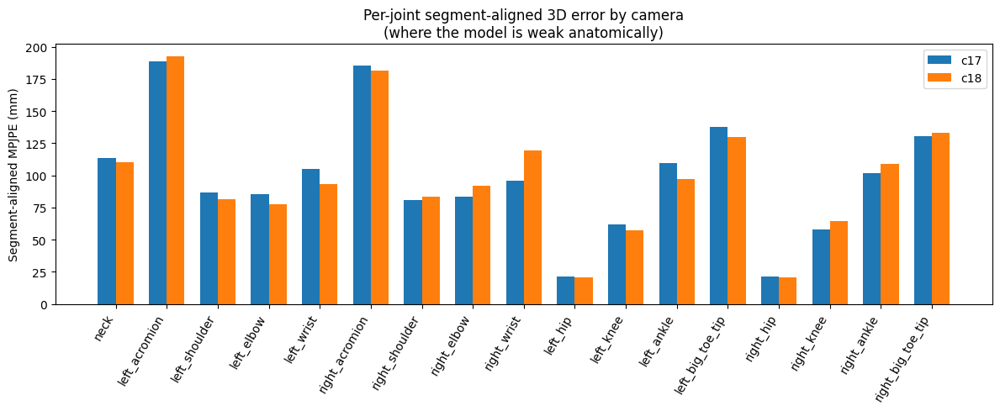

In [ ]:
# ============================================================
# Cell 16b - T1 figure: per-joint SEGMENT-ALIGNED MPJPE bar chart, by camera
# ============================================================
# Uses pa_cols (segment-aligned), NOT root_cols: root-relative error still
# contains the unreconciled pred/GT rotation (Cell 14 header, Cell 16c
# experiment), so a per-joint root-relative chart would rank joints by an
# artefact of that rotation rather than by anatomical difficulty.
per_joint_root_mean = ok_df.groupby("camera")[pa_cols].mean()

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(labels))
width = 0.35
for i, cam in enumerate(per_joint_root_mean.index):
    ax.bar(x + i * width, per_joint_root_mean.loc[cam].values, width, label=cam)
ax.set_xticks(x + width / 2)
ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_ylabel("Segment-aligned MPJPE (mm)")
ax.set_title("Per-joint segment-aligned 3D error by camera\n"
             "(where the model is weak anatomically)")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# Cell 16c - Axis-reconciliation experiment: can root-relative MPJPE be rescued?
# ============================================================
# The problem (Cell 14 header): predictions are body-centred in the model's
# own MHR convention; REHAB24 mocap GT is world-space Y-up. Nothing
# reconciles them, so root_mpjpe_mm currently contains an unknown fixed
# rotation on top of any real error. NOTE: this model's convention is NOT
# necessarily the one the InstantHMR ONNX export used, so the verdict reached
# in that notebook does NOT transfer -- this experiment must be re-run here.
# The transform diagnostics DESCRIBE this
# (a fitted rotation near 180 deg is consistent with an axis flip) but a
# rotation angle alone does not say WHICH axes differ -- 180 deg about X, Y
# or Z are all "180 deg".
#
# LIMITED DIAGNOSTIC -- it cannot identify the transform. The 24 signed axis
# permutations are a tiny subset of rotations. Predictions are camera-frame and
# GT is world-frame, so the true relation includes each camera's EXTRINSIC
# rotation, which can be arbitrary and differs between Camera17 and Camera18.
# A "winning" permutation is therefore at most the closest axis-aligned
# approximation, reported per camera. It is not evidence that a convention was
# identified. The reportable 3D metric remains the segment-aligned pa_mpjpe_mm;
# root_mpjpe_mm stays diagnostic-only.
#
# Requires raw per-frame joints, which the batch CSV does not retain, so this
# re-runs inference on a small sample.

N_AXIS_CALIB_SEGMENTS = 6
import itertools

def _proper_rotation_candidates():
    """The 24 signed axis permutations with determinant +1 (proper rotations).
    Reflections (det = -1) are excluded: a coordinate-convention difference
    between two right-handed systems cannot be a reflection."""
    cands = []
    for perm in itertools.permutations(range(3)):
        for signs in itertools.product([1, -1], repeat=3):
            M = np.zeros((3, 3))
            for row, (col, s) in enumerate(zip(perm, signs)):
                M[row, col] = s
            if np.isclose(np.linalg.det(M), 1.0):
                cands.append(M)
    return cands

AXIS_CANDIDATES = _proper_rotation_candidates()
print(f"Testing {len(AXIS_CANDIDATES)} proper-rotation axis conventions "
      f"on {N_AXIS_CALIB_SEGMENTS} sampled segments...")

calib_sample = ok_df.sample(n=min(N_AXIS_CALIB_SEGMENTS, len(ok_df)), random_state=BATCH_SEED)
lh_i, rh_i = labels.index("left_hip"), labels.index("right_hip")

per_segment_scores = []   # each entry: (identifier, np.array of 24 mean errors in mm)
for _, r in calib_sample.iterrows():
    video_path = (f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera17-30fps.mp4"
                  if r["camera"] == "c17" else
                  f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera18-30fps-transposed.mp4")
    try:
        gt3d_s = np.load(f"/content/drive/MyDrive/REHAB/3d_joints/{r['exercise']}/{r['subject']}-30fps.npy")
        pred = run_pipeline_on_video(video_path, int(r["seg_start"]), int(r["seg_end"]))
        n = len(pred["joints_3d"])
        gt_win = gt3d_s[pred["start_frame"]: pred["start_frame"] + n, :, :3]
        n_common = min(n, gt_win.shape[0])
        p_ok = np.isfinite(pred["joints_3d"][:n_common][:, mhr_ids, :]).all(axis=(1, 2))
        g_ok = np.isfinite(gt_win[:n_common][:, rehab_ids, :]).all(axis=(1, 2))
        v = p_ok & g_ok
        if v.sum() < 2:
            continue
        P = pred["joints_3d"][:n_common][v][:, mhr_ids, :]
        G = gt_win[:n_common][v][:, rehab_ids, :]
        G_rel = G - ((G[:, lh_i] + G[:, rh_i]) / 2.0)[:, None, :]

        scores = []
        for M in AXIS_CANDIDATES:
            P_rot = P @ M.T
            P_rel = P_rot - ((P_rot[:, lh_i] + P_rot[:, rh_i]) / 2.0)[:, None, :]
            scores.append(np.linalg.norm(P_rel - G_rel, axis=-1).mean() * 1000.0)
        per_segment_scores.append(
            (f"{r['subject']}/{r['exercise']}/{r['camera']}/rep{r['rep']}", np.array(scores))
        )
    except Exception as e:
        print(f"  [warn] skipped {r['subject']}/{r['exercise']}/{r['camera']}: {e}")

if len(per_segment_scores) == 0:
    print("[error] no segments could be evaluated -- cannot run the experiment.")
else:
    all_scores = np.stack([s for _, s in per_segment_scores])   # (n_segments, 24)
    winners = all_scores.argmin(axis=1)
    unique, counts = np.unique(winners, return_counts=True)
    best_idx = unique[counts.argmax()]
    agreement = counts.max() / len(winners)

    mean_err = all_scores.mean(axis=0)
    order = mean_err.argsort()
    print(f"\nPer-segment winning candidate agreement: "
          f"{counts.max()}/{len(winners)} segments ({agreement*100:.0f}%) "
          f"chose candidate #{best_idx}")
    print(f"\nBest candidate matrix (pred @ M.T reconciles pred axes to GT):\n{AXIS_CANDIDATES[best_idx]}")
    print(f"\nMean root-relative error, best 3 candidates vs current (identity) handling:")
    identity_idx = next(i for i, M in enumerate(AXIS_CANDIDATES) if np.allclose(M, np.eye(3)))
    for rank, ci in enumerate(order[:3]):
        print(f"  #{rank+1}: candidate {ci:2d} -> {mean_err[ci]:8.1f} mm")
    print(f"  current (identity, candidate {identity_idx}) -> {mean_err[identity_idx]:8.1f} mm")

    margin = mean_err[order[1]] - mean_err[order[0]]
    print(f"\nMargin between best and second-best (pooled): {margin:.1f} mm")
    # Per camera: extrinsics differ between views, so pooling can hide a split.
    for _cam in ("c17", "c18"):
        _rows = [s for ident, s in per_segment_scores if f"/{_cam}/" in ident]
        if _rows:
            _w = np.stack(_rows).argmin(axis=1)
            _u, _c = np.unique(_w, return_counts=True)
            print(f"  {_cam}: best permutation #{_u[_c.argmax()]} on {_c.max()}/{len(_w)} segments")
    print("\nDiagnostic only: the closest AXIS-ALIGNED approximation, not an identified")
    print("transform (camera extrinsics can be arbitrary rotations and differ by view).")
    print("Report pa_mpjpe_mm; keep root_mpjpe_mm diagnostic-only.")


Testing 24 proper-rotation axis conventions on 6 sampled segments...

Per-segment winning candidate agreement: 3/6 segments (50%) chose candidate #1

Best candidate matrix (pred @ M.T reconciles pred axes to GT):
[[          1           0           0]
 [          0          -1           0]
 [          0           0          -1]]

Mean root-relative error, best 3 candidates vs current (identity) handling:
  #1: candidate  1 ->    223.4 mm
  #2: candidate 21 ->    331.0 mm
  #3: candidate 23 ->    363.0 mm
  current (identity, candidate 0) ->   1094.6 mm

Margin between best and second-best (pooled): 107.6 mm
  c17: best permutation #21 on 3/3 segments
  c18: best permutation #1 on 3/3 segments

Diagnostic only: the closest AXIS-ALIGNED approximation, not an identified
transform (camera extrinsics can be arbitrary rotations and differ by view).
Report pa_mpjpe_mm; keep root_mpjpe_mm diagnostic-only.


In [ ]:
# ============================================================
# Cell 17 - Temporal pose accuracy: MPJVE by camera x exercise
# ============================================================
mpjve_cols = [f"mpjve_mms__{lbl}" for lbl in labels]

temporal_rows = []
for (ex, cam), sub in ok_df.groupby(["exercise", "camera"]):
    roll = region_rollup(sub, mpjve_cols, "mpjve")
    row = {"exercise": ex, "camera": cam, "n_segments": len(sub)}
    for c in roll.columns:
        row[c] = roll[c].mean()
    temporal_rows.append(row)

temporal_table = pd.DataFrame(temporal_rows).sort_values(["exercise", "camera"]).reset_index(drop=True)
print("Temporal accuracy (MPJVE, mm/s) by exercise x camera:")
print("  ROOT-RELATIVE velocity error (limb articulation), computed on the same")
print("  segment-level similarity-aligned trajectory as pa_mpjpe_mm (Cell 14),")
print("  using only truly consecutive frame pairs.")
print("  A global-translation MPJVE is deliberately NOT reported: Cell 6 stores")
print("  joints_3d_local and discards the model's cam_trans, so predictions carry")
print("  no global translation -- a global variant would score the GT's whole-body")
print("  motion as model error rather than measuring global tracking.")
print(temporal_table)
print()
print("Jerk-based smoothness (Cell 9's dimensionless_jerk) remains a separate")
print("KINEMATIC SMOOTHNESS feature (Table I) -- it is not a substitute for MPJVE,")
print("which measures raw tracking velocity error, not movement quality.")
print("Note its direction: dimensionless_jerk returns a negative log, so HIGHER")
print("values mean SMOOTHER movement.")
temporal_table


Temporal accuracy (MPJVE, mm/s) by exercise x camera:
  ROOT-RELATIVE velocity error (limb articulation), computed on the same
  segment-level similarity-aligned trajectory as pa_mpjpe_mm (Cell 14),
  using only truly consecutive frame pairs.
  A global-translation MPJVE is deliberately NOT reported: Cell 6 stores
  joints_3d_local and discards the model's cam_trans, so predictions carry
  no global translation -- a global variant would score the GT's whole-body
  motion as model error rather than measuring global tracking.
   exercise camera  n_segments  mpjve_trunk_mm  mpjve_upper_limb_mm  \
0       Ex1    c17         178       69.737814           158.280482   
1       Ex1    c18         178       60.861105           203.182644   
2       Ex2    c17         208       70.274657           203.682099   
3       Ex2    c18         208       82.464211           314.752501   
4       Ex3    c17         107      143.010319           370.202396   
5       Ex3    c18         107      105.4740

,exercise,camera,n_segments,mpjve_trunk_mm,mpjve_upper_limb_mm,mpjve_lower_limb_mm,mpjve_overall_mm
0,Ex1,c17,178,69.737814,158.280482,168.989719,136.018251
1,Ex1,c18,178,60.861105,203.182644,119.391599,131.750057
2,Ex2,c17,208,70.274657,203.682099,155.919172,147.587112
3,Ex2,c18,208,82.464211,314.752501,134.772908,182.910206
4,Ex3,c17,107,143.010319,370.202396,246.072310,259.570578
5,Ex3,c18,107,105.474070,245.229649,280.698702,216.643556
6,Ex4,c17,210,107.799490,187.723125,403.753627,240.462233
7,Ex4,c18,210,102.274306,198.805567,386.422032,236.631595
8,Ex5,c17,174,96.727683,223.807021,245.043746,193.926060
9,Ex5,c18,174,101.074715,308.908350,258.355445,229.938609


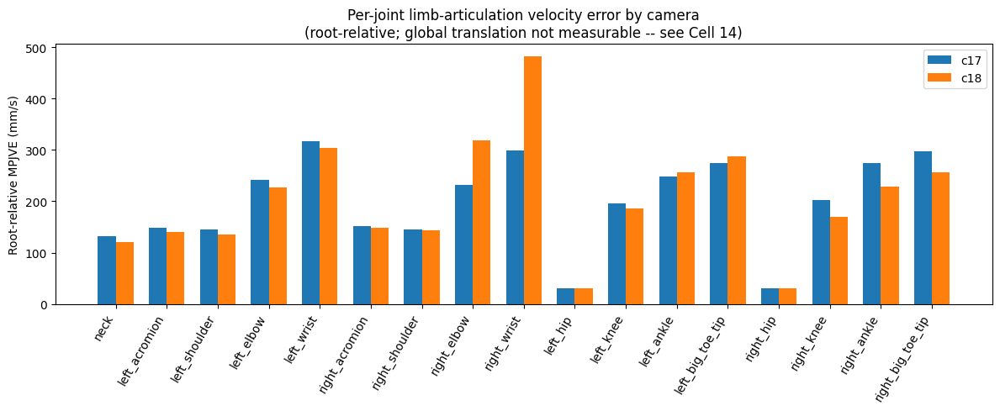

In [ ]:
# ============================================================
# Cell 17b - MPJVE figure: per-joint velocity error bar chart, by camera
# ============================================================
per_joint_mpjve_mean = ok_df.groupby("camera")[mpjve_cols].mean()

fig, ax = plt.subplots(figsize=(12, 5))
for i, cam in enumerate(per_joint_mpjve_mean.index):
    ax.bar(x + i * width, per_joint_mpjve_mean.loc[cam].values, width, label=cam)
ax.set_xticks(x + width / 2)
ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_ylabel("Root-relative MPJVE (mm/s)")
ax.set_title("Per-joint limb-articulation velocity error by camera\n"
             "(root-relative; global translation not measurable -- see Cell 14)")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# Cell 17c - MPJVE spike diagnostics: wrong-person frames vs genuine motion
# ============================================================
# The MPJVE formula (Cell 14) passed synthetic checks -- root-relative
# alignment, no differencing across missing-frame gaps -- so a high MPJVE is
# not by itself evidence of a formula bug. The main NON-model cause of velocity
# spikes is PERSON SELECTION: frames whose skeleton belongs to someone else.
# From the cached per-frame data (chosen bbox, n_persons, track_iou) this
# finds velocity spikes in each predicted trajectory and checks whether they
# coincide with multi-person frames or tracker re-initialisations, and
# cross-references REHAB24's own extra_person_in_cam17/18 annotation.
SPIKE_MMS = 3000.0          # root-relative joint speed (mm/s) counted as a spike
DIAG_MAX_SEGMENTS = None    # None = all usable rows; an int samples for speed
FPS_DIAG = 30.0

def _rc17(j3):            # root-centre on the hip midpoint (MHR-70: 9/10)
    return j3 - ((j3[:, 9] + j3[:, 10]) / 2.0)[:, None, :]

def _diag_video_path(r):
    return (f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera17-30fps.mp4"
            if r["camera"] == "c17" else
            f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera18-30fps-transposed.mp4")

_ann = seg.set_index(["video_id", "exercise_id", "repetition_number"])
_rows = ok_df if DIAG_MAX_SEGMENTS is None else ok_df.sample(
    n=min(DIAG_MAX_SEGMENTS, len(ok_df)), random_state=BATCH_SEED)
mpjve_cols_all = [c for c in ok_df.columns if c.startswith("mpjve_mms__")]
diag = []
for _, r in _rows.iterrows():
    try:
        p = run_pipeline_on_video(_diag_video_path(r), int(r["seg_start"]), int(r["seg_end"]))
    except Exception as e:
        print(f"  [skip] {r['subject']}/{r['exercise']}/{r['camera']}/rep{r['rep']}: {e}")
        continue
    det = np.where(p["detected"])[0]
    pairs = det[:-1][np.diff(det) == 1]                  # truly consecutive frames only
    j = _rc17(p["joints_3d"])[:, mhr_ids] * 1000.0 if len(det) else None
    n_spk = spk_multi = spk_reinit = 0
    if len(pairs):
        speed = np.linalg.norm(j[pairs + 1] - j[pairs], axis=-1).max(axis=1) * FPS_DIAG
        spk = pairs[speed > SPIKE_MMS]
        n_spk = len(spk)
        multi = (p["n_persons"] > 1)
        reinit = np.isnan(p["track_iou"])
        spk_multi = int(np.sum(multi[spk] | multi[spk + 1]))
        spk_reinit = int(np.sum(reinit[spk + 1]))
    try:
        a = _ann.loc[(r["subject"], int(str(r["exercise"])[2:]), int(r["rep"]))]
        extra = int(a[f"extra_person_in_cam{str(r['camera'])[1:]}"])
    except Exception:
        extra = np.nan
    diag.append({"subject": r["subject"], "exercise": r["exercise"], "camera": r["camera"],
                 "rep": r["rep"], "mpjve_mean_mms": float(r[mpjve_cols_all].mean()),
                 "n_spikes": n_spk, "spikes_in_multi_person_frames": spk_multi,
                 "spikes_at_tracker_reinit": spk_reinit,
                 "frac_multi_person": float((p["n_persons"][p["processed"]] > 1).mean())
                                      if p["processed"].any() else np.nan,
                 "extra_person_annotated": extra})
spike_diag = pd.DataFrame(diag)

if len(spike_diag):
    tot = int(spike_diag["n_spikes"].sum())
    print(f"{len(spike_diag)} segments, {tot} spikes > {SPIKE_MMS:.0f} mm/s")
    if tot:
        print(f"  {int(spike_diag['spikes_in_multi_person_frames'].sum())} of them in frames with >1 person "
              f"detected; {int(spike_diag['spikes_at_tracker_reinit'].sum())} at a tracker re-initialisation")
    print("\nMean MPJVE by REHAB24 extra-person annotation (0 = none), per camera:")
    print(spike_diag.groupby(["camera", "extra_person_annotated"])["mpjve_mean_mms"]
          .agg(["count", "median", "mean"]).round(1).to_string())
    print("\nHighest-MPJVE segments:")
    print(spike_diag.sort_values("mpjve_mean_mms", ascending=False).head(15).to_string(index=False))
    print("\nIf the worst segments concentrate where extra persons are annotated/detected,")
    print("inspect them with Cell 22's renderers before attributing MPJVE to the model.")
spike_diag


2144 segments, 4310 spikes > 3000 mm/s
  425 of them in frames with >1 person detected; 14 at a tracker re-initialisation

Mean MPJVE by REHAB24 extra-person annotation (0 = none), per camera:
                               count  median   mean
camera extra_person_annotated                      
c17    0                         686   171.3  191.8
       1                         117   181.0  192.0
       2                         206   191.1  205.8
       3                          63   232.3  253.5
c18    0                        1030   179.2  201.6
       1                          34   248.3  272.1
       2                           4   233.1  222.5
       3                           4   166.5  196.7

Highest-MPJVE segments:
subject exercise camera  rep  mpjve_mean_mms  n_spikes  spikes_in_multi_person_frames  spikes_at_tracker_reinit  frac_multi_person  extra_person_annotated
 PM_021      Ex5    c18    5     2092.059122        51                              0                      

,subject,exercise,camera,rep,mpjve_mean_mms,n_spikes,spikes_in_multi_person_frames,spikes_at_tracker_reinit,frac_multi_person,extra_person_annotated
0,PM_000,Ex1,c17,1,138.922966,0,0,0,1.000000,3
1,PM_000,Ex1,c18,1,157.570439,7,0,0,0.000000,0
2,PM_000,Ex1,c17,2,163.516538,0,0,0,1.000000,3
3,PM_000,Ex1,c18,2,138.882182,2,0,0,0.000000,0
4,PM_000,Ex1,c17,3,166.178588,0,0,0,1.000000,3
...,...,...,...,...,...,...,...,...,...,...
2139,PM_126,Ex6,c18,18,195.638263,1,0,0,0.000000,0
2140,PM_126,Ex6,c17,19,195.032727,0,0,0,0.891892,0
2141,PM_126,Ex6,c18,19,173.923870,0,0,0,0.000000,0
2142,PM_126,Ex6,c17,20,190.558344,0,0,0,0.752066,0


In [ ]:
# ============================================================
# Cell 18 - Kinematic feature agreement: MAE, CCC, Bland-Altman, Spearman rho
# ============================================================
# Correlation alone (Pearson/Spearman) shows association, not agreement -- a
# constant offset between predicted and GT features gives r=1.0 while being
# clinically useless. CCC and Bland-Altman were validated locally against a
# synthetic case with a known +5 bias: Pearson r=1.0 but CCC dropped to ~0.05
# and Bland-Altman correctly recovered the bias -- confirming they catch what
# correlation alone hides.
from scipy.stats import spearmanr

def subject_cluster_bootstrap_ci(df, stat_fn, n_boot=2000, alpha=0.05, seed=0):
    """Percentile CI resampling RECORDING IDs (clusters), not rows.

    Rows here are (subject, repetition) observations: multiple repetitions
    from the same recording are NOT independent, so a row-level bootstrap
    would understate the interval. Resampling whole recordings with
    replacement preserves the within-recording correlation.

    NOTE this clusters on `subject` (a RECORDING ID). REHAB24-6 is
    documented as ~10 participants and no recording->participant mapping
    ships with the data, so if one participant contributed several
    recordings these intervals are still slightly optimistic. That is a
    dataset-metadata limit, not something the resampling can fix.
    """
    rng = np.random.default_rng(seed)
    groups = [g for _, g in df.groupby('subject')]
    if len(groups) < 2:
        return float('nan'), float('nan')
    stats = []
    for _ in range(n_boot):
        picked = rng.integers(0, len(groups), size=len(groups))
        boot = pd.concat([groups[i] for i in picked], ignore_index=True)
        try:
            s = stat_fn(boot)
        except Exception:
            s = np.nan
        if np.isfinite(s):
            stats.append(s)
    if len(stats) < 10:
        return float('nan'), float('nan')
    return (float(np.percentile(stats, 100 * alpha / 2)),
            float(np.percentile(stats, 100 * (1 - alpha / 2))))


def concordance_corr_coef(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(), y.var()
    sxy = ((x - mx) * (y - my)).mean()
    return (2 * sxy) / (vx + vy + (mx - my) ** 2 + 1e-12)

def bland_altman(pred, ref):
    d = np.asarray(pred, dtype=float) - np.asarray(ref, dtype=float)
    bias = d.mean()
    sd = d.std(ddof=1) if len(d) > 1 else np.nan
    return bias, (bias - 1.96 * sd, bias + 1.96 * sd)

FEATURE_KEYS = ["right_upperarm_trunk", "right_elbow", "left_upperarm_trunk", "left_elbow"]

agreement_rows = []
for (ex, cam), sub in ok_df.groupby(["exercise", "camera"]):
    for key in FEATURE_KEYS:
        pred_col, gt_col = f"ROM_pred_{key}_deg", f"ROM_gt_{key}_deg"
        # rows whose ROM failed the coverage gate (Cell 14) are NaN -- drop them
        ks = sub.dropna(subset=[pred_col, gt_col])
        p, g = ks[pred_col].values, ks[gt_col].values
        row = {"exercise": ex, "camera": cam, "feature": f"ROM_{key}",
               "n_segments": len(ks), "n_recordings": ks["subject"].nunique(),
               "n_excluded_low_coverage": len(sub) - len(ks)}

        # --- descriptive agreement (per-segment, as before) ---
        row["MAE_deg"] = float(np.abs(p - g).mean()) if len(p) else float("nan")
        row["CCC"] = float(concordance_corr_coef(p, g)) if len(p) > 1 else float("nan")
        bias, (loa_lo, loa_hi) = bland_altman(p, g)
        row["BA_bias_deg"] = float(bias)
        row["BA_LoA_low_deg"] = float(loa_lo)
        row["BA_LoA_high_deg"] = float(loa_hi)

        # --- recording-clustered CIs on the two headline estimates ---
        mae_lo, mae_hi = subject_cluster_bootstrap_ci(
            ks, lambda d: np.abs(d[pred_col].values - d[gt_col].values).mean())
        ccc_lo, ccc_hi = subject_cluster_bootstrap_ci(
            ks, lambda d: concordance_corr_coef(d[pred_col].values, d[gt_col].values))
        row["MAE_CI_low"], row["MAE_CI_high"] = mae_lo, mae_hi
        row["CCC_CI_low"], row["CCC_CI_high"] = ccc_lo, ccc_hi

        # --- inferential test on RECORDING-AGGREGATED data ---
        # Repetitions from one recording are not independent draws, so the
        # p-value is computed on one (mean pred, mean gt) pair per recording.
        # The per-segment Spearman that used to be reported here treated every
        # repetition as independent and therefore had an anticonservative p.
        agg = ks.groupby("subject")[[pred_col, gt_col]].mean()
        row["n_recordings_for_test"] = len(agg)
        if len(agg) > 2:
            rho, pval = spearmanr(agg[pred_col].values, agg[gt_col].values)
            row["spearman_rho_recordingwise"] = float(rho)
            row["spearman_p_recordingwise"] = float(pval)
        else:
            row["spearman_rho_recordingwise"] = float("nan")
            row["spearman_p_recordingwise"] = float("nan")
        agreement_rows.append(row)

feature_agreement_table = pd.DataFrame(agreement_rows)
print("Feature agreement, per exercise x camera x feature:")
print("  MAE / CCC / Bland-Altman are DESCRIPTIVE, computed per segment.")
print("  CIs are percentile bootstrap resampling RECORDINGS (clusters), not rows.")
print("  Spearman is computed on RECORDING-AGGREGATED pairs (one mean per")
print("  recording), because repetitions within a recording are not independent.")
print(f"[CAVEAT] {ok_df['subject'].nunique()} recording IDs contributed; recording IDs")
print("  are not verified participant IDs (REHAB24-6 documents ~10 participants),")
print("  so even the clustered intervals may remain slightly optimistic.")
feature_agreement_table


Feature agreement, per exercise x camera x feature:
  MAE / CCC / Bland-Altman are DESCRIPTIVE, computed per segment.
  CIs are percentile bootstrap resampling RECORDINGS (clusters), not rows.
  Spearman is computed on RECORDING-AGGREGATED pairs (one mean per
  recording), because repetitions within a recording are not independent.
[CAVEAT] 65 recording IDs contributed; recording IDs
  are not verified participant IDs (REHAB24-6 documents ~10 participants),
  so even the clustered intervals may remain slightly optimistic.


,exercise,camera,feature,n_segments,n_recordings,n_excluded_low_coverage,MAE_deg,CCC,BA_bias_deg,BA_LoA_low_deg,BA_LoA_high_deg,MAE_CI_low,MAE_CI_high,CCC_CI_low,CCC_CI_high,n_recordings_for_test,spearman_rho_recordingwise,spearman_p_recordingwise
0,Ex1,c17,ROM_right_upperarm_trunk,178,13,0,4.244513,0.932641,-3.717223,-11.181770,3.747325,2.678629,5.692633,0.871106,0.962548,13,0.934066,2.998704e-06
1,Ex1,c17,ROM_right_elbow,178,13,0,6.247289,0.767692,4.070294,-10.425832,18.566420,4.598071,7.928068,0.552836,0.879785,13,0.956044,3.365097e-07
2,Ex1,c17,ROM_left_upperarm_trunk,178,13,0,2.147073,0.113416,1.759587,-6.606162,10.125335,1.074887,3.730978,-0.016958,0.750249,13,-0.065934,8.305424e-01
3,Ex1,c17,ROM_left_elbow,178,13,0,5.471688,0.301181,5.448558,0.341012,10.556105,4.555832,6.752472,0.016014,0.603926,13,0.554945,4.900450e-02
4,Ex1,c18,ROM_right_upperarm_trunk,178,13,0,15.736565,0.379669,-15.240495,-64.392385,33.911395,9.520239,22.962566,0.222800,0.541730,13,0.543956,5.464653e-02
5,Ex1,c18,ROM_right_elbow,178,13,0,27.398769,0.052398,24.535949,-37.938497,87.010396,19.552301,37.765909,-0.016615,0.203433,13,0.032967,9.148565e-01
6,Ex1,c18,ROM_left_upperarm_trunk,178,13,0,1.421846,0.566657,0.699663,-2.401240,3.800567,1.158069,1.699849,0.150399,0.755859,13,0.401099,1.743575e-01
7,Ex1,c18,ROM_left_elbow,178,13,0,3.643997,0.429012,3.561664,-0.815529,7.938857,3.053794,4.431218,0.022587,0.712627,13,0.208791,4.936218e-01
8,Ex2,c17,ROM_right_upperarm_trunk,208,12,0,5.370305,0.886115,1.197815,-12.330650,14.726280,4.266355,6.535705,0.815735,0.926473,12,0.867133,2.598118e-04
9,Ex2,c17,ROM_right_elbow,208,12,0,12.787214,0.639844,-11.237213,-33.997914,11.523489,8.710446,17.705909,0.395467,0.838199,12,0.825175,9.513629e-04


In [ ]:
# ============================================================
# Cell 18b - No-pooling guardrail: pooled-across-exercises CCC vs. per-exercise low
# ============================================================
# Cell 18 already groups by (exercise, camera) so it isn't itself pooled --
# but nothing stops a future paper draft from computing and citing a
# further-pooled "headline" CCC instead of the per-exercise breakdown. This
# cell makes that risk visible and self-documenting: it computes the SAME
# metric pooled across exercises, compares it against the per-exercise
# range, and flags any (camera, feature) where pooling would hide a real
# per-exercise failure (the motivating case: Camera18's right-arm ROM CCC is
# ~0.097 for Ex1 alone, but ~0.765 when pooled across all 6 exercises --
# looks fine pooled, is not fine for Ex1).

CCC_POOR_THRESHOLD = 0.3   # a per-exercise CCC below this counts as "poor agreement"
CCC_GAP_FLAG = 0.3         # pooled-minus-worst-exercise gap that triggers a warning

pooled_rows = []
for cam in sorted(ok_df["camera"].unique()):
    cam_df = ok_df[ok_df["camera"] == cam]
    for key in FEATURE_KEYS:
        _k = cam_df.dropna(subset=[f"ROM_pred_{key}_deg", f"ROM_gt_{key}_deg"])  # coverage gate
        p, g = _k[f"ROM_pred_{key}_deg"].values, _k[f"ROM_gt_{key}_deg"].values
        pooled_ccc = float(concordance_corr_coef(p, g)) if len(p) > 1 else float("nan")
        pooled_rows.append({"camera": cam, "feature": f"ROM_{key}", "n_pooled": len(p),
                             "pooled_CCC": pooled_ccc})

pooled_agreement_table = pd.DataFrame(pooled_rows)

per_exercise_extremes = (
    feature_agreement_table.groupby(["camera", "feature"])["CCC"]
    .agg(min_exercise_CCC="min", max_exercise_CCC="max")
    .reset_index()
)
pooled_agreement_table = pooled_agreement_table.merge(
    per_exercise_extremes, on=["camera", "feature"], how="left"
)
pooled_agreement_table["pool_hides_gap"] = (
    (pooled_agreement_table["pooled_CCC"] - pooled_agreement_table["min_exercise_CCC"]) > CCC_GAP_FLAG
) & (pooled_agreement_table["min_exercise_CCC"] < CCC_POOR_THRESHOLD)

n_flagged = 0
for _, r in pooled_agreement_table.iterrows():
    if r["pool_hides_gap"]:
        n_flagged += 1
        # Identify which exercise actually produced the worst-case CCC, for a
        # concrete, citable warning message rather than just the number.
        worst = feature_agreement_table[
            (feature_agreement_table["camera"] == r["camera"]) &
            (feature_agreement_table["feature"] == r["feature"]) &
            (feature_agreement_table["CCC"] == r["min_exercise_CCC"])
        ]
        worst_ex = worst["exercise"].iloc[0] if len(worst) else "?"
        print(f"[POOLING GUARDRAIL] {r['camera']} / {r['feature']}: pooled CCC="
              f"{r['pooled_CCC']:.3f} masks a per-exercise low of "
              f"{r['min_exercise_CCC']:.3f} ({worst_ex}) -- cite the per-exercise "
              f"table (Cell 18), not this pooled number.")

if n_flagged == 0:
    print(f"No pooling risk detected at current thresholds "
          f"(CCC_POOR_THRESHOLD={CCC_POOR_THRESHOLD}, CCC_GAP_FLAG={CCC_GAP_FLAG}).")
else:
    print(f"\n{n_flagged} (camera, feature) pair(s) flagged above.")

pooled_agreement_table


[POOLING GUARDRAIL] c17 / ROM_left_upperarm_trunk: pooled CCC=0.974 masks a per-exercise low of 0.113 (Ex1) -- cite the per-exercise table (Cell 18), not this pooled number.
[POOLING GUARDRAIL] c18 / ROM_right_upperarm_trunk: pooled CCC=0.915 masks a per-exercise low of -0.010 (Ex3) -- cite the per-exercise table (Cell 18), not this pooled number.
[POOLING GUARDRAIL] c18 / ROM_right_elbow: pooled CCC=0.813 masks a per-exercise low of 0.052 (Ex1) -- cite the per-exercise table (Cell 18), not this pooled number.
[POOLING GUARDRAIL] c18 / ROM_left_upperarm_trunk: pooled CCC=0.948 masks a per-exercise low of 0.086 (Ex3) -- cite the per-exercise table (Cell 18), not this pooled number.

4 (camera, feature) pair(s) flagged above.


,camera,feature,n_pooled,pooled_CCC,min_exercise_CCC,max_exercise_CCC,pool_hides_gap
0,c17,ROM_right_upperarm_trunk,1072,0.983615,0.631938,0.950635,False
1,c17,ROM_right_elbow,1072,0.946447,0.636852,0.948639,False
2,c17,ROM_left_upperarm_trunk,1072,0.973538,0.113416,0.948285,True
3,c17,ROM_left_elbow,1072,0.928731,0.301181,0.737471,False
4,c18,ROM_right_upperarm_trunk,1065,0.915065,-0.009698,0.971353,True
5,c18,ROM_right_elbow,1065,0.813030,0.052398,0.707300,True
6,c18,ROM_left_upperarm_trunk,1065,0.947855,0.085735,0.958881,True
7,c18,ROM_left_elbow,1065,0.925439,0.429012,0.769546,False


In [ ]:
# ============================================================
# Cell 19 - Correctness-information preservation (replaces physician-score
#           correlation, which this dataset cannot support -- no cTS/clinical
#           rating exists in rehab/, only the binary `correctness` label)
# ============================================================
# Question: does Fast-SAM-3D-Body's estimated kinematics preserve enough signal to
# distinguish correct vs. incorrect repetitions -- the way the GT mocap
# kinematics do?
#
# FIXED (was seriously buggy): the previous version reported
# max(auc, 1 - auc) SEPARATELY for the GT and predicted features. That flips
# each one independently, so a model whose feature ranks correct/incorrect
# EXACTLY BACKWARDS (raw AUROC 0.00) was reported as 1.00 -- indistinguishable
# from a perfect model -- and the old "retained fraction" then claimed 100%
# of the signal survived. Verified on a synthetic reversal case: raw GT=1.00 /
# pred=0.00 was reported as GT=1.00 / pred=1.00 / retained=100%.
#
# Correct handling: choose the score direction ONCE, from the GT feature
# (higher-is-correct vs lower-is-correct is a property of the exercise, not
# of the model), then apply that SAME direction to both GT and predicted
# features and report ordinary AUROC. A reversed model now correctly shows
# up below 0.5.
#
# The "retained fraction" is removed entirely: its denominator (GT_AUROC-0.5)
# goes to zero whenever the GT feature itself is near chance, making the ratio
# explode or flip sign for reasons that have nothing to do with the model.
#
# GT-feature AUROC is a REFERENCE COMPARATOR, not a performance ceiling --
# nothing prevents a predicted feature from separating the classes better
# than the GT feature does (noise can help by chance, especially at small n).
from sklearn.metrics import roc_auc_score

auroc_rows = []
for ex, sub in ok_df.groupby("exercise"):
    labels_bin = sub["correctness"].values
    if len(np.unique(labels_bin)) < 2:
        print(f"  [skip] {ex}: only one correctness class present ({np.unique(labels_bin)}), AUROC undefined")
        continue
    for cam in sorted(sub["camera"].unique()):
        cam_sub = sub[sub["camera"] == cam]
        cam_labels = cam_sub["correctness"].values
        if len(np.unique(cam_labels)) < 2:
            continue
        row = {"exercise": ex, "camera": cam, "n": len(cam_sub)}
        for key in FEATURE_KEYS:
            _k = cam_sub.dropna(subset=[f"ROM_gt_{key}_deg", f"ROM_pred_{key}_deg"])  # coverage gate
            k_labels = _k["correctness"].values
            if len(np.unique(k_labels)) < 2:
                row[f"AUROC_gt_{key}"] = row[f"AUROC_pred_{key}"] = float("nan")
                row[f"direction_{key}"] = "n/a (one class after coverage gate)"
                continue
            gt_vals = _k[f"ROM_gt_{key}_deg"].values
            pred_vals = _k[f"ROM_pred_{key}_deg"].values

            # Direction fixed ONCE from GT, then applied to BOTH.
            gt_auc_raw = roc_auc_score(k_labels, gt_vals)
            direction = 1.0 if gt_auc_raw >= 0.5 else -1.0

            row[f"AUROC_gt_{key}"] = float(roc_auc_score(k_labels, direction * gt_vals))
            row[f"AUROC_pred_{key}"] = float(roc_auc_score(k_labels, direction * pred_vals))
            row[f"direction_{key}"] = "higher_is_correct" if direction > 0 else "lower_is_correct"
        auroc_rows.append(row)

correctness_auroc_table = pd.DataFrame(auroc_rows)
# EXPLORATORY: the score direction is chosen from the GT feature ON THIS SAME
# DATA, so AUROC_gt is >= 0.5 by construction -- an optimistically oriented
# reference, not an independent estimate. (AUROC_pred inherits the direction,
# so pred-vs-GT comparisons stay consistent.) Pre-specify directions per
# exercise before any confirmatory claim.
correctness_auroc_table["analysis"] = "exploratory: direction selected on the evaluated data"
print("[EXPLORATORY] direction chosen from GT on the same data -> AUROC_gt is >= 0.5 by")
print("construction and optimistic. Use this table descriptively, not as a test.")
print("Correctness-classification AUROC (0.5 = chance; BELOW 0.5 means the feature")
print("ranks correct/incorrect in the REVERSED direction relative to GT).")
print("Score direction is taken from the GT feature and applied identically to the")
print("predicted feature, so the two columns are directly comparable.")
print("GT AUROC is a reference comparator, NOT a ceiling -- a predicted feature can")
print("exceed it by chance, particularly at small n.")
correctness_auroc_table


[EXPLORATORY] direction chosen from GT on the same data -> AUROC_gt is >= 0.5 by
construction and optimistic. Use this table descriptively, not as a test.
Correctness-classification AUROC (0.5 = chance; BELOW 0.5 means the feature
ranks correct/incorrect in the REVERSED direction relative to GT).
Score direction is taken from the GT feature and applied identically to the
predicted feature, so the two columns are directly comparable.
GT AUROC is a reference comparator, NOT a ceiling -- a predicted feature can
exceed it by chance, particularly at small n.


,exercise,camera,n,AUROC_gt_right_upperarm_trunk,AUROC_pred_right_upperarm_trunk,direction_right_upperarm_trunk,AUROC_gt_right_elbow,AUROC_pred_right_elbow,direction_right_elbow,AUROC_gt_left_upperarm_trunk,AUROC_pred_left_upperarm_trunk,direction_left_upperarm_trunk,AUROC_gt_left_elbow,AUROC_pred_left_elbow,direction_left_elbow,analysis
0,Ex1,c17,178,0.674242,0.649242,higher_is_correct,0.585859,0.697348,lower_is_correct,0.709722,0.616919,lower_is_correct,0.633586,0.590278,lower_is_correct,exploratory: direction selected on the evaluat...
1,Ex1,c18,178,0.674242,0.550631,higher_is_correct,0.585859,0.403535,lower_is_correct,0.709722,0.657071,lower_is_correct,0.633586,0.517045,lower_is_correct,exploratory: direction selected on the evaluat...
2,Ex2,c17,208,0.512411,0.559817,lower_is_correct,0.601624,0.475271,lower_is_correct,0.532288,0.559444,lower_is_correct,0.581374,0.438596,lower_is_correct,exploratory: direction selected on the evaluat...
3,Ex2,c18,208,0.512411,0.545819,lower_is_correct,0.601624,0.504199,lower_is_correct,0.532288,0.562150,lower_is_correct,0.581374,0.553565,lower_is_correct,exploratory: direction selected on the evaluat...
4,Ex3,c17,107,0.759790,0.666783,higher_is_correct,0.577622,0.559091,higher_is_correct,0.778322,0.642308,higher_is_correct,0.540559,0.573427,higher_is_correct,exploratory: direction selected on the evaluat...
5,Ex3,c18,107,0.787915,0.285714,higher_is_correct,0.577431,0.542617,higher_is_correct,0.808723,0.404962,higher_is_correct,0.535014,0.601040,higher_is_correct,exploratory: direction selected on the evaluat...
6,Ex4,c17,210,0.599630,0.629815,lower_is_correct,0.507870,0.420185,higher_is_correct,0.684722,0.643241,lower_is_correct,0.633981,0.593796,lower_is_correct,exploratory: direction selected on the evaluat...
7,Ex4,c18,210,0.599630,0.665741,lower_is_correct,0.507870,0.374167,higher_is_correct,0.684722,0.715093,lower_is_correct,0.633981,0.641759,lower_is_correct,exploratory: direction selected on the evaluat...
8,Ex5,c17,174,0.662927,0.710604,higher_is_correct,0.597356,0.620459,higher_is_correct,0.509081,0.543403,higher_is_correct,0.502537,0.598024,higher_is_correct,exploratory: direction selected on the evaluat...
9,Ex5,c18,174,0.662927,0.592014,higher_is_correct,0.597356,0.612714,higher_is_correct,0.509081,0.555422,higher_is_correct,0.502537,0.519364,higher_is_correct,exploratory: direction selected on the evaluat...


1072 repetitions have BOTH camera views with a valid (non-NaN) result.
Paired segment-aligned MPJPE difference (c18 - c17): mean=-0.2mm, median=-0.5mm, std=19.7mm
Paired at the recording level: 65 recordings (from 1072 repetition-level pairs).
Wilcoxon signed-rank across recordings (c17 vs c18): stat=1063.0, p=0.9505
[CAVEAT] recording IDs are not verified participant IDs; with ~10 documented participants in REHAB24-6 this test may still overstate independence.


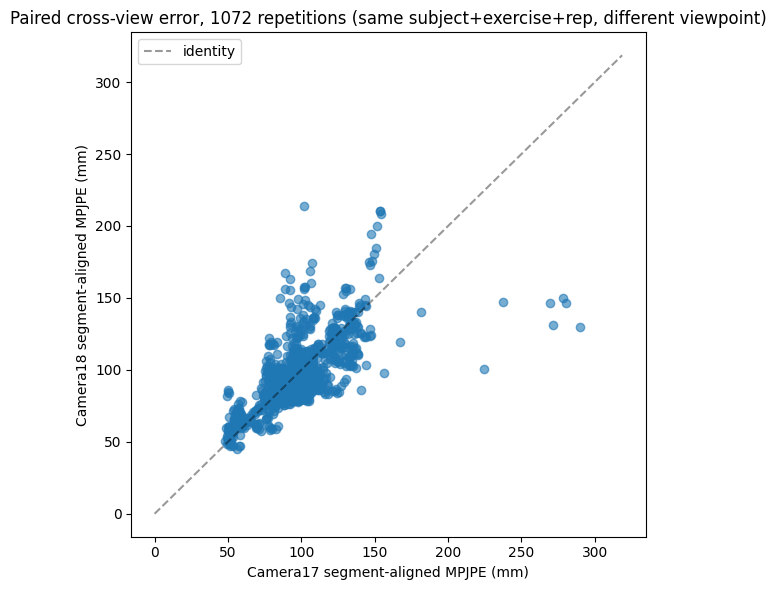

In [ ]:
# ============================================================
# Cell 20 - Cross-view robustness: paired Camera17 vs Camera18 comparison
#           (replaces the disease-subgroup figure, which this data cannot
#           support -- no health-condition labels exist in rehab/)
# ============================================================
# Because both cameras record the SAME physical repetition, pairing at the
# (subject, exercise, rep) level isolates viewpoint effects from subject/
# motion variability -- a fairer test than comparing unpaired per-camera
# aggregates (which is all Cells 16/17 show on their own).
# Uses segment-aligned (pa_) error, not root-relative: see Cell 14's header --
# root-relative still carries the unreconciled coordinate-frame rotation, which
# would contaminate a viewpoint comparison with a non-viewpoint artefact.
from scipy.stats import wilcoxon

pivot_root = ok_df.assign(
    pa_mean_mm=ok_df[pa_cols].mean(axis=1)
).pivot_table(index=["subject", "exercise", "rep"], columns="camera", values="pa_mean_mm")
paired = pivot_root.dropna()
print(f"{len(paired)} repetitions have BOTH camera views with a valid (non-NaN) result.")

if len(paired) >= 2 and {"c17", "c18"}.issubset(paired.columns):
    diff = paired["c18"] - paired["c17"]
    print(f"Paired segment-aligned MPJPE difference (c18 - c17): mean={diff.mean():.1f}mm, "
          f"median={diff.median():.1f}mm, std={diff.std():.1f}mm")
    # Inferential test on RECORDING-AGGREGATED pairs: repetitions within one
    # recording are not independent, so testing across repetitions (what this
    # previously did) is anticonservative. One mean c17/c18 pair per recording.
    paired_by_recording = paired.reset_index().groupby("subject")[["c17", "c18"]].mean()
    print(f"Paired at the recording level: {len(paired_by_recording)} recordings "
          f"(from {len(paired)} repetition-level pairs).")
    if len(paired_by_recording) >= 6:
        stat, pval = wilcoxon(paired_by_recording["c17"], paired_by_recording["c18"])
        print(f"Wilcoxon signed-rank across recordings (c17 vs c18): "
              f"stat={stat:.1f}, p={pval:.4f}")
    else:
        print(f"(only {len(paired_by_recording)} recordings -- too few for a reliable "
              f"Wilcoxon test; report the paired differences descriptively instead)")
    print("[CAVEAT] recording IDs are not verified participant IDs; with ~10 documented "
          "participants in REHAB24-6 this test may still overstate independence.")

    fig, ax = plt.subplots(figsize=(6, 6))
    lims = [0, max(paired["c17"].max(), paired["c18"].max()) * 1.1]
    ax.scatter(paired["c17"], paired["c18"], alpha=0.6)
    ax.plot(lims, lims, "k--", alpha=0.4, label="identity")
    ax.set_xlabel("Camera17 segment-aligned MPJPE (mm)")
    ax.set_ylabel("Camera18 segment-aligned MPJPE (mm)")
    ax.set_title(f"Paired cross-view error, {len(paired)} repetitions "
                 f"(same subject+exercise+rep, different viewpoint)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough paired data to plot -- check that both cameras succeeded "
          "(status == 'ok') for at least 2 shared (subject, exercise, rep) keys.")


In [ ]:
# ============================================================
# Cell 21 - Runtime: full-dataset latency distribution (not single-subject)
# ============================================================
# Honest scope notes (these DIFFER from the InstantHMR notebook -- read them):
#   - detector_ms = 0 does NOT mean detection is free: detection runs INSIDE
#     process_one_image(), so its cost is inside hmr_ms, which is the FULL
#     per-frame model cost. Splitting it out would be an arbitrary cut.
#   - hmr_ms IS a true independent per-frame measurement here (unlike the
#     InstantHMR notebook, where it was a batch average). There is no
#     across-frame batching API, so every frame is timed on its own and the
#     p95/p99 below are a genuine per-frame distribution -- not artificially
#     tightened by batch-averaging.
#   - The timer spans the whole process_one_image() call: detection, the
#     estimator's INTERNAL preprocessing (crop, colour conversion, batching),
#     inference and output unpacking. It EXCLUDES video decode and this
#     notebook's own per-frame work. Cell 21b's wall_clock_fps includes those
#     too, and is the one to cite.
#   - With FOV_MODE="per-video", the one-off intrinsics calibration runs
#     OFFLINE before timing (it reads frames from the whole video), so these are
#     per-frame costs "after offline calibration".
# What's below is the per-frame model cost across every frame that had a
# detection, in every segment evaluated in the batch -- not just one subject.
N_T6_LIVE_SEGMENTS = 10
if "timing_source" in ok_df.columns and (ok_df["timing_source"] == "worker").any():
    # The batch rows were inferred by PARALLEL WORKERS sharing the GPU: their
    # per-frame times measure contended throughput, not latency. Re-measure
    # live, in this single process, on a sample of segments.
    assert_no_workers_running()
    _t6 = ok_df.sample(n=min(N_T6_LIVE_SEGMENTS, len(ok_df)), random_state=BATCH_SEED)
    def _t6_path(r):
        return (f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera17-30fps.mp4"
                if r["camera"] == "c17" else
                f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera18-30fps-transposed.mp4")
    print(f"[T6] batch timings came from parallel workers (contended) -- measuring "
          f"live on {len(_t6)} segments instead...")
    for _, _r in _t6.iterrows():      # warm-up + per-video calibration, untimed
        run_pipeline_on_video(_t6_path(_r), int(_r["seg_start"]),
                              min(int(_r["seg_start"]) + 5, int(_r["seg_end"])), source="live")
    _lat = []
    for _, _r in _t6.iterrows():
        _p = run_pipeline_on_video(_t6_path(_r), int(_r["seg_start"]), int(_r["seg_end"]),
                                   source="live")
        _lat.append(_p["hmr_ms"][_p["detected"]])
    all_hmr_ms = np.concatenate(_lat)
    all_detector_ms = np.zeros_like(all_hmr_ms)
    T6_SOURCE = f"live, single process, {len(_t6)} sampled segments"
else:
    all_detector_ms = np.concatenate([np.array(r) for r in ok_df["detector_ms"] if len(r) > 0])
    all_hmr_ms = np.concatenate([np.array(r) for r in ok_df["hmr_ms"] if len(r) > 0])
    T6_SOURCE = "batch run, single process"
all_total_ms = all_detector_ms + all_hmr_ms

def pct_summary(x, name):
    return {
        "stage": name, "n_frames": len(x),
        "mean_ms": float(x.mean()), "median_ms": float(np.median(x)),
        "p95_ms": float(np.percentile(x, 95)), "p99_ms": float(np.percentile(x, 99)),
    }

# ONE row, not three. detector_ms is identically 0 for this model (detection is
# fused into process_one_image), so a detector row would have median 0 -- and
# `1000.0 / median_ms` below would put a literal `inf` into the exported table --
# while a "total" row would just duplicate the model row. Both are dropped.
assert float(all_detector_ms.max()) == 0.0, (
    "detector_ms is non-zero: the adapter's timing scope changed, so this "
    "single-row table is no longer the right shape -- restore the detector/total rows.")
runtime_table = pd.DataFrame([
    pct_summary(all_total_ms,
                "Fast-SAM-3D-Body process_one_image() -- full per-frame cost, detection fused"),
])
# NOTE: this is the reciprocal of a median COMPONENT cost, not measured
# throughput. Real throughput = frames processed / wall-clock elapsed, which
# includes the decode/preprocess/overhead these timers exclude. Cell 21b
# measures that separately. Do not cite this column as achievable FPS.
runtime_table["reciprocal_of_median_ms"] = 1000.0 / runtime_table["median_ms"]
runtime_table["source"] = T6_SOURCE
runtime_table["fov_mode"] = FOV_MODE
print(f"[T6] source: {T6_SOURCE}")
print(f"Runtime distribution across {len(all_total_ms)} frames "
      f"({ok_df['exercise'].nunique()} exercise(s), {ok_df['subject'].nunique()} subjects, "
      f"both cameras):")
runtime_table


[T6] batch timings came from parallel workers (contended) -- measuring live on 10 segments instead...
  local frame 0/6  (abs frame 1250)
  local frame 0/6  (abs frame 1960)
  local frame 0/6  (abs frame 2081)
  local frame 0/6  (abs frame 240)
  local frame 0/6  (abs frame 1251)
  local frame 0/6  (abs frame 1171)
  local frame 0/6  (abs frame 4776)
  local frame 0/6  (abs frame 4901)
  local frame 0/6  (abs frame 3661)
  local frame 0/6  (abs frame 241)
  local frame 0/161  (abs frame 1250)
  local frame 100/161  (abs frame 1350)
  local frame 0/81  (abs frame 1960)
  local frame 0/110  (abs frame 2081)
  local frame 100/110  (abs frame 2181)
  local frame 0/206  (abs frame 240)
  local frame 100/206  (abs frame 340)
  local frame 200/206  (abs frame 440)
  local frame 0/80  (abs frame 1251)
  local frame 0/110  (abs frame 1171)
  local frame 100/110  (abs frame 1271)
  local frame 0/115  (abs frame 4776)
  local frame 100/115  (abs frame 4876)
  local frame 0/120  (abs frame 4901)
 

,stage,n_frames,mean_ms,median_ms,p95_ms,p99_ms,reciprocal_of_median_ms,source,fov_mode
0,Fast-SAM-3D-Body process_one_image() -- full p...,1313,239.141144,215.281403,288.643066,292.678558,4.645083,"live, single process, 10 sampled segments",per-video


In [ ]:
# ============================================================
# Cell 21b - Wall-clock throughput (streaming), on sampled segments
# ============================================================
# REPLACES the InstantHMR notebook's batched-vs-unbatched A/B. That A/B existed
# because its Cell 6 batched ONNX calls across FRAMES (hmr_batch_size=8), a
# throughput upper bound no streaming deployment can reach. Fast-SAM-3D-Body
# exposes no across-frame batching entry point, so there is no such knob and no
# such confound: every number here is already unbatched and
# streaming-representative.
#
# What IS variable for this model is the acceleration configuration, and that is
# fixed at import time by environment variables (Cell 2b), so it cannot be
# A/B-tested inside one session. To compare arms: run this notebook once with
# USE_TRT = False (Cell 2b), then run build_tensorrt.sh on the SAME GPU,
# restart, set USE_TRT = True, and re-run. The arm label and ACCEL_HASH travel
# into every result row and the export manifest (Cell 23).
#
# wall_clock_fps is THE number to cite for deployability: it includes video
# decode, preprocessing and every other per-frame cost the model timer excludes.
import time as _time

assert_no_workers_running()
N_RUNTIME_COMPARISON_SEGMENTS = 5

sample_rows = ok_df.sample(n=min(N_RUNTIME_COMPARISON_SEGMENTS, len(ok_df)),
                            random_state=BATCH_SEED)

def _video_path_for(r):
    return (f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera17-30fps.mp4"
            if r["camera"] == "c17" else
            f"/content/drive/MyDrive/REHAB/videos/{r['exercise']}/{r['subject']}-Camera18-30fps-transposed.mp4")

# Warm-up AND per-video FOV calibration before the timed window: compilation
# and the one-off calibration must never land inside the measurement.
for _, _r in sample_rows.iterrows():
    run_pipeline_on_video(_video_path_for(_r), int(_r["seg_start"]),
                           min(int(_r["seg_start"]) + 5, int(_r["seg_end"])), source="live")

model_ms_all, n_frames_total = [], 0
t_wall_start = _time.perf_counter()
for _, r in sample_rows.iterrows():
    pred = run_pipeline_on_video(_video_path_for(r), int(r["seg_start"]), int(r["seg_end"]),
                                 source="live")
    model_ms_all.append(pred["hmr_ms"][pred["detected"]])
    # frames actually DECODED + inferred -- not the requested segment length,
    # which would count frames past the end of a video that were never read
    n_frames_total += int(pred["processed"].sum())
wall_s = _time.perf_counter() - t_wall_start

model_ms = np.concatenate(model_ms_all)
row = pct_summary(model_ms, f"Fast-SAM-3D-Body, streaming -- {RUNTIME_ARM_LABEL}")
row["wall_clock_fps"] = n_frames_total / wall_s
row["component_only_fps"] = 1000.0 / np.median(model_ms)
row["gpu"] = GPU_NAME
row["arm"] = RUNTIME_ARM_LABEL
row["calibration"] = ("offline per-video, untimed" if FOV_MODE == "per-video"
                      else "per-frame, inside the timer")
row["inference_type"] = INFERENCE_TYPE
row["fov_mode"] = FOV_MODE

runtime_ab_table = pd.DataFrame([row])
print(f"Streaming runtime on {len(sample_rows)} segments ({n_frames_total} frames):")
print(runtime_ab_table[["stage", "n_frames", "median_ms", "p95_ms",
                         "component_only_fps", "wall_clock_fps", "gpu"]].to_string(index=False))
print()
print(f"model-timer view     : {row['component_only_fps']:.1f} fps at median")
print(f"WALL-CLOCK throughput: {row['wall_clock_fps']:.1f} fps  <-- cite this one")
print()
print("Comparing against the InstantHMR notebook:")
print("  - compare wall_clock_fps to ITS unbatched (hmr_batch_size=1) row, never")
print("    to its batched row;")
print("  - both must have been measured on the SAME GPU. If the InstantHMR numbers")
print("    came from a different card, re-run that notebook here before claiming")
print("    any speedup ratio;")
print("  - REHAB24-6 is single-person, so the paper's multi-person parallelisation")
print("    lever contributes nothing to this figure.")


  local frame 0/6  (abs frame 1250)
  local frame 0/6  (abs frame 1960)
  local frame 0/6  (abs frame 2081)
  local frame 0/6  (abs frame 240)
  local frame 0/6  (abs frame 1251)
  local frame 0/161  (abs frame 1250)
  local frame 100/161  (abs frame 1350)
  local frame 0/81  (abs frame 1960)
  local frame 0/110  (abs frame 2081)
  local frame 100/110  (abs frame 2181)
  local frame 0/206  (abs frame 240)
  local frame 100/206  (abs frame 340)
  local frame 200/206  (abs frame 440)
  local frame 0/80  (abs frame 1251)
Streaming runtime on 5 segments (638 frames):
                                                     stage  n_frames  median_ms     p95_ms  component_only_fps  wall_clock_fps                   gpu
Fast-SAM-3D-Body, streaming -- torch.compile (no TensorRT)       638  213.25705 283.391235            4.689177        4.343091 NVIDIA A100-SXM4-40GB

model-timer view     : 4.7 fps at median
WALL-CLOCK throughput: 4.3 fps  <-- cite this one

Comparing against the InstantHMR notebo

--- lowest: PM_032 / Ex1 / c18 / rep 20 (segment-aligned MPJPE=45.2mm) ---


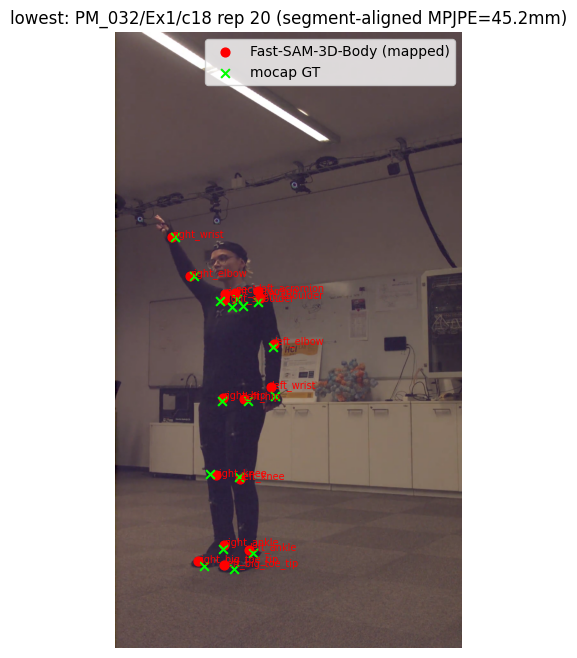

--- median: PM_029 / Ex6 / c17 / rep 7 (segment-aligned MPJPE=96.3mm) ---


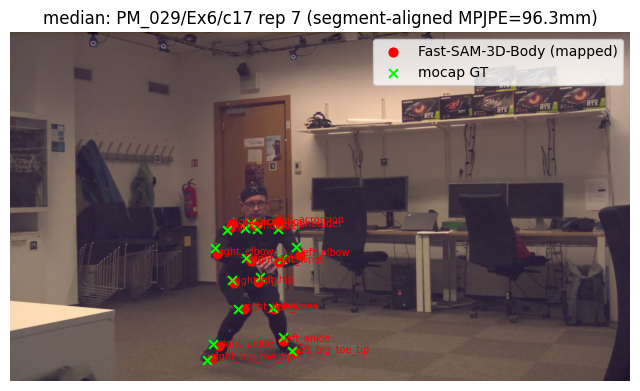

--- highest: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


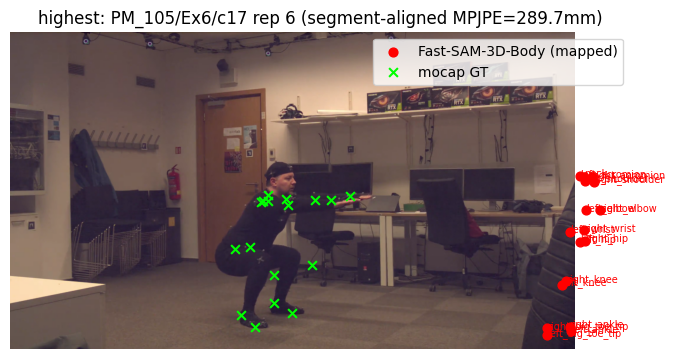

--- highest_c17: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


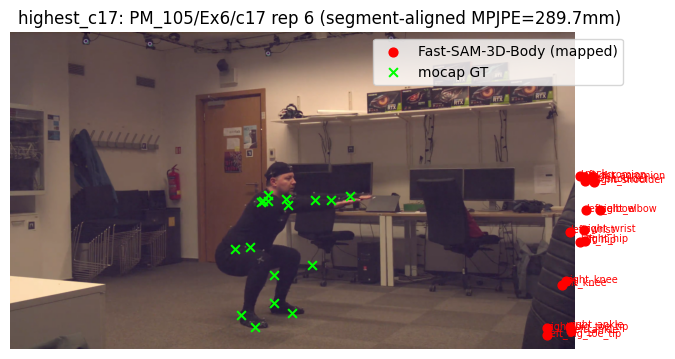

--- highest_c18: PM_025 / Ex2 / c18 / rep 7 (segment-aligned MPJPE=213.8mm) ---


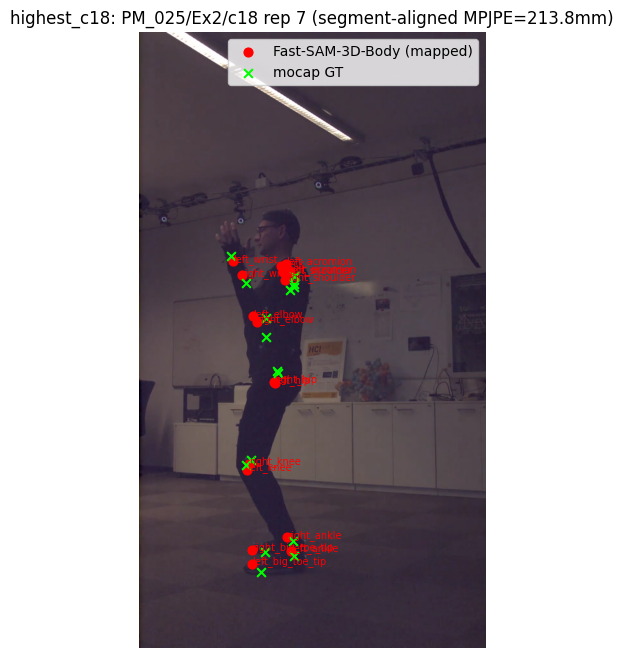

In [ ]:
# ============================================================
# Cell 22 - Systematic qualitative case selection (not hand-picked)
# ============================================================
# Selection rule: lowest-error, median-error, and highest-error repetition
# by segment-aligned MPJPE (overall mean across the 17 mapped joints), plus one
# representative case per camera -- an auditable rule instead of a manually
# chosen example. Reuses overlay_frame()/open_capture_at() from Cell 7.
# Ranked by SEGMENT-ALIGNED error, not root-relative: root-relative still
# contains the unreconciled pred/GT rotation (Cell 14 header), so ranking by it
# would select "worst" cases largely by how badly that rotation happened to
# align, not by genuine model failure.
ok_df_ranked = ok_df.assign(pa_mean_mm=ok_df[pa_cols].mean(axis=1)).sort_values("pa_mean_mm")

def pick_case(df, which):
    if which == "lowest":
        return df.iloc[0]
    if which == "highest":
        return df.iloc[-1]
    if which == "median":
        return df.iloc[len(df) // 2]
    raise ValueError(which)

cases = {}
for which in ["lowest", "median", "highest"]:
    cases[which] = pick_case(ok_df_ranked, which)
for cam in sorted(ok_df_ranked["camera"].unique()):
    cam_df = ok_df_ranked[ok_df_ranked["camera"] == cam]
    cases[f"highest_{cam}"] = pick_case(cam_df, "highest")

for name, row in cases.items():
    print(f"--- {name}: {row['subject']} / {row['exercise']} / {row['camera']} / rep {row['rep']} "
          f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm) ---")
    video_path = (f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera17-30fps.mp4"
                  if row["camera"] == "c17" else
                  f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera18-30fps-transposed.mp4")
    seg_start, seg_end = int(row["seg_start"]), int(row["seg_end"])
    mid = seg_start + (seg_end - seg_start) // 2
    try:
        gt2d = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{row['exercise']}/{row['subject']}-{row['camera']}-30fps.npy")
        pred_case = run_pipeline_on_video(video_path, seg_start, seg_end)
        overlay_frame(video_path, mid, pred_case, gt2d,
                      f"{name}: {row['subject']}/{row['exercise']}/{row['camera']} rep {row['rep']} "
                      f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm)")
    except Exception as e:
        print(f"  [warn] could not render overlay for this case: {e}")


--- lowest: PM_032 / Ex1 / c18 / rep 20 (segment-aligned MPJPE=45.2mm) ---


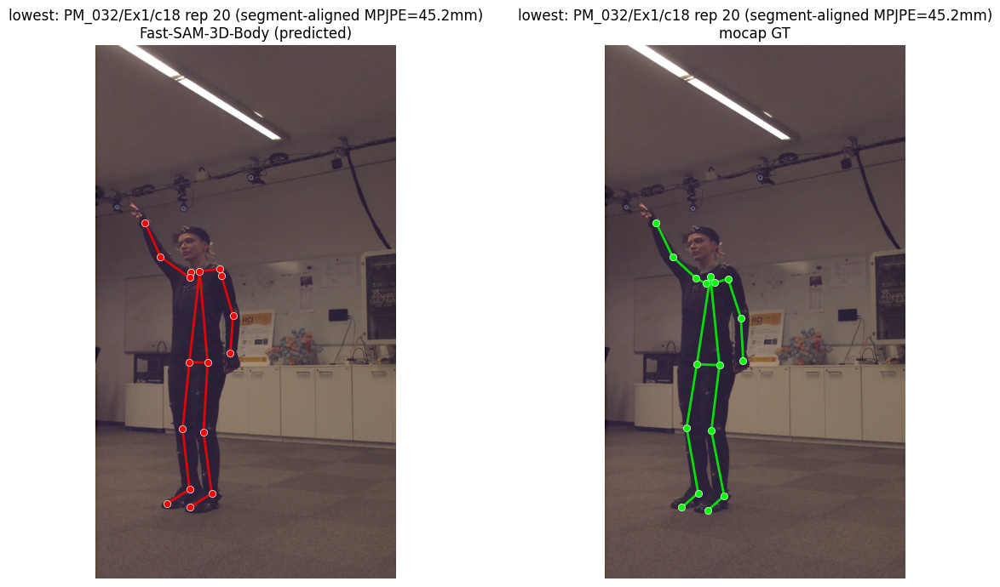

--- median: PM_029 / Ex6 / c17 / rep 7 (segment-aligned MPJPE=96.3mm) ---


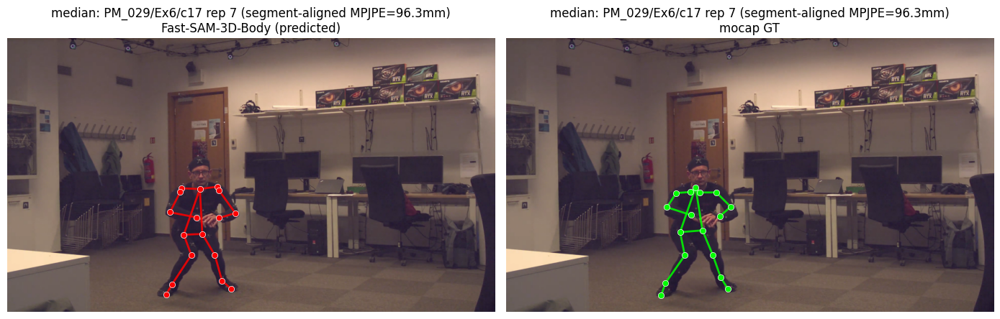

--- highest: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


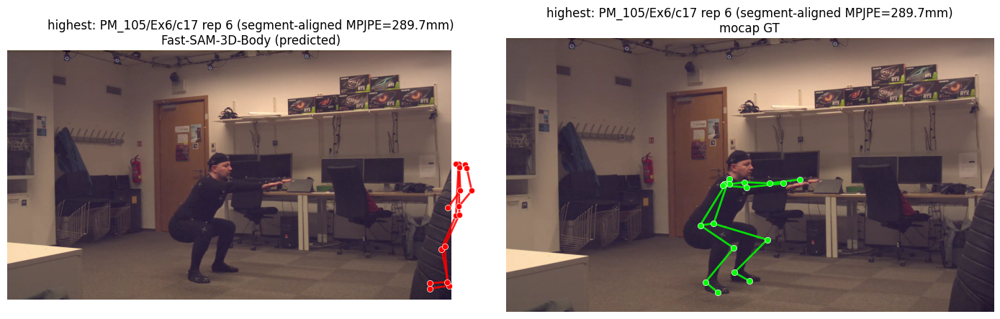

--- highest_c17: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


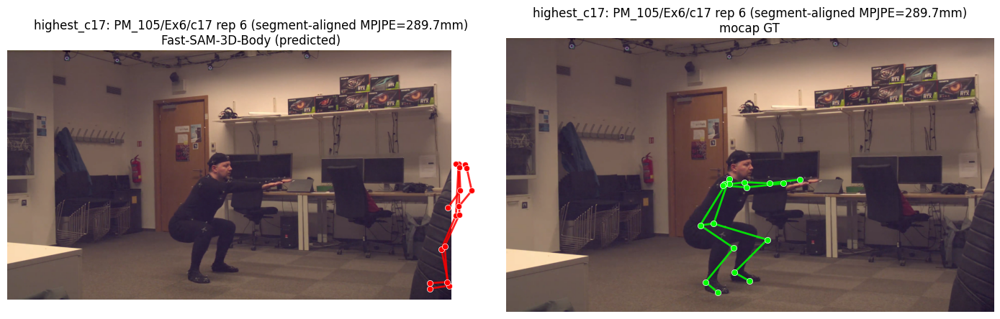

--- highest_c18: PM_025 / Ex2 / c18 / rep 7 (segment-aligned MPJPE=213.8mm) ---


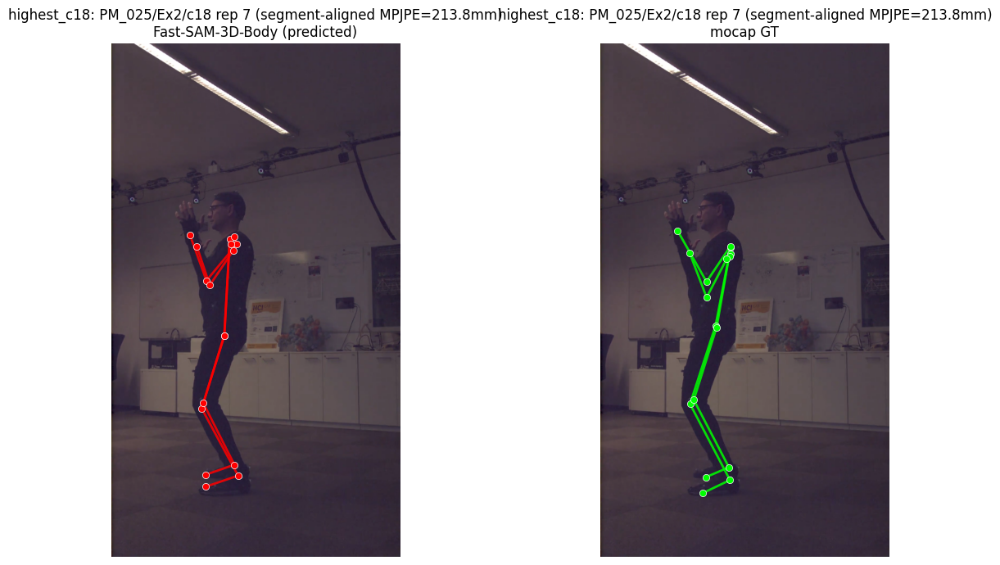

In [ ]:
# ============================================================
# Cell 22b - Same systematic cases, rendered as side-by-side skeletons
# ============================================================
# Reuses the exact `cases` dict Cell 22 already selected (lowest/median/
# highest segment-aligned MPJPE + worst-per-camera) -- no re-selection logic here, just
# a different renderer: compare_skeletons_side_by_side() from Cell 7c instead
# of overlay_frame() from Cell 7. Run Cell 22 first.
for name, row in cases.items():
    print(f"--- {name}: {row['subject']} / {row['exercise']} / {row['camera']} / rep {row['rep']} "
          f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm) ---")
    video_path = (f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera17-30fps.mp4"
                  if row["camera"] == "c17" else
                  f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera18-30fps-transposed.mp4")
    seg_start, seg_end = int(row["seg_start"]), int(row["seg_end"])
    mid = seg_start + (seg_end - seg_start) // 2
    try:
        gt2d = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{row['exercise']}/{row['subject']}-{row['camera']}-30fps.npy")
        pred_case = run_pipeline_on_video(video_path, seg_start, seg_end)
        compare_skeletons_side_by_side(
            video_path, mid, pred_case, gt2d,
            f"{name}: {row['subject']}/{row['exercise']}/{row['camera']} rep {row['rep']} "
            f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm)",
        )
    except Exception as e:
        print(f"  [warn] could not render side-by-side skeletons for this case: {e}")


--- lowest: PM_032 / Ex1 / c18 / rep 20 (segment-aligned MPJPE=45.2mm) ---


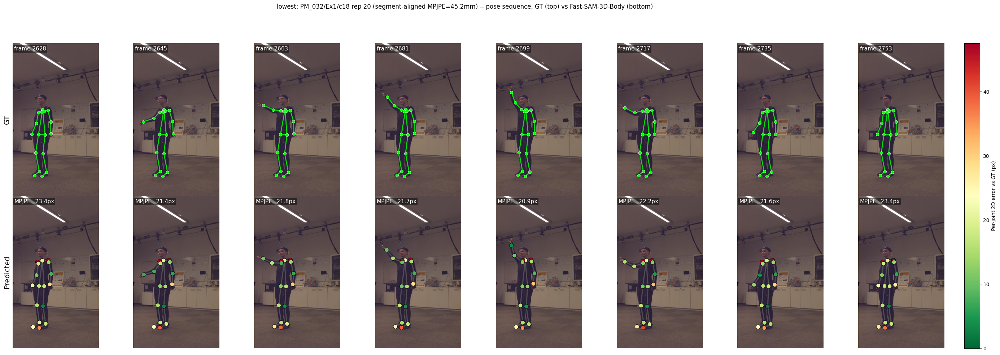

--- median: PM_029 / Ex6 / c17 / rep 7 (segment-aligned MPJPE=96.3mm) ---


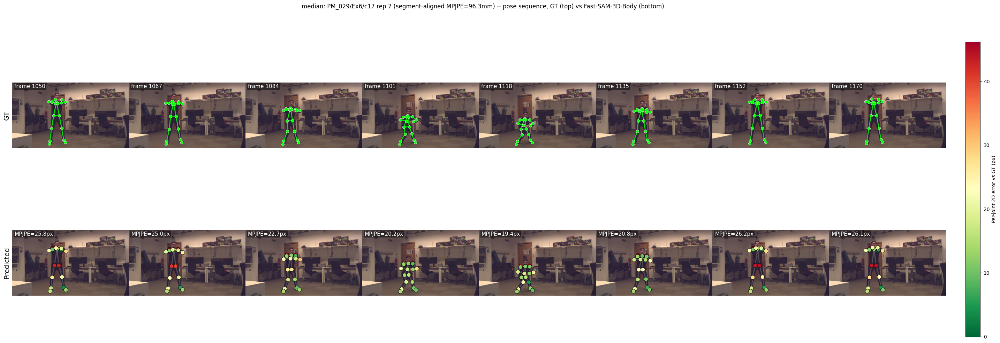

--- highest: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


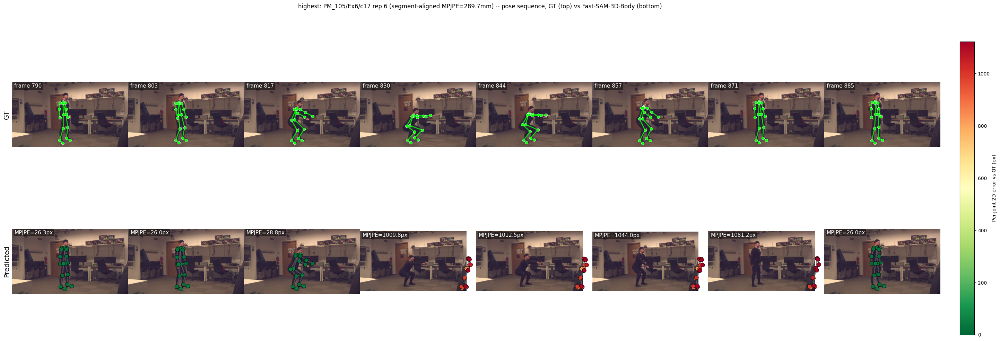

--- highest_c17: PM_105 / Ex6 / c17 / rep 6 (segment-aligned MPJPE=289.7mm) ---


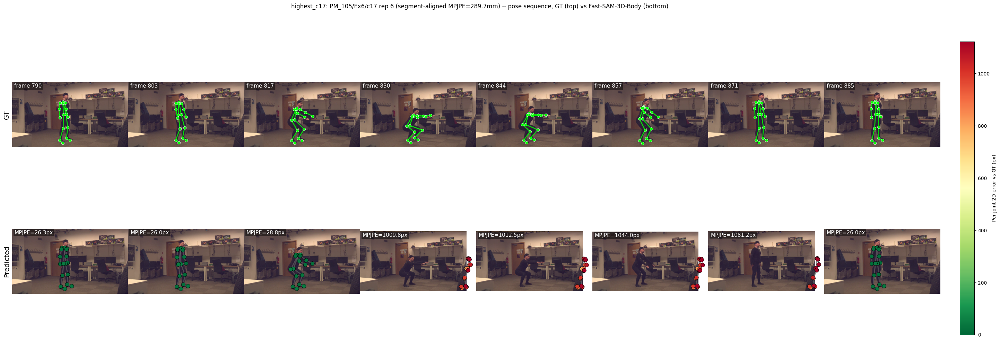

--- highest_c18: PM_025 / Ex2 / c18 / rep 7 (segment-aligned MPJPE=213.8mm) ---


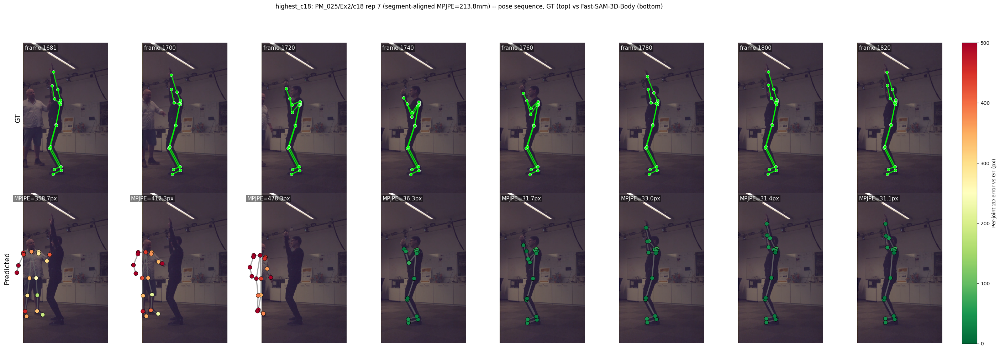

In [ ]:
# ============================================================
# Cell 22c - Same systematic cases, rendered as pose SEQUENCE comparisons
# ============================================================
# Reuses the exact `cases` dict Cell 22 already selected (lowest/median/
# highest segment-aligned MPJPE + worst-per-camera) -- no re-selection logic here, just
# a third renderer: visualize_pose_sequence() from Cell 7d (8-frame GT-top/
# predicted-bottom sequence with per-joint error color-coding) instead of
# overlay_frame() (Cell 22) or compare_skeletons_side_by_side() (Cell 22b).
# Run Cell 22 first.
for name, row in cases.items():
    print(f"--- {name}: {row['subject']} / {row['exercise']} / {row['camera']} / rep {row['rep']} "
          f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm) ---")
    video_path = (f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera17-30fps.mp4"
                  if row["camera"] == "c17" else
                  f"/content/drive/MyDrive/REHAB/videos/{row['exercise']}/{row['subject']}-Camera18-30fps-transposed.mp4")
    seg_start, seg_end = int(row["seg_start"]), int(row["seg_end"])
    try:
        gt2d = np.load(f"/content/drive/MyDrive/REHAB/2d_joints/{row['exercise']}/{row['subject']}-{row['camera']}-30fps.npy")
        pred_case = run_pipeline_on_video(video_path, seg_start, seg_end)
        visualize_pose_sequence(
            video_path, pred_case, gt2d, seg_start, seg_end,
            f"{name}: {row['subject']}/{row['exercise']}/{row['camera']} rep {row['rep']} "
            f"(segment-aligned MPJPE={row['pa_mean_mm']:.1f}mm)",
        )
    except Exception as e:
        print(f"  [warn] could not render pose sequence for this case: {e}")


In [ ]:
# ============================================================
# Cell 23 - Export all tables and figures to a Drive results folder
# ============================================================
# Writes every results table (CSV + Markdown + LaTeX) and every figure (PNG +
# PDF) into a timestamped folder on Drive, with a manifest recording the run
# configuration so a given set of numbers can be traced back to the run that
# produced it.
#
# FIGURES NEED ONE EXTRA STEP. Colab's inline backend CLOSES a figure when
# plt.show() returns, so by the time this cell runs the earlier figures no
# longer exist in memory and cannot be recovered. To capture them:
#
#     1. Run this cell once  -> tables are exported, figure autosave is armed
#     2. Re-run the figure cells you want (16b, 17b, 20, and any of 7/7c/7d/
#        12/22/22b/22c)  -> each figure is saved automatically as it is drawn
#     3. Call write_export_manifest() -- or re-run this cell -- to refresh the
#        manifest with the figure list. Re-running keeps the SAME export folder
#        and figure log; set NEW_EXPORT = True to start a fresh folder.
#
# Re-generating the plots inside this cell instead was rejected deliberately:
# it would duplicate the plotting code and let the exported figures drift out
# of sync with the ones in the notebook.

import os
import datetime as _dt
import matplotlib.pyplot as plt

EXPORT_ROOT = "/content/drive/MyDrive/REHAB/results/exports_fastsam"
NEW_EXPORT = False   # True: start a fresh timestamped folder and figure log
# Re-running this cell must NOT silently start a new folder: that used to
# orphan the figures already saved (and reset their log) while the
# instructions said re-running "refreshes the manifest".
_FRESH_EXPORT = NEW_EXPORT or "EXPORT_DIR" not in globals()
if _FRESH_EXPORT:
    RUN_TAG = _dt.datetime.now().strftime("%Y%m%d_%H%M%S")
    EXPORT_DIR = os.path.join(EXPORT_ROOT, f"run_{RUN_TAG}")
TABLES_DIR = os.path.join(EXPORT_DIR, "tables")
FIGURES_DIR = os.path.join(EXPORT_DIR, "figures")
for _d in (TABLES_DIR, FIGURES_DIR):
    os.makedirs(_d, exist_ok=True)

# ---------------------------------------------------------------- tables ---
# Maps the in-notebook variable name -> exported filename stem. Anything not
# defined yet (because its cell hasn't been run) is skipped with a note rather
# than raising, so a partial run still exports what it has.
TABLES_TO_EXPORT = {
    "spatial_table":            "T1_spatial_pose_accuracy",
    "temporal_table":           "T2_temporal_accuracy_mpjve",
    "feature_agreement_table":  "T3_kinematic_feature_agreement",
    "pooled_agreement_table":   "T4_pooling_guardrail",
    "correctness_auroc_table":  "T5_correctness_auroc",
    "runtime_table":            "T6_runtime_components",
    "runtime_ab_table":         "T7_runtime_batched_vs_unbatched",
    "batch_df":                 "RAW_all_rows",
    "ok_df":                    "RAW_usable_rows",
}

exported_tables, missing_tables = [], []
for var_name, stem in TABLES_TO_EXPORT.items():
    obj = globals().get(var_name)
    if obj is None or not isinstance(obj, pd.DataFrame) or len(obj) == 0:
        missing_tables.append(var_name)
        continue

    df_out = obj.copy()
    # The per-frame latency columns are Python lists -- fine in CSV, but they
    # make Markdown/LaTeX unreadable, so drop them from the typeset versions.
    typeset = df_out.drop(columns=[c for c in ("detector_ms", "hmr_ms") if c in df_out.columns])

    csv_path = os.path.join(TABLES_DIR, f"{stem}.csv")
    df_out.to_csv(csv_path, index=False)

    with open(os.path.join(TABLES_DIR, f"{stem}.md"), "w", encoding="utf-8") as f:
        f.write(f"# {stem}\n\n_Exported {RUN_TAG} from {var_name}_\n\n")
        f.write(typeset.to_markdown(index=False))
        f.write("\n")

    try:
        with open(os.path.join(TABLES_DIR, f"{stem}.tex"), "w", encoding="utf-8") as f:
            f.write(typeset.to_latex(index=False, float_format="%.3f", escape=True))
    except Exception as e:
        print(f"  [warn] LaTeX export skipped for {var_name}: {e}")

    exported_tables.append((var_name, stem, len(df_out), len(df_out.columns)))

print(f"Tables -> {TABLES_DIR}")
for var_name, stem, nrow, ncol in exported_tables:
    print(f"  {stem:38s} ({nrow} rows x {ncol} cols)  [from {var_name}]")
if missing_tables:
    print(f"  not exported (cell not run / empty): {', '.join(missing_tables)}")

# --------------------------------------------------------------- figures ---
if _FRESH_EXPORT or "_figure_log" not in globals():
    _figure_log = []

def _export_figure(fig=None, name=None):
    """Save one figure as PNG (300 dpi) + PDF (vector, for the paper)."""
    fig = fig or plt.gcf()
    if not fig.get_axes():
        return None
    idx = len(_figure_log) + 1
    if name is None:
        title = fig._suptitle.get_text() if fig._suptitle else (
            fig.get_axes()[0].get_title() or "figure")
        name = "".join(ch if ch.isalnum() or ch in "-_ " else "" for ch in title).strip()
        name = ("_".join(name.split()) or "figure")[:60]
    stem = f"F{idx:02d}_{name}"
    png = os.path.join(FIGURES_DIR, f"{stem}.png")
    pdf = os.path.join(FIGURES_DIR, f"{stem}.pdf")
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    _figure_log.append(stem)
    print(f"  [figure saved] {stem}")
    return stem

if not globals().get("_FIGURE_AUTOSAVE_ARMED", False):
    _original_plt_show = plt.show

    def _show_and_save(*args, **kwargs):
        try:
            _export_figure()
        except Exception as e:
            print(f"  [warn] figure export failed: {e}")
        return _original_plt_show(*args, **kwargs)

    plt.show = _show_and_save
    _FIGURE_AUTOSAVE_ARMED = True
    print(f"\nFigure autosave ARMED -> {FIGURES_DIR}")
    print("  Re-run the figure cells (16b, 17b, 20, and any of 7/7c/7d/12/22/22b/22c)")
    print("  and each figure will be written as it is drawn.")
else:
    print(f"\nFigure autosave already armed -> {FIGURES_DIR}")

# -------------------------------------------------------------- manifest ---
def write_export_manifest():
    """Record what was exported and under what configuration, so any number in
    these files can be traced back to the run that produced it."""
    lines = [
        f"Fast-SAM-3D-Body evaluation export",
        f"exported_at: {_dt.datetime.now().isoformat(timespec='seconds')}",
        f"run_tag: {RUN_TAG}",
        "",
        "--- configuration ---",
    ]
    for var in ("BATCH_SEED", "N_SEGMENTS_PER_SUBJECT", "MAX_SUBJECTS", "BATCH_EXERCISES",
                "EXERCISE_FILTER", "TIME_BUDGET_HOURS", "N_RUNTIME_COMPARISON_SEGMENTS",
                "N_AXIS_CALIB_SEGMENTS", "CCC_POOR_THRESHOLD", "CCC_GAP_FLAG",
                "LOG_FULL_TRANSFORM", "MODEL_TAG", "RUNTIME_ARM_LABEL",
                "ACCEL_CONFIG", "HF_REPO_ID", "DETECTOR_NAME", "DETECTOR_MODEL",
                "USE_MASK", "HAND_BOX_SOURCE", "KP2D_SOURCE", "GPU_NAME",
                "ACCEL_HASH", "USE_TRT", "QUIET_INFERENCE",
                "CACHE_KEY", "FOV_MODE", "N_CALIB_FRAMES", "N_WORKERS", "PRED_CACHE_DIR",
                "INFERENCE_TYPE", "ROM_MIN_COVERAGE"):
        if var in globals():
            lines.append(f"{var}: {globals()[var]}")

    if isinstance(globals().get("batch_df"), pd.DataFrame):
        bdf = globals()["batch_df"]
        lines += [
            "",
            "--- dataset coverage ---",
            f"rows: {len(bdf)}",
            f"repetitions: {len(bdf[['exercise','subject','rep']].drop_duplicates())}",
            f"recording_ids: {bdf['subject'].nunique()}  "
            f"(NOT verified participants -- REHAB24-6 documents ~10)",
            f"exercises: {sorted(bdf['exercise'].unique().tolist())}",
            "",
            "--- status breakdown ---",
        ]
        lines += [f"{k}: {v}" for k, v in bdf["status"].value_counts().items()]

    lines += ["", "--- tables ---"] + [f"{s}.csv/.md/.tex  ({n} rows)" for _, s, n, _ in exported_tables]
    lines += ["", "--- figures ---"] + ([f"{s}.png/.pdf" for s in _figure_log] or
                                         ["(none yet -- re-run the figure cells with autosave armed)"])
    lines += [
        "",
        "--- interpretation notes that travel with these numbers ---",
        "* MODEL: Fast-SAM-3D-Body with the configuration recorded above (ACCEL_CONFIG:",
        "  pruned intermediate predictions, MHR correctives disabled, etc.). NOT",
        "  equivalent to an unmodified SAM 3D Body teacher run.",
        f"* FOV_MODE={globals().get('FOV_MODE')}: 'per-video' = intrinsics calibrated OFFLINE from",
        "  frames across the whole video (incl. future frames), then frozen. The",
        "  intrinsics condition the network, so this can change predicted 3D pose;",
        "  Cell 12b quantifies it. Runtime is 'after offline calibration'.",
        f"* INFERENCE_TYPE={globals().get('INFERENCE_TYPE')}; person selection: IoU tracking per segment.",
        f"* ROM agreement uses repetitions with >= {globals().get('ROM_MIN_COVERAGE')} valid-frame coverage;",
        "  *_matched columns give a matched-temporal-support supplementary comparison.",
        "* Cell 16c is a LIMITED diagnostic (axis permutations only), not an identified",
        "  camera-to-world transform.",
        "* root_mpjpe_mm is translation-only aligned and still contains an unreconciled",
        "  pred/GT rotation -- not a tracking-accuracy number unless Cell 16c identified",
        "  a consistent axis convention. Prefer pa_mpjpe_mm.",
        "* pa_mpjpe_mm is SEGMENT-LEVEL aligned (one fixed fit per segment), not the",
        "  per-frame-refit PA-MPJPE convention used in most benchmarks -- not directly",
        "  comparable to per-frame PA-MPJPE reported elsewhere.",
        "* mpjve_mms is ROOT-RELATIVE (limb articulation). Global-translation MPJVE is",
        "  not reported: the pipeline discards cam_trans, so predictions carry no global",
        "  translation.",
        "* AUROC is EXPLORATORY: score direction is chosen from the GT feature on the same",
        "  data (so AUROC_gt >= 0.5 by construction, optimistic) and applied identically",
        "  to the predicted feature; BELOW 0.5 = reversed relationship.",
        "* CIs bootstrap over RECORDING IDs; Spearman/Wilcoxon use recording-aggregated",
        "  data. Recording IDs are not verified participant IDs.",
        "* Runtime component timers exclude preprocessing/decode; cite wall_clock_fps",
        "  (Cell 21b) for deployability, not the component reciprocal.",
    ]

    manifest_path = os.path.join(EXPORT_DIR, "MANIFEST.txt")
    with open(manifest_path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")
    print(f"\nManifest -> {manifest_path}")
    return manifest_path

write_export_manifest()
print(f"\nExport folder: {EXPORT_DIR}")
print("After re-running figure cells, call write_export_manifest() (or re-run this cell --")
print("same folder, same figure log) to refresh the manifest's figure list.")


Tables -> /content/drive/MyDrive/REHAB/results/exports_fastsam/run_20260920_041824/tables
  T1_spatial_pose_accuracy               (12 rows x 11 cols)  [from spatial_table]
  T2_temporal_accuracy_mpjve             (12 rows x 7 cols)  [from temporal_table]
  T3_kinematic_feature_agreement         (48 rows x 18 cols)  [from feature_agreement_table]
  T4_pooling_guardrail                   (8 rows x 7 cols)  [from pooled_agreement_table]
  T5_correctness_auroc                   (12 rows x 16 cols)  [from correctness_auroc_table]
  T6_runtime_components                  (1 rows x 9 cols)  [from runtime_table]
  T7_runtime_batched_vs_unbatched        (1 rows x 13 cols)  [from runtime_ab_table]
  RAW_all_rows                           (2144 rows x 114 cols)  [from batch_df]
  RAW_usable_rows                        (2144 rows x 114 cols)  [from ok_df]

Figure autosave ARMED -> /content/drive/MyDrive/REHAB/results/exports_fastsam/run_20260920_041824/figures
  Re-run the figure cells (16b, 17b,

## Part 3: ROM agreement figures (batch)

Cells 16b / 17b / 20 cover spatial and temporal error, but ROM agreement --
the finding this evaluation actually supports -- existed only as tables
(Cells 18 / 18b). These three cells add the missing figures.

Requires the batch cells (15 or 15b-15d) and Cell 18 to have run:
they use `ok_df` and `concordance_corr_coef`.

Note these come AFTER the export cell (23) on purpose: run 23 first to arm
figure autosave, then run these, and each is written to Drive as it is drawn.


  [figure saved] F01_ROM_agreement_by_exercise_--_right_upperarm_trunk_points_on_


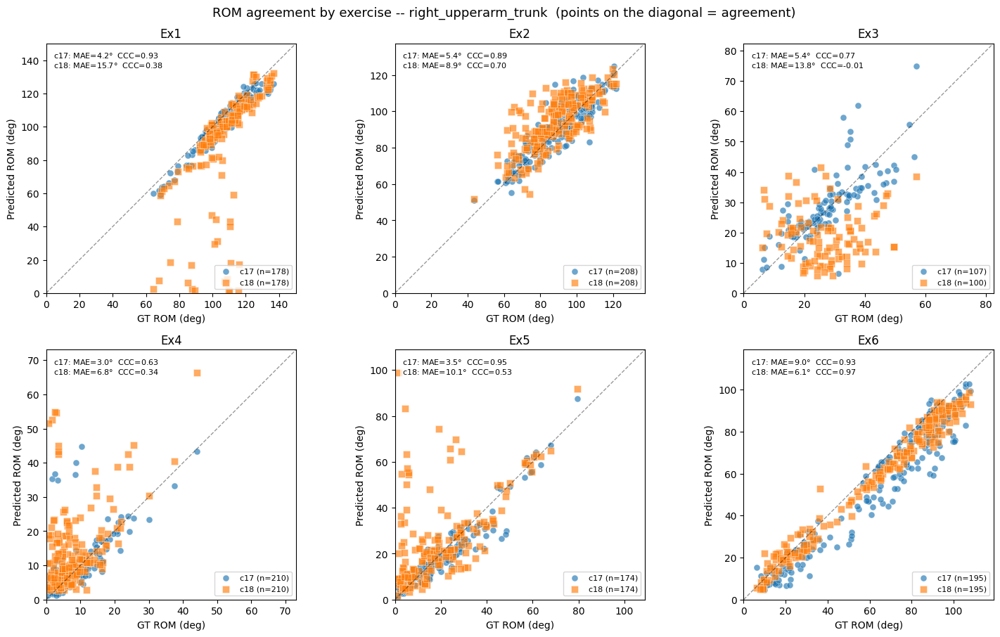

  [figure saved] F02_ROM_agreement_by_exercise_--_right_elbow_points_on_the_diago


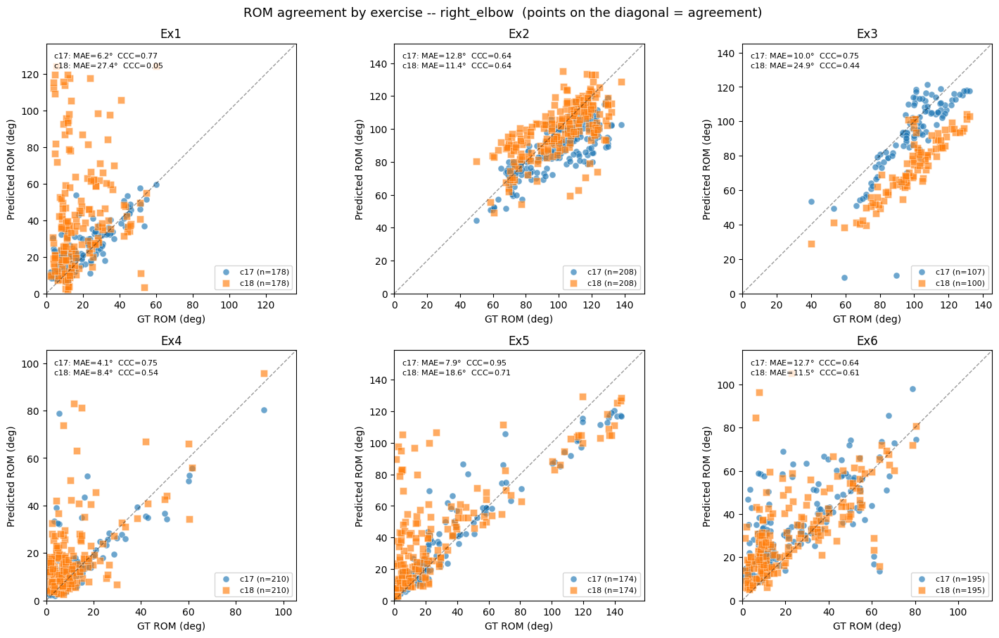

  [figure saved] F03_ROM_agreement_by_exercise_--_left_upperarm_trunk_points_on_t


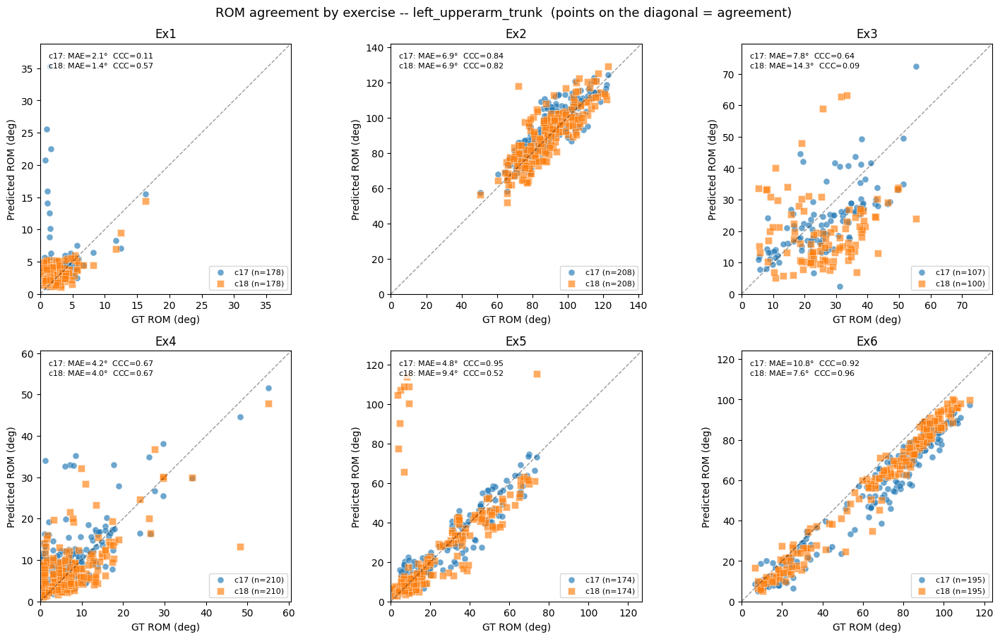

  [figure saved] F04_ROM_agreement_by_exercise_--_left_elbow_points_on_the_diagon


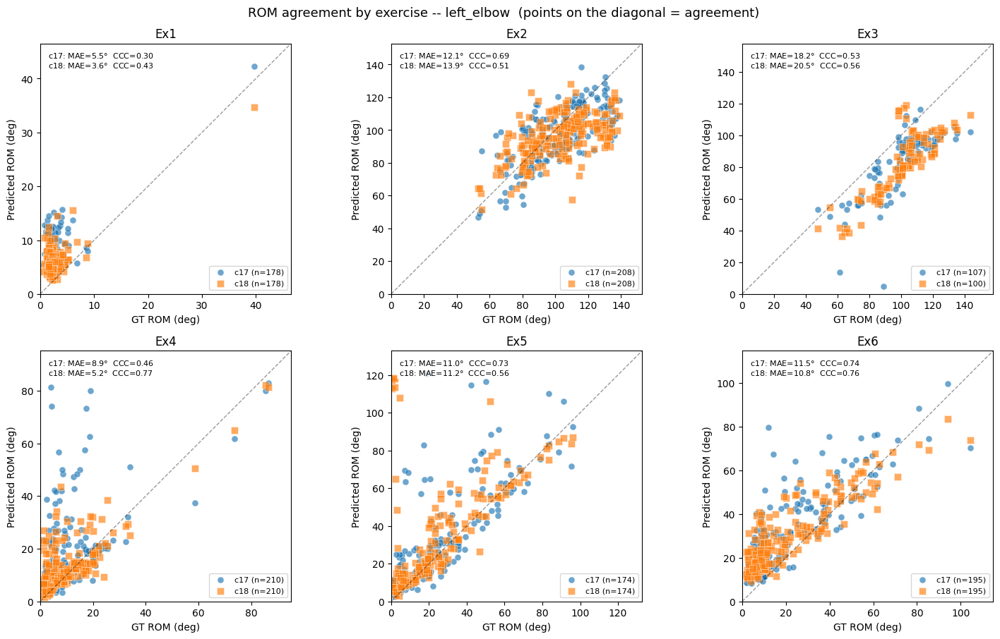

In [ ]:
# ============================================================
# Cell 24a - ROM agreement scatter, faceted by exercise, coloured by camera
# ============================================================
# Predicted vs GT ROM per repetition, one panel per exercise, with the
# identity line. This is the direct visual of Cell 18's table: a tight cloud
# on the diagonal means the model reproduces between-repetition variation;
# a horizontal/compressed cloud means it does not, even if MAE looks modest.
ROM_FIG_FEATURES = FEATURE_KEYS   # all four; narrow this to shorten the output

exercises_sorted = sorted(ok_df["exercise"].unique())
cam_style = {"c17": ("tab:blue", "o"), "c18": ("tab:orange", "s")}

for key in ROM_FIG_FEATURES:
    pred_col, gt_col = f"ROM_pred_{key}_deg", f"ROM_gt_{key}_deg"
    ncols = 3
    nrows = int(np.ceil(len(exercises_sorted) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.6 * nrows), squeeze=False)

    for ax_i, ex in enumerate(exercises_sorted):
        ax = axes[ax_i // ncols][ax_i % ncols]
        sub_ex = ok_df[ok_df["exercise"] == ex]

        vals = np.concatenate([sub_ex[pred_col].values, sub_ex[gt_col].values])
        vals = vals[np.isfinite(vals)]
        lim = (0, (np.nanmax(vals) * 1.1) if len(vals) else 1)

        annots = []
        for cam, (colour, marker) in cam_style.items():
            s = sub_ex[sub_ex["camera"] == cam]
            if len(s) == 0:
                continue
            ax.scatter(s[gt_col], s[pred_col], c=colour, marker=marker,
                       alpha=0.65, s=42, edgecolors="white", linewidths=0.4,
                       label=f"{cam} (n={int(s[[pred_col, gt_col]].notna().all(axis=1).sum())})")
            _s = s.dropna(subset=[pred_col, gt_col])             # coverage gate
            mae = np.abs(_s[pred_col].values - _s[gt_col].values).mean() if len(_s) else np.nan
            ccc = concordance_corr_coef(_s[pred_col].values, _s[gt_col].values) if len(_s) > 1 else np.nan
            annots.append(f"{cam}: MAE={mae:.1f}$\\degree$  CCC={ccc:.2f}")

        ax.plot(lim, lim, "k--", alpha=0.4, linewidth=1)
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(ex, fontsize=12)
        ax.set_xlabel("GT ROM (deg)")
        ax.set_ylabel("Predicted ROM (deg)")
        if annots:
            ax.text(0.03, 0.97, "\n".join(annots), transform=ax.transAxes,
                    va="top", ha="left", fontsize=8,
                    bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=2))
        ax.legend(loc="lower right", fontsize=8)

    for ax_i in range(len(exercises_sorted), nrows * ncols):
        axes[ax_i // ncols][ax_i % ncols].axis("off")

    fig.suptitle(f"ROM agreement by exercise -- {key}  (points on the diagonal = agreement)",
                 fontsize=13)
    plt.tight_layout()
    plt.show()


  [figure saved] F05_ROM_agreement_CCC_by_exercise_x_camera_x_feature


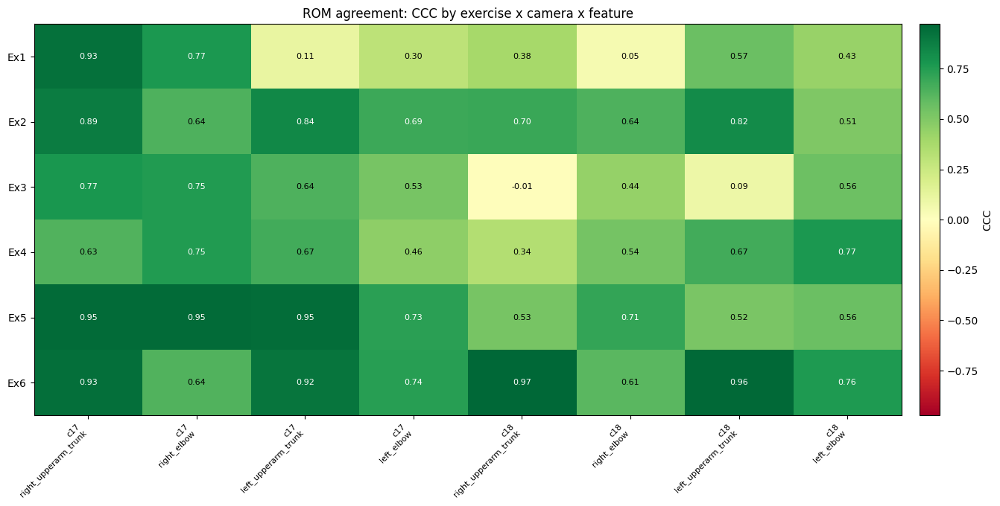

  [figure saved] F06_ROM_agreement_MAE_deg_by_exercise_x_camera_x_feature


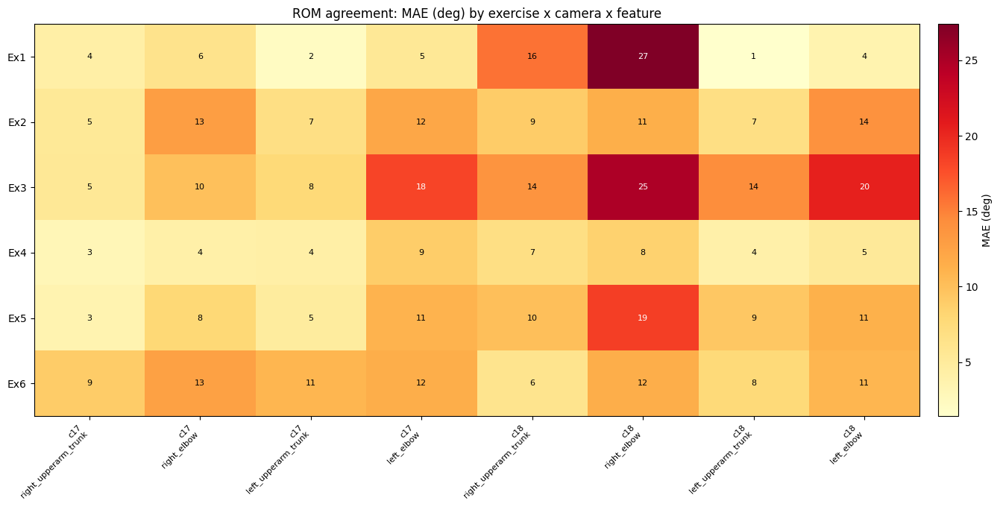

In [ ]:
# ============================================================
# Cell 24b - CCC and MAE heatmaps: exercise x camera x feature
# ============================================================
# The whole of Cell 18's agreement table in one view. CCC uses a diverging
# scale centred on 0 because CCC can go negative (no agreement beyond chance
# alignment of the means); MAE uses a sequential scale where darker is worse.
def _agreement_grid(metric):
    rows = []
    for ex in sorted(ok_df["exercise"].unique()):
        row = {"exercise": ex}
        for cam in sorted(ok_df["camera"].unique()):
            s_cam = ok_df[(ok_df["exercise"] == ex) & (ok_df["camera"] == cam)]
            for key in FEATURE_KEYS:
                _k = s_cam.dropna(subset=[f"ROM_pred_{key}_deg", f"ROM_gt_{key}_deg"])  # coverage gate
                p = _k[f"ROM_pred_{key}_deg"].values
                g = _k[f"ROM_gt_{key}_deg"].values
                if len(p) < 2:
                    row[f"{cam}\n{key}"] = np.nan
                elif metric == "CCC":
                    row[f"{cam}\n{key}"] = concordance_corr_coef(p, g)
                else:
                    row[f"{cam}\n{key}"] = np.abs(p - g).mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("exercise")

for metric, cmap, centre in [("CCC", "RdYlGn", True), ("MAE (deg)", "YlOrRd", False)]:
    grid = _agreement_grid("CCC" if metric == "CCC" else "MAE")
    fig, ax = plt.subplots(figsize=(1.45 * len(grid.columns) + 2, 0.75 * len(grid) + 2.4))
    data = grid.values.astype(float)
    if centre:
        vmax = np.nanmax(np.abs(data)) if np.isfinite(data).any() else 1.0
        im = ax.imshow(data, cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")
    else:
        im = ax.imshow(data, cmap=cmap, aspect="auto")

    ax.set_xticks(range(len(grid.columns)))
    ax.set_xticklabels(grid.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(grid)))
    ax.set_yticklabels(grid.index, fontsize=10)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            if np.isfinite(v):
                # pick text colour by cell darkness so annotations stay readable
                rgba = im.cmap(im.norm(v))
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                ax.text(j, i, f"{v:.2f}" if metric == "CCC" else f"{v:.0f}",
                        ha="center", va="center", fontsize=8,
                        color="white" if lum < 0.5 else "black")
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label=metric)
    ax.set_title(f"ROM agreement: {metric} by exercise x camera x feature", fontsize=12)
    plt.tight_layout()
    plt.show()


  [figure saved] F07_Ground-truth_ROM_variability_per_exercise_--_right_upperarm_


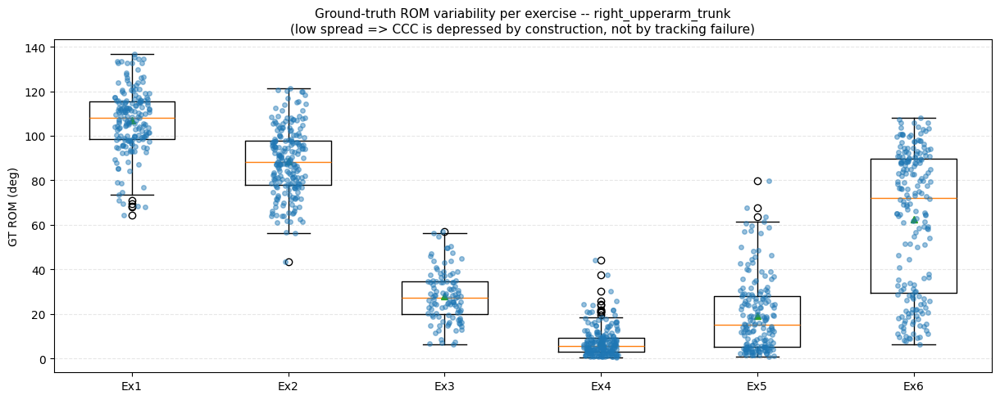

  [figure saved] F08_Ground-truth_ROM_variability_per_exercise_--_right_elbowlow_


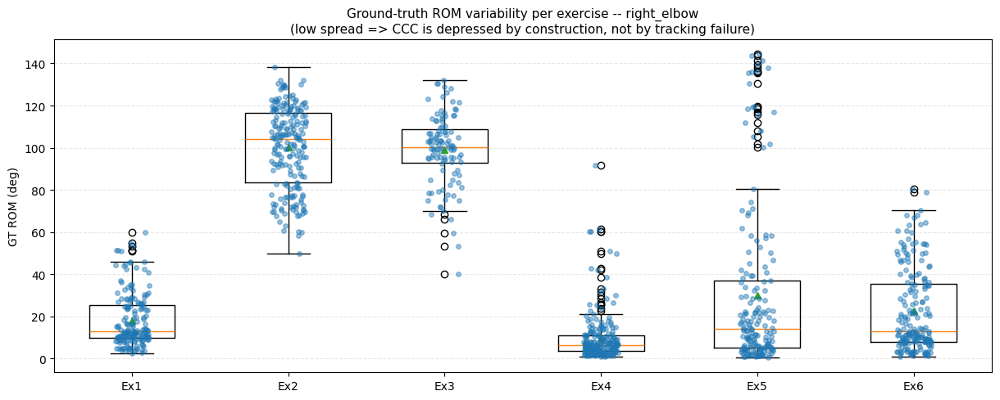

  [figure saved] F09_Ground-truth_ROM_variability_per_exercise_--_left_upperarm_t


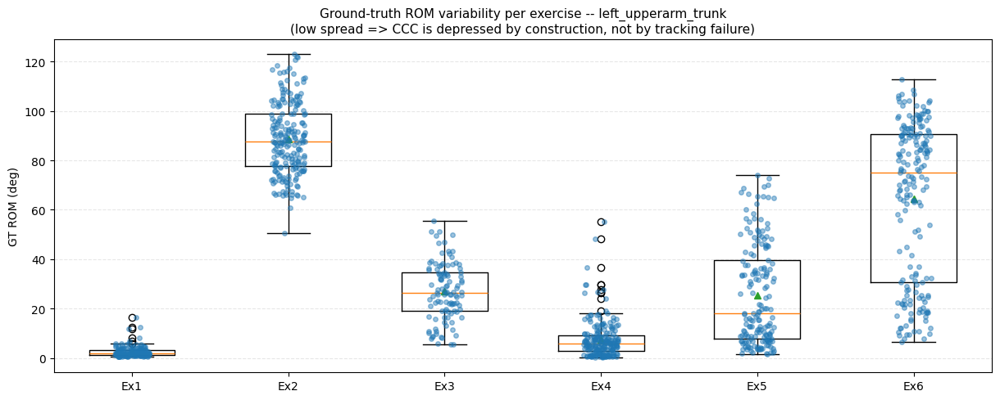

  [figure saved] F10_Ground-truth_ROM_variability_per_exercise_--_left_elbowlow_s


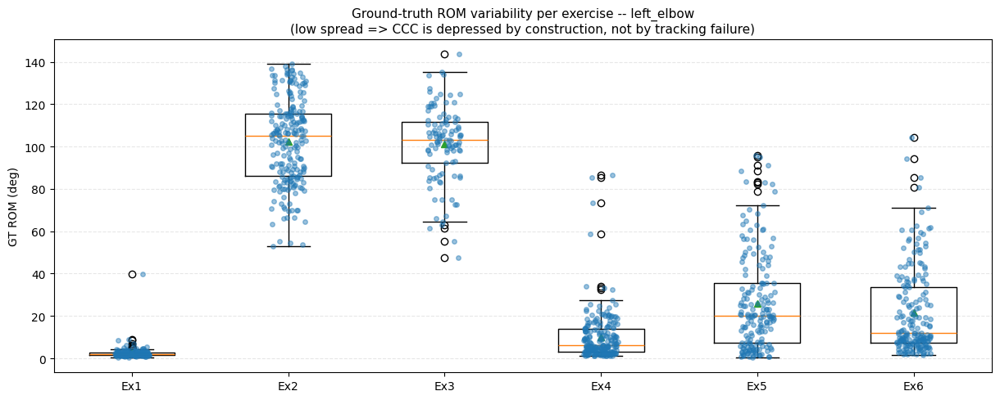

GT ROM spread per exercise (de-duplicated across cameras):
exercise  n_reps  right_upperarm_trunk_mean  right_upperarm_trunk_SD  right_elbow_mean  right_elbow_SD  left_upperarm_trunk_mean  left_upperarm_trunk_SD  left_elbow_mean  left_elbow_SD
     Ex1     178                     106.97                    14.16             18.18           12.57                      2.40                    2.04             2.53           3.06
     Ex2     208                      88.49                    14.83            100.10           19.26                     88.50                   14.38           102.45          20.03
     Ex3     107                      27.89                    11.30             99.11           16.95                     26.91                   11.54           101.35          17.69
     Ex4     210                       7.34                     6.45             10.01           11.80                      7.36                    7.51            10.15          11.71
     Ex5     174

In [ ]:
# ============================================================
# Cell 24c - GT ROM variability per exercise (settles low-CCC interpretation)
# ============================================================
# CCC is a ratio: when the REFERENCE barely varies between repetitions, CCC
# collapses toward 0 no matter how good the tracking is, because there is
# almost no between-repetition variation left to reproduce. So a near-zero
# CCC alongside a modest MAE (Ex4 is the case in point) is ambiguous until
# you look at the GT spread. This distinguishes the two.
#
# GT ROM is derived from the single triangulated 3D mocap file, which is
# SHARED by both camera views -- so c17 and c18 rows of the same repetition
# carry identical GT. They are de-duplicated here; counting both would halve
# the apparent variance's standard error and misstate n.
gt_unique = ok_df.drop_duplicates(subset=["subject", "exercise", "rep"])
exercises_sorted = sorted(gt_unique["exercise"].unique())

for key in FEATURE_KEYS:
    gt_col = f"ROM_gt_{key}_deg"
    fig, ax = plt.subplots(figsize=(1.55 * len(exercises_sorted) + 3, 5))
    data = [gt_unique[gt_unique["exercise"] == ex][gt_col].dropna().values
            for ex in exercises_sorted]
    bp = ax.boxplot(data, labels=exercises_sorted, showmeans=True, widths=0.55)
    for i, d in enumerate(data, start=1):
        if len(d):
            ax.scatter(np.full(len(d), i) + np.random.uniform(-0.11, 0.11, len(d)),
                       d, s=16, alpha=0.45, color="tab:blue", zorder=3)
    ax.set_ylabel("GT ROM (deg)")
    ax.set_title(f"Ground-truth ROM variability per exercise -- {key}\n"
                 f"(low spread => CCC is depressed by construction, not by tracking failure)",
                 fontsize=11)
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    plt.tight_layout()
    plt.show()

# The numbers behind the figure, since the SD is the thing you actually cite.
print("GT ROM spread per exercise (de-duplicated across cameras):")
summary_rows = []
for ex in exercises_sorted:
    sub_ex = gt_unique[gt_unique["exercise"] == ex]
    row = {"exercise": ex, "n_reps": len(sub_ex)}
    for key in FEATURE_KEYS:
        v = sub_ex[f"ROM_gt_{key}_deg"].dropna()
        row[f"{key}_mean"] = v.mean()
        row[f"{key}_SD"] = v.std(ddof=1) if len(v) > 1 else np.nan
    summary_rows.append(row)
gt_rom_spread_table = pd.DataFrame(summary_rows)
print(gt_rom_spread_table.to_string(index=False, float_format=lambda x: f"{x:7.2f}"))
print()
print("Read alongside Cell 18's CCC column: an exercise with a LOW SD here and a")
print("low CCC there is showing limited reference variation, not necessarily poor")
print("tracking. An exercise with a HIGH SD and low CCC is a genuine tracking failure.")
